# HST Corpus 80m Analysis

- Creator: Sebastian Birk (sb75@sanger.ac.uk)
- Date of Creation: 21.02.2025
- Date of Last Modification: 11.08.2025 (by Sebastian Birk; sb75@sanger.ac.uk)

# 1. Setup

## 1.1 Load Libraries 

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import sys
sys.path.append("../../utils")

In [3]:
import logging
import math
import os
import re
import warnings
import pickle
import random
from collections import defaultdict
from datetime import datetime
from itertools import chain

import anndata as ad
import celltypist
import torch
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scanpy as sc
import scib_metrics
import seaborn as sns
import squidpy as sq
from datasets import concatenate_datasets, load_from_disk
from scipy.sparse import csr_matrix
from sklearn.metrics.cluster import adjusted_rand_score, normalized_mutual_info_score
from sklearn.model_selection import train_test_split

from app.infer import get_gene_embed, infer
from app.train import train
from nichejepa.datasets import prepare_dataset
from nichejepa.utils.config import create_params_from_YAML_wandb_config
from nichejepa.utils.distributed import init_distributed
from nichejepa.utils.embedding import collect_adata_from_folder
from nichejepa.utils.evaluation import clustering_metrics, classification_metrics

from analysis_utils import *

/nfs/users/nfs_s/sb75/.venvs/nichejepa/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
JAX version 0.6.1 available.


## 1.2 Load Config/Params
All setup will be done in the config file. Please edit that file to continue.

In [4]:
# Set params
dataset = 'hst_corpus_80m'
tokenizer = 'cell_graph'
# load_timestamp = '03072025_001818_175'
# load_timestamp = '11062025_183320_055'
load_timestamp = '18062025_082526_412' # '29062025_202056_303'
# load_timestamp = '18062025_082526_412'
model_type = 'test'
read_checkpoint = 'nichejepa-ep16_0.pth.tar' # 'nichejepa-ep3_0.pth.tar', 'nichejepa-ep10_0.pth.tar'
aws_run = False

emb_layer = None
n_layer = 12
top_k = None
batch_size = 128
pin_memory = False
num_workers = 12
n_pcs = 0

In [5]:
# Define paths
model_config_folder_path = '/nfs/team361/sb75/nichejepa/configs/model' # '/nfs/team361/sb75/nichejepa/configs/model' # '/lustre/scratch126/cellgen/team361/sb75/nichejepa/configs/model'
artifacts_folder_path = '/nfs/team361/sb75/nichejepa-reproducibility/artifacts' # '/nfs/team361/sb75/nichejepa-reproducibility/artifacts' # '/nfs/team361/sb75/nichejepa-reproducibility/artifacts' # '/lustre/scratch126/cellgen/lotfollahi/sb75/nichejepa-reproducibility/artifacts' # '/nfs/team361/sb75/nichejepa-reproducibility/artifacts'
datasets_folder_path = '/nfs/team361/sb75/DATASETS' # '/lustre/scratch126/cellgen/team361/DATASETS'
token_dict_path = f'{datasets_folder_path}/tokenizer/token_dictionary_homo_sapiens.pkl'
model_folder_path = f'/nfs/team361/sb75/nichejepa-reproducibility/artifacts/models/{load_timestamp}'
raw_data_folder_path = f'/nfs/team361/sb75/DATASETS/silver/{dataset}'

# Define folder path for saving and loading artifacts
if not load_timestamp:
    current_timestamp = (
        datetime.now().strftime("%d%m%Y_%H%M%S") +
        f"_{datetime.now().microsecond // 1000:03d}")
    folder_path = os.path.join(artifacts_folder_path,
                               params['data']['dataset_name'],
                               current_timestamp)
else:
    folder_path = f'{artifacts_folder_path}/{dataset}/{load_timestamp}'
    
folder_path

'/nfs/team361/sb75/nichejepa-reproducibility/artifacts/hst_corpus_80m/18062025_082526_412'

In [6]:
# Set up logger
rank=0
logging.basicConfig()
logger = logging.getLogger()
logger.setLevel(logging.INFO if rank == 0 else logging.ERROR)

In [7]:
# Load config
if not load_timestamp:
    params = create_params_from_YAML_wandb_config(f'{model_config_folder_path}/{dataset}_{model_type}.yaml',logger)
else:
    params = create_params_from_YAML_wandb_config(f'{artifacts_folder_path}/{dataset}/{load_timestamp}/params.yaml',logger)

if read_checkpoint:
    params['state']['read_checkpoint'] = read_checkpoint
if load_timestamp:
    params['state']['load_checkpoint'] = True

params

Loaded parameters from YAML file.


{'data': {'batch_size': 144,
  'dataset_name': 'hst_corpus_80m',
  'n_segments': 11,
  'num_workers': 48,
  'pin_memory': True,
  'precomputed_epoch_n_nonzero_tokens': '/lustre/scratch126/cellgen/lotfollahi/DATASETS/tokenizer/hst_corpus_80m_32_None_None_None_None_None_shifted_log_knn_10_precomputed_epoch_n_nonzero_tokens_30.pkl',
  'precomputed_epoch_splits': '/lustre/scratch126/cellgen/lotfollahi/DATASETS/tokenizer/hst_corpus_80m_32_None_None_None_None_None_shifted_log_knn_10_precomputed_epoch_split_30.pkl',
  'random_state': 0,
  'raw_data_folder_path': '/lustre/scratch126/cellgen/lotfollahi/DATASETS/silver/hst_corpus_80m',
  'sample_subset': False,
  'sampling_strategy': None,
  'seq_len_cell': 256,
  'seq_len_neighborhood': 2560,
  'split': 0,
  'stratify': False,
  'token_dict_folder_path': '/lustre/scratch126/cellgen/lotfollahi/DATASETS/tokenizer/token_dictionary_homo_sapiens.pkl',
  'tokenized_data_folder_path': '/lustre/scratch126/cellgen/lotfollahi/DATASETS/gold/cell-graph-tok

In [8]:
if aws_run:
    if 'precomputed_epoch_n_nonzero_tokens' in params['data'].keys():
        params['data']['precomputed_epoch_n_nonzero_tokens'] = params['data']['precomputed_epoch_n_nonzero_tokens'].replace(
            f'/fsx-shared/s3/{dataset}', '/lustre/scratch126/cellgen/lotfollahi/DATASETS/tokenizer'
        )
    elif 'precomputed_n_nonzero_tokens' in params['data'].keys():
        params['data']['precomputed_n_nonzero_tokens'] = params['data']['precomputed_n_nonzero_tokens'].replace(
            f'/fsx-shared/s3/{dataset}', '/lustre/scratch126/cellgen/lotfollahi/DATASETS/tokenizer'
        )
    if 'precomputed_epoch_splits' in params['data'].keys():
        params['data']['precomputed_epoch_splits'] = params['data']['precomputed_epoch_splits'].replace(
            f'/fsx-shared/s3/{dataset}', '/lustre/scratch126/cellgen/lotfollahi/DATASETS/tokenizer'
        )
    elif 'precomputed_split' in params['data'].keys():
        params['data']['precomputed_split'] = params['data']['precomputed_split'].replace(
            f'/fsx-shared/s3/{dataset}', '/lustre/scratch126/cellgen/lotfollahi/DATASETS/tokenizer'
        )
    params['data']['token_dict_folder_path'] = params['data']['token_dict_folder_path'].replace(
        '/fsx-shared/s3', '/lustre/scratch126/cellgen/lotfollahi/DATASETS/tokenizer'
    )
    params['data']['tokenized_data_folder_path'] = params['data']['tokenized_data_folder_path'].replace(
        '/fsx-shared/s3', '/lustre/scratch126/cellgen/lotfollahi/DATASETS/gold/cell-graph-tokenizer'
    ).replace(
        'hst_corpus_80m', dataset
    )    
    del(params['data']['test_batch_ids'])
    del(params['data']['val_batch_ids'])

In [9]:
# Load token dict
with open(token_dict_path, 'rb') as f:
    token_dict = pickle.load(f)

token_dict_reverse =  {value: key for key, value in token_dict.items()}

spv_dict = {
    k: v for k, v in token_dict.items() if k.startswith('spv_')}
spv_start_idx = min(spv_dict.values())
max_cls_tokens = sum(1 for key in token_dict if "cls" in key)
spv_idx_subtract = spv_start_idx - 2 - max_cls_tokens

## 1.3 Run Notebook Setup

In [10]:
os.makedirs(f'{folder_path}/figures', exist_ok=True)

In [11]:
warnings.filterwarnings("ignore", category=ResourceWarning)

In [12]:
plt.rcParams['font.size'] = 5
plt.rcParams['text.usetex'] = False
plt.rcParams['svg.fonttype'] = 'none'

In [13]:
# Improve reproducibility of UMAP and Leiden
os.environ['NUMBA_CPU_NAME'] = 'generic'

In [14]:
sc.settings.figdir = f'{folder_path}/figures'

sc.settings.set_figure_params(
    dpi=300,
    dpi_save=300,
    figsize=(6, 4),
    facecolor='white',
    fontsize=10
)

## 1.4 Define Functions

In [15]:
def run_inference(dataset_name,
                  params,
                  read_checkpoint,
                  obs_cols,
                  rerun_inference=False,
                  write_to_disk=True):
    # Load inference results if they exist
    if os.path.exists(f'{folder_path}/adata_{read_checkpoint.split("-")[1].split(".")[0]}_{dataset_name}.h5ad') and not rerun_inference:
        adata = sc.read_h5ad(f'{folder_path}/adata_{read_checkpoint.split("-")[1].split(".")[0]}_{dataset_name}.h5ad')
    else:
        # Load data
        _, _, test_dataset = prepare_dataset(params)
        test_dataset
        
        # Run model inference
        adata = infer(params,
                      test_dataset,
                      load_folder_path=folder_path,
                      dataset_ids=list(set([batch_id.split('_')[0] for batch_id in params['data']['test_batch_ids']])),
                      obs_cols=obs_cols,
                      agg_type='avg',
                      masked_tokens=None,
                      agg_excluded_tokens=None,
                      cell_gene_ids=[],
                      neighborhood_gene_ids=[])

    # Extract batch from cell ID
    adata.obs["batch"] = [cell_id.split('_')[1].replace('batch', '') for cell_id in adata.obs.index.tolist()]
    
    # Remove missing ground truth
    for obs_col in obs_cols:
        adata = adata[~adata.obs[obs_col].isna()]

    if write_to_disk:
        # Save adata
        adata.write(f'{folder_path}/adata_{read_checkpoint.split("-")[1].split(".")[0]}_{dataset_name}.h5ad')

    return adata

In [16]:
def compute_embedding_similarity(adata,
                                 emb_keys=['cell', 'neighborhood'],
                                 label='niche_type',
                                 write_to_disk=True):
    for emb_key in emb_keys:
        similarity_stats = compute_similarity_stats(
            adata,
            n_samples=None,
            type_key=label,
            embedding_key=f'{emb_key}_emb_layer_{layer}')

        avg_cos_sim = np.mean(similarity_stats["Mean Similarity"])
    
        cosine_df = pd.DataFrame({
            'metric': [f'avg_{label}_cos_sim'],
            'value': [avg_cos_sim]
        })
        print(f'Average {label} cosine similarity is {avg_cos_sim}.')
        cosine_df.to_csv(f'{folder_path}/{read_checkpoint.split("-")[1].split(".")[0]}_{dataset_name}_avg_{label}_cos_sim.csv',
                         index=False)
        
        plot_similarity_heatmaps(
            similarity_stats,
            save_file_path=f'{folder_path}/figures/{read_checkpoint.split("-")[1].split(".")[0]}_{dataset_name}_{emb_key}_emb_{label}_cos_sim.svg')

In [17]:
def compute_neighborhood_umap(adata,
                              write_to_disk=True):
    if 'neighborhood_connectivities' not in adata.obsp.keys():
        # Compute UMAP representation for (aggregated) neighborhood gene embeddings
        sc.pp.neighbors(adata,
                        n_neighbors=15,
                        use_rep=f'neighborhood_emb_layer_{layer}',
                        key_added='neighborhood')
    if 'neighborhood_umap' not in adata.obsm.keys():
        sc.tl.umap(adata,
                   neighbors_key='neighborhood',
                   key_added='neighborhood_umap')
    
        if write_to_disk:
            # Save adata
            adata.write(f'{folder_path}/adata_{read_checkpoint.split("-")[1].split(".")[0]}_{dataset_name}.h5ad')
    
    if 'cell_connectivities' not in adata.obsp.keys():
        # Compute UMAP representation for (aggregated) cell gene embeddings
        sc.pp.neighbors(adata,
                        n_neighbors=15,
                        use_rep=f'cell_emb_layer_{layer}',
                        key_added='cell')
    if 'cell_umap' not in adata.obsm.keys():
        sc.tl.umap(adata,
                   neighbors_key='cell',
                   key_added='cell_umap')

        if write_to_disk:
            # Save adata
            adata.write(f'{folder_path}/adata_{read_checkpoint.split("-")[1].split(".")[0]}_{dataset_name}.h5ad')

    return adata

In [18]:
def compute_latent_clusters(adata,
                            emb_keys=['cell', 'neighborhood'],
                            obs_col='niche_type',
                            latent_leiden_resolution_cell=1.0,
                            latent_leiden_resolution_neighborhood=0.4,
                            write_to_disk=True):
    for emb_key in emb_keys:
        latent_leiden_resolutions = []
        if emb_key == 'cell':
            latent_leiden_resolution = latent_leiden_resolution_cell
        elif emb_key == 'neighborhood':
            latent_leiden_resolution = latent_leiden_resolution_neighborhood
        adata.obsm['X_umap'] = adata.obsm[f'{emb_key}_umap']
        # Perform clustering until number of ground truth niches is matched
        i = 0
        n_unique_vals = len(adata.obs[obs_col].value_counts() < 100)
        print(f'Target number of unique values: {n_unique_vals}.')
        n_latent_clusters = 0
        while (n_latent_clusters != n_unique_vals):
            if latent_leiden_resolution in latent_leiden_resolutions:
                latent_leiden_resolution += random.uniform(0.0001, 0.001)
            latent_leiden_resolutions.append(latent_leiden_resolution)
            print(f'Leiden resolution: {latent_leiden_resolution}.')
            latent_cluster_key = f'{emb_key}_emb_leiden_res{str(latent_leiden_resolution).replace(".", "_")}'
            i += 1
            sc.tl.leiden(adata,
                         neighbors_key=emb_key,
                         key_added=latent_cluster_key,
                         resolution=latent_leiden_resolution)
        
            n_latent_clusters = len(adata.obs[latent_cluster_key].value_counts() < 100)
            print(f"Number of latent clusters {n_latent_clusters}.")
            if n_latent_clusters == n_unique_vals:
                break
            elif n_latent_clusters < (n_unique_vals - 8):
                latent_leiden_resolution += 0.1
            elif n_latent_clusters < (n_unique_vals - 5):
                latent_leiden_resolution += 0.05
            elif n_latent_clusters < (n_unique_vals - 3):
                latent_leiden_resolution += 0.02
            elif n_latent_clusters < n_unique_vals:
                latent_leiden_resolution += 0.001
            elif n_latent_clusters > (n_unique_vals + 8):
                latent_leiden_resolution -= 0.1
            elif n_latent_clusters > (n_unique_vals + 5):
                latent_leiden_resolution -= 0.05
            elif n_latent_clusters > (n_unique_vals + 3):
                latent_leiden_resolution -= 0.02
            else:
                latent_leiden_resolution -= 0.001
        
        # Compute metrics and store to disk
        labels = adata.obs[obs_col]
        labels_pred = adata.obs[latent_cluster_key]
        nmi = normalized_mutual_info_score(labels, labels_pred, average_method="arithmetic")
        ari = adjusted_rand_score(labels, labels_pred)
        print(f'NMI is {nmi}. ARI is {ari}.')
        metrics_df = pd.DataFrame({
            'metric': ['NMI', 'ARI'],
            'value': [nmi, ari]
        })
        metrics_df.to_csv(f'{folder_path}/{read_checkpoint.split("-")[1].split(".")[0]}_{dataset_name}_{latent_cluster_key}_metrics.csv',
                          index=False)
        
        # Plot UMAPs
        os.makedirs(f'{folder_path}/figures', exist_ok=True)
        labels = ['batch', obs_col, latent_cluster_key]
        # Plot (aggregated) neighborhood gene embeddings, colored by labels
        for label in labels:
            if len(np.unique(adata.obs[label])) > 1:
                sc.pl.umap(adata,
                           neighbors_key=emb_key,
                           title=(emb_key + "_emb_" + label if emb_key not in label else label),
                           color=label,
                           palette=(custom_palette if label == latent_cluster_key else None),
                           show=False)
                plt.savefig(f'{folder_path}/figures/{read_checkpoint.split("-")[1].split(".")[0]}_{dataset_name}{"_" + emb_key + "_emb" if emb_key not in label else ""}_{label}_umap.svg',
                            dpi=300,
                            bbox_inches='tight')
        
        # Plot niches in tissue
        batch_ids = adata.obs['batch'].unique().tolist()
        for i, batch_id in enumerate(batch_ids):
            adata_batch = adata[adata.obs['batch'] == batch_id]
            sc.pl.spatial(adata_batch,
                          color=latent_cluster_key,
                          palette=custom_palette,
                          spot_size=spot_sizes[i],
                          save=f'{read_checkpoint.split("-")[1].split(".")[0]}_{dataset_name}_{latent_cluster_key}_batch_{batch_id}.svg')
            os.rename(f'{folder_path}/figures/show{read_checkpoint.split("-")[1].split(".")[0]}_{dataset_name}_{latent_cluster_key}_batch_{batch_id}.svg',
                      f'{folder_path}/figures/{read_checkpoint.split("-")[1].split(".")[0]}_{dataset_name}_{latent_cluster_key}_batch_{batch_id}.svg'.replace("show", ""))
    
        if write_to_disk:
            # Save adata
            adata.write(f'{folder_path}/adata_{read_checkpoint.split("-")[1].split(".")[0]}_{dataset_name}.h5ad')
    
    return adata

# 2. Analysis

In [19]:
# Set inference params
layer = params['meta']['enc_depth']
exclude_unshared_tokens = False # True, False
agg_type = 'avg' # 'avg', 'weighted_avg', 'cls'
params['data']['batch_size'] = 128

In [20]:
params['data']['precomputed_n_nonzero_tokens'] = f"/lustre/scratch126/cellgen/lotfollahi/DATASETS/tokenizer/{params['data']['tokenized_data_folder_path'].split('/')[-1].split('.dataset')[0]}_n_nonzero_tokens_train.pkl"

In [ ]:
# Load data
train_dataset, _, test_dataset = prepare_dataset(params)
train_dataset

In [ ]:
devices=['cuda:0']
world_size=1
os.environ['CUDA_VISIBLE_DEVICES'] = str(devices[rank].split(':')[-1])

logging.basicConfig()
logger = logging.getLogger()
logger.setLevel(logging.INFO if rank == 0 else logging.ERROR)

world_size, rank = init_distributed(rank_and_world_size=(rank, world_size), port=random.randint(40000, 50000))
logger.info(f'Running... (rank: {rank}/{world_size})')

## 2.1 Benchmarking Test Sets

### 2.1.1 xhs49-1b_1p (Xenium Human Skin Melanoma)

#### 2.1.1.1 Define Config

In [ ]:
# Set test batch IDs
params['data']['precomputed_split'] = False
params['data']['test_batch_ids'] = [
    '49_batch0']
params['data']['val_batch_ids'] = None
if 'precomputed_epoch_n_nonzero_tokens' in params['data'].keys():
    del(params['data']['precomputed_epoch_n_nonzero_tokens'])
if 'precomputed_epoch_splits' in params['data'].keys():
    del(params['data']['precomputed_epoch_splits'])

In [ ]:
# Set dataset params
dataset_name = 'xhs49-1b_1p'
niche_key = 'niche_name'
latent_leiden_resolution_cell = 1.0
latent_leiden_resolution_neighborhood = 0.4
spot_sizes = [20] * len(params['data']['test_batch_ids'])

#### 2.1.1.2 Run Model Inference

In [ ]:
adata = run_inference(dataset_name,
                      params,
                      read_checkpoint,
                      obs_cols=[niche_key],
                      write_to_disk=True)

#### 2.1.1.3 Plot Embedding Similarity Stats

In [ ]:
compute_embedding_similarity(adata,
                             emb_keys=['neighborhood'],
                             label=niche_key,
                             write_to_disk=True)

#### 2.1.1.4 Identify Niches & Cell Types

In [ ]:
adata = compute_neighborhood_umap(adata,
                                  write_to_disk=True)

adata = compute_latent_clusters(adata,
                                emb_keys=['neighborhood'],
                                obs_col=niche_key,
                                latent_leiden_resolution_cell=latent_leiden_resolution_cell,
                                latent_leiden_resolution_neighborhood=latent_leiden_resolution_neighborhood,
                                write_to_disk=True)

### 2.1.2 xhs1000-39b_1p (Xenium Human Skin Eczema)

#### 2.1.2.1 Define Config

In [ ]:
# Set test batch IDs
params['data']['precomputed_split'] = False
params['data']['test_batch_ids'] = [
    '1000_batch11',
    '1000_batch19',
    '1000_batch32']
params['data']['val_batch_ids'] = None
if 'precomputed_epoch_n_nonzero_tokens' in params['data'].keys():
    del(params['data']['precomputed_epoch_n_nonzero_tokens'])
if 'precomputed_epoch_splits' in params['data'].keys():
    del(params['data']['precomputed_epoch_splits'])

In [ ]:
# Set dataset params
dataset_name = 'xhs1000-39b_1p'
niche_key = 'niche_type'
batch_key = 'sample'
latent_leiden_resolution_cell = 1.0
latent_leiden_resolution_neighborhood = 0.4
spot_sizes = [20] * len(params['data']['test_batch_ids'])

#### 2.1.2.2 Run Model Inference

In [ ]:
adata = run_inference(dataset_name,
                      params,
                      read_checkpoint,
                      obs_cols=[niche_key],
                      write_to_disk=True)

#### 2.1.2.3 Plot Embedding Similarity Stats

In [ ]:
compute_embedding_similarity(adata,
                             emb_keys=['neighborhood'],
                             label=niche_key,
                             write_to_disk=True)

#### 2.1.2.4 Identify Niches & Cell Types

In [ ]:
adata = compute_neighborhood_umap(adata,
                                  write_to_disk=True)

adata = compute_latent_clusters(adata,
                                emb_keys=['neighborhood'],
                                obs_col=niche_key,
                                latent_leiden_resolution_cell=latent_leiden_resolution_cell,
                                latent_leiden_resolution_neighborhood=latent_leiden_resolution_neighborhood,
                                write_to_disk=True)

### 2.1.3 xhk1007-41b_1p (Xenium Human Kidney RCC)

#### 2.1.3.1 Define Config

In [ ]:
# Set test batch IDs
params['data']['precomputed_split'] = False
params['data']['test_batch_ids'] = [
     '1007_batch1',
     '1007_batch14'
]
params['data']['val_batch_ids'] = None
if 'precomputed_epoch_n_nonzero_tokens' in params['data'].keys():
    del(params['data']['precomputed_epoch_n_nonzero_tokens'])
if 'precomputed_epoch_splits' in params['data'].keys():
    del(params['data']['precomputed_epoch_splits'])

In [ ]:
# Set dataset params
dataset_name = 'xhk1007-41b_1p'
cell_type_key = 'level_1_cell_type'
batch_key = 'batch'
latent_leiden_resolution_cell = 0.75
latent_leiden_resolution_neighborhood = 0.2
spot_sizes = [30] * len(params['data']['test_batch_ids'])

#### 2.1.3.2 Run Model Inference

In [ ]:
adata = run_inference(dataset_name,
                      params,
                      read_checkpoint,
                      obs_cols=[cell_type_key],
                      write_to_disk=True)

#### 2.1.3.3 Plot Embedding Similarity Stats

In [ ]:
compute_embedding_similarity(adata,
                             emb_keys=['cell'],
                             label=cell_type_key,
                             write_to_disk=True)

#### 2.1.3.4 Identify Niches & Cell Types

In [ ]:
adata = compute_neighborhood_umap(adata,
                                  write_to_disk=True)

adata = compute_latent_clusters(adata,
                                emb_keys=['cell'],
                                obs_col=cell_type_key,
                                latent_leiden_resolution_cell=latent_leiden_resolution_cell,
                                latent_leiden_resolution_neighborhood=latent_leiden_resolution_neighborhood,
                                write_to_disk=True)

### 2.1.4 xhb1002-75b_3p (Xenium Human Brain GBM)

#### 2.1.4.1 Define Config

In [ ]:
# Set test batch IDs
params['data']['precomputed_split'] = False
params['data']['test_batch_ids'] = [
    '1002_batch3',
    '1002_batch15'
    '1002_batch27']
params['data']['val_batch_ids'] = None
if 'precomputed_epoch_n_nonzero_tokens' in params['data'].keys():
    del(params['data']['precomputed_epoch_n_nonzero_tokens'])
if 'precomputed_epoch_splits' in params['data'].keys():
    del(params['data']['precomputed_epoch_splits'])

In [ ]:
# Set dataset params
dataset_name = 'xhb1002-75b_3p'
cell_type_key = 'leiden_log1pnorm_res-1'
batch_key = 'batch'
latent_leiden_resolution_cell = 1.0
latent_leiden_resolution_neighborhood = 0.4
spot_sizes = [30] * len(params['data']['test_batch_ids'])

#### 2.1.4.2 Run Model Inference

In [ ]:
adata = run_inference(dataset_name,
                      params,
                      read_checkpoint,
                      obs_cols=[cell_type_key],
                      write_to_disk=True)

#### 2.1.4.3 Plot Embedding Similarity Stats

In [ ]:
compute_embedding_similarity(adata,
                             emb_keys=['cell'],
                             label=cell_type_key,
                             write_to_disk=True)

#### 2.1.4.4 Identify Niches & Cell Types

In [ ]:
adata = compute_neighborhood_umap(adata,
                                  write_to_disk=True)

adata = compute_latent_clusters(adata,
                                emb_keys=['cell'],
                                obs_col=cell_type_key,
                                latent_leiden_resolution_cell=latent_leiden_resolution_cell,
                                latent_leiden_resolution_neighborhood=latent_leiden_resolution_neighborhood,
                                write_to_disk=True)

### 2.1.5 chl59-8b_1p (NanoString CosMx Human Lung NSCLC)

#### 2.1.5.1 Define Config

In [ ]:
# Set test batch IDs
params['data']['precomputed_split'] = False
params['data']['test_batch_ids'] = [
    '59_batch0',
    #'59_batch3', # unannotated
    '59_batch6',
    '59_batch7',
    #'59_batch2', # unannotated
    '59_batch4',
    '59_batch1',
    '59_batch5']
params['data']['val_batch_ids'] = None
if 'precomputed_epoch_n_nonzero_tokens' in params['data'].keys():
    del(params['data']['precomputed_epoch_n_nonzero_tokens'])
if 'precomputed_epoch_splits' in params['data'].keys():
    del(params['data']['precomputed_epoch_splits'])

In [ ]:
# Set dataset params
dataset_name = 'chl59-8b_1p'
niche_key = 'niche'
batch_key = 'batch'
latent_leiden_resolution_cell = 1.0
latent_leiden_resolution_neighborhood = 0.6
spot_sizes = [80] * len(params['data']['test_batch_ids'])

#### 2.1.5.2 Run Model Inference

In [ ]:
adata = run_inference(dataset_name,
                      params,
                      read_checkpoint,
                      obs_cols=[niche_key],
                      write_to_disk=True)

#### 2.1.5.3 Plot Embedding Similarity Stats

In [ ]:
compute_embedding_similarity(adata,
                             emb_keys=['neighborhood'],
                             label=niche_key,
                             write_to_disk=True)

#### 2.1.5.4 Identify Niches & Cell Types

In [ ]:
adata = compute_neighborhood_umap(adata,
                                  write_to_disk=True)

adata = compute_latent_clusters(adata,
                                emb_keys=['neighborhood'],
                                obs_col=niche_key,
                                latent_leiden_resolution_cell=latent_leiden_resolution_cell,
                                latent_leiden_resolution_neighborhood=latent_leiden_resolution_neighborhood,
                                write_to_disk=True)

### 2.1.6 chr78-11b_1p (ISS Cartana Human Reproductive Tract)

#### 2.1.6.1 Define Config

In [ ]:
# Set test batch IDs
params['data']['precomputed_split'] = False
params['data']['test_batch_ids'] = [
    '78_batch3',
    '78_batch10',
    '78_batch1',
    '78_batch0',
    '78_batch2',
    '78_batch6',
    '78_batch7',
    '78_batch9',
    '78_batch8',
    '78_batch4',
    '78_batch5']
params['data']['val_batch_ids'] = None
if 'precomputed_epoch_n_nonzero_tokens' in params['data'].keys():
    del(params['data']['precomputed_epoch_n_nonzero_tokens'])
if 'precomputed_epoch_splits' in params['data'].keys():
    del(params['data']['precomputed_epoch_splits'])

In [ ]:
# Set dataset params
dataset_name = 'chr78-11b_1p'
niche_key = 'broad_anatomy'
batch_key = 'batch'
latent_leiden_resolution_cell = 1.0
latent_leiden_resolution_neighborhood = 0.4
spot_sizes = [1920 * 0.093] * len(params['data']['test_batch_ids'])

#### 2.1.6.2 Run Model Inference

In [ ]:
adata = run_inference(dataset_name,
                      params,
                      read_checkpoint,
                      obs_cols=[niche_key],
                      write_to_disk=True)

#### 2.1.6.3 Plot Embedding Similarity Stats

In [ ]:
compute_embedding_similarity(adata,
                             emb_keys=['neighborhood'],
                             label=niche_key,
                             write_to_disk=True)

#### 2.1.6.4 Identify Niches & Cell Types

In [ ]:
adata = compute_neighborhood_umap(adata,
                                  write_to_disk=True)

adata = compute_latent_clusters(adata,
                                emb_keys=['neighborhood'],
                                obs_col=niche_key,
                                latent_leiden_resolution_cell=latent_leiden_resolution_cell,
                                latent_leiden_resolution_neighborhood=latent_leiden_resolution_neighborhood,
                                write_to_disk=True)

## 2.2 Full Corpus

### 2.2.1 Run Model Inference

In [ ]:
# Load token dict
with open(token_dict_path, 'rb') as f:
    token_dict = pickle.load(f)

token_dict_reverse =  {value: key for key, value in token_dict.items()}

spv_dict = {
    k: v for k, v in token_dict.items() if k.startswith('spv_')}
spv_start_idx = min(spv_dict.values())
max_cls_tokens = sum(1 for key in token_dict if "cls" in key)
spv_idx_subtract = spv_start_idx - 2 - max_cls_tokens

In [ ]:
# Load dataset
params['data']['precomputed_split'] = False
params['data']['test_batch_ids'] = False
params['data']['val_batch_ids'] = False
if 'precomputed_epoch_n_nonzero_tokens' in params['data'].keys():
    del(params['data']['precomputed_epoch_n_nonzero_tokens'])
if 'precomputed_epoch_splits' in params['data'].keys():
    del(params['data']['precomputed_epoch_splits'])

dataset, _, _ = prepare_dataset(params)
dataset

In [ ]:
# Set inference params
layer = params['meta']['enc_depth']
exclude_unshared_tokens = False # True, False
agg_type = 'avg' # 'avg', 'weighted_avg', 'cls'
#latent_leiden_resolution = 0.5 # 0.1, 0.5
#latent_cluster_key = f'leiden_res{str(latent_leiden_resolution).replace(".", "_")}'

In [ ]:
# Subset dataset
step_size = 500000
steps = int(np.ceil(len(dataset)/step_size))

dataset_subsets = []

for i in range(steps):
    if ((i+1)*step_size) > len(dataset):
        end_step = len(dataset)
    else:
        end_step = (i+1)*step_size
    dataset_subsets.append(dataset.select(np.arange(i*step_size, end_step)))

del dataset

In [ ]:
# Get batches for current dataset subset
# Iteration 6 and 26 (with 2M step size) need 1TB RAM
for i, dataset_subset in enumerate(dataset_subsets):
    if i > 4:
        continue
    print(f'Iteration: {i}')
    
    # Get batches
    batches = list(set([token_dict_reverse[int(batch_value[0] + spv_idx_subtract)] for batch_value in dataset_subset['batch_value']]))
    print(f'Batches: {batches}')
    
    # Get dataset IDs
    dataset_ids = list(set([batch.split('_')[1] for batch in batches]))
    print(f'Dataset IDs: {dataset_ids}')

    # Run model inference
    adata = infer(params,
                  dataset_subset,
                  load_folder_path=folder_path,
                  dataset_ids=dataset_ids,
                  obs_cols=None,
                  uns_cols=['assay', 'batch', 'donor_id', 'tissue'],
                  agg_type=agg_type,
                  masked_tokens=None,
                  agg_excluded_tokens=None
                 )
    
    # Save adata
    adata.write(f'{folder_path}/adata_{read_checkpoint.split("-")[1].split(".")[0]}_{step_size}_{i}.h5ad')
    del adata

In [ ]:
# Get batches for current dataset subset
# Iteration 6 and 26 (with 2M step size) need 1TB RAM
for i, dataset_subset in enumerate(dataset_subsets):
    if i < 5:
        continue
    if i > 9:
        continue
    print(f'Iteration: {i}')
    
    # Get batches
    batches = list(set([token_dict_reverse[int(batch_value[0] + spv_idx_subtract)] for batch_value in dataset_subset['batch_value']]))
    print(f'Batches: {batches}')
    
    # Get dataset IDs
    dataset_ids = list(set([batch.split('_')[1] for batch in batches]))
    print(f'Dataset IDs: {dataset_ids}')

    # Run model inference
    adata = infer(params,
                  dataset_subset,
                  load_folder_path=folder_path,
                  dataset_ids=dataset_ids,
                  obs_cols=None,
                  uns_cols=['assay', 'batch', 'donor_id', 'tissue'],
                  agg_type=agg_type,
                  masked_tokens=None,
                  agg_excluded_tokens=None
                 )
    
    # Save adata
    adata.write(f'{folder_path}/adata_{read_checkpoint.split("-")[1].split(".")[0]}_{step_size}_{i}.h5ad')
    del adata

In [ ]:
# Get batches for current dataset subset
# Iteration 6 and 26 (with 2M step size) need 1TB RAM
for i, dataset_subset in enumerate(dataset_subsets):
    if i < 10:
        continue
    if i > 14:
        continue
    print(f'Iteration: {i}')
    
    # Get batches
    batches = list(set([token_dict_reverse[int(batch_value[0] + spv_idx_subtract)] for batch_value in dataset_subset['batch_value']]))
    print(f'Batches: {batches}')
    
    # Get dataset IDs
    dataset_ids = list(set([batch.split('_')[1] for batch in batches]))
    print(f'Dataset IDs: {dataset_ids}')

    # Run model inference
    adata = infer(params,
                  dataset_subset,
                  load_folder_path=folder_path,
                  dataset_ids=dataset_ids,
                  obs_cols=None,
                  uns_cols=['assay', 'batch', 'donor_id', 'tissue'],
                  agg_type=agg_type,
                  masked_tokens=None,
                  agg_excluded_tokens=None
                 )
    
    # Save adata
    adata.write(f'{folder_path}/adata_{read_checkpoint.split("-")[1].split(".")[0]}_{step_size}_{i}.h5ad')
    del adata

In [ ]:
# Get batches for current dataset subset
# Iteration 6 and 26 (with 2M step size) need 1TB RAM
for i, dataset_subset in enumerate(dataset_subsets):
    if i < 15:
        continue
    if i > 19:
        continue
    print(f'Iteration: {i}')
    
    # Get batches
    batches = list(set([token_dict_reverse[int(batch_value[0] + spv_idx_subtract)] for batch_value in dataset_subset['batch_value']]))
    print(f'Batches: {batches}')
    
    # Get dataset IDs
    dataset_ids = list(set([batch.split('_')[1] for batch in batches]))
    print(f'Dataset IDs: {dataset_ids}')

    # Run model inference
    adata = infer(params,
                  dataset_subset,
                  load_folder_path=folder_path,
                  dataset_ids=dataset_ids,
                  obs_cols=None,
                  uns_cols=['assay', 'batch', 'donor_id', 'tissue'],
                  agg_type=agg_type,
                  masked_tokens=None,
                  agg_excluded_tokens=None
                 )
    
    # Save adata
    adata.write(f'{folder_path}/adata_{read_checkpoint.split("-")[1].split(".")[0]}_{step_size}_{i}.h5ad')
    del adata

In [ ]:
# Get batches for current dataset subset
# Iteration 6 and 26 (with 2M step size) need 1TB RAM
for i, dataset_subset in enumerate(dataset_subsets):
    if i < 20:
        continue
    if i > 24:
        continue
    print(f'Iteration: {i}')
    
    # Get batches
    batches = list(set([token_dict_reverse[int(batch_value[0] + spv_idx_subtract)] for batch_value in dataset_subset['batch_value']]))
    print(f'Batches: {batches}')
    
    # Get dataset IDs
    dataset_ids = list(set([batch.split('_')[1] for batch in batches]))
    print(f'Dataset IDs: {dataset_ids}')

    # Run model inference
    adata = infer(params,
                  dataset_subset,
                  load_folder_path=folder_path,
                  dataset_ids=dataset_ids,
                  obs_cols=None,
                  uns_cols=['assay', 'batch', 'donor_id', 'tissue'],
                  agg_type=agg_type,
                  masked_tokens=None,
                  agg_excluded_tokens=None
                 )
    
    # Save adata
    adata.write(f'{folder_path}/adata_{read_checkpoint.split("-")[1].split(".")[0]}_{step_size}_{i}.h5ad')
    del adata

In [ ]:
# Get batches for current dataset subset
# Iteration 6 and 26 (with 2M step size) need 1TB RAM
for i, dataset_subset in enumerate(dataset_subsets):
    if i < 25:
        continue
    if i > 29:
        continue
    print(f'Iteration: {i}')
    
    # Get batches
    batches = list(set([token_dict_reverse[int(batch_value[0] + spv_idx_subtract)] for batch_value in dataset_subset['batch_value']]))
    print(f'Batches: {batches}')
    
    # Get dataset IDs
    dataset_ids = list(set([batch.split('_')[1] for batch in batches]))
    print(f'Dataset IDs: {dataset_ids}')

    # Run model inference
    adata = infer(params,
                  dataset_subset,
                  load_folder_path=folder_path,
                  dataset_ids=dataset_ids,
                  obs_cols=None,
                  uns_cols=['assay', 'batch', 'donor_id', 'tissue'],
                  agg_type=agg_type,
                  masked_tokens=None,
                  agg_excluded_tokens=None
                 )
    
    # Save adata
    adata.write(f'{folder_path}/adata_{read_checkpoint.split("-")[1].split(".")[0]}_{step_size}_{i}.h5ad')
    del adata

In [ ]:
# Get batches for current dataset subset
# Iteration 6 and 26 (with 2M step size) need 1TB RAM
for i, dataset_subset in enumerate(dataset_subsets):
    if i < 30:
        continue
    if i > 34:
        continue
    print(f'Iteration: {i}')
    
    # Get batches
    batches = list(set([token_dict_reverse[int(batch_value[0] + spv_idx_subtract)] for batch_value in dataset_subset['batch_value']]))
    print(f'Batches: {batches}')
    
    # Get dataset IDs
    dataset_ids = list(set([batch.split('_')[1] for batch in batches]))
    print(f'Dataset IDs: {dataset_ids}')

    # Run model inference
    adata = infer(params,
                  dataset_subset,
                  load_folder_path=folder_path,
                  dataset_ids=dataset_ids,
                  obs_cols=None,
                  uns_cols=['assay', 'batch', 'donor_id', 'tissue'],
                  agg_type=agg_type,
                  masked_tokens=None,
                  agg_excluded_tokens=None
                 )
    
    # Save adata
    adata.write(f'{folder_path}/adata_{read_checkpoint.split("-")[1].split(".")[0]}_{step_size}_{i}.h5ad')
    del adata

In [ ]:
# Get batches for current dataset subset
# Iteration 6 and 26 (with 2M step size) need 1TB RAM
for i, dataset_subset in enumerate(dataset_subsets):
    if i < 35:
        continue
    if i > 39:
        continue
    print(f'Iteration: {i}')
    
    # Get batches
    batches = list(set([token_dict_reverse[int(batch_value[0] + spv_idx_subtract)] for batch_value in dataset_subset['batch_value']]))
    print(f'Batches: {batches}')
    
    # Get dataset IDs
    dataset_ids = list(set([batch.split('_')[1] for batch in batches]))
    print(f'Dataset IDs: {dataset_ids}')

    # Run model inference
    adata = infer(params,
                  dataset_subset,
                  load_folder_path=folder_path,
                  dataset_ids=dataset_ids,
                  obs_cols=None,
                  uns_cols=['assay', 'batch', 'donor_id', 'tissue'],
                  agg_type=agg_type,
                  masked_tokens=None,
                  agg_excluded_tokens=None
                 )
    
    # Save adata
    adata.write(f'{folder_path}/adata_{read_checkpoint.split("-")[1].split(".")[0]}_{step_size}_{i}.h5ad')
    del adata

In [ ]:
# Get batches for current dataset subset
# Iteration 6 and 26 (with 2M step size) need 1TB RAM
for i, dataset_subset in enumerate(dataset_subsets):
    if i < 40:
        continue
    if i > 44:
        continue
    print(f'Iteration: {i}')
    
    # Get batches
    batches = list(set([token_dict_reverse[int(batch_value[0] + spv_idx_subtract)] for batch_value in dataset_subset['batch_value']]))
    print(f'Batches: {batches}')
    
    # Get dataset IDs
    dataset_ids = list(set([batch.split('_')[1] for batch in batches]))
    print(f'Dataset IDs: {dataset_ids}')

    # Run model inference
    adata = infer(params,
                  dataset_subset,
                  load_folder_path=folder_path,
                  dataset_ids=dataset_ids,
                  obs_cols=None,
                  uns_cols=['assay', 'batch', 'donor_id', 'tissue'],
                  agg_type=agg_type,
                  masked_tokens=None,
                  agg_excluded_tokens=None
                 )
    
    # Save adata
    adata.write(f'{folder_path}/adata_{read_checkpoint.split("-")[1].split(".")[0]}_{step_size}_{i}.h5ad')
    del adata

In [ ]:
# Get batches for current dataset subset
# Iteration 6 and 26 (with 2M step size) need 1TB RAM
for i, dataset_subset in enumerate(dataset_subsets):
    if i < 45:
        continue
    if i > 49:
        continue
    print(f'Iteration: {i}')
    
    # Get batches
    batches = list(set([token_dict_reverse[int(batch_value[0] + spv_idx_subtract)] for batch_value in dataset_subset['batch_value']]))
    print(f'Batches: {batches}')
    
    # Get dataset IDs
    dataset_ids = list(set([batch.split('_')[1] for batch in batches]))
    print(f'Dataset IDs: {dataset_ids}')

    # Run model inference
    adata = infer(params,
                  dataset_subset,
                  load_folder_path=folder_path,
                  dataset_ids=dataset_ids,
                  obs_cols=None,
                  uns_cols=['assay', 'batch', 'donor_id', 'tissue'],
                  agg_type=agg_type,
                  masked_tokens=None,
                  agg_excluded_tokens=None
                 )
    
    # Save adata
    adata.write(f'{folder_path}/adata_{read_checkpoint.split("-")[1].split(".")[0]}_{step_size}_{i}.h5ad')
    del adata

In [ ]:
# Get batches for current dataset subset
# Iteration 6 and 26 (with 2M step size) need 1TB RAM
for i, dataset_subset in enumerate(dataset_subsets):
    if i < 50:
        continue
    if i > 54:
        continue
    print(f'Iteration: {i}')
    
    # Get batches
    batches = list(set([token_dict_reverse[int(batch_value[0] + spv_idx_subtract)] for batch_value in dataset_subset['batch_value']]))
    print(f'Batches: {batches}')
    
    # Get dataset IDs
    dataset_ids = list(set([batch.split('_')[1] for batch in batches]))
    print(f'Dataset IDs: {dataset_ids}')

    # Run model inference
    adata = infer(params,
                  dataset_subset,
                  load_folder_path=folder_path,
                  dataset_ids=dataset_ids,
                  obs_cols=None,
                  uns_cols=['assay', 'batch', 'donor_id', 'tissue'],
                  agg_type=agg_type,
                  masked_tokens=None,
                  agg_excluded_tokens=None
                 )
    
    # Save adata
    adata.write(f'{folder_path}/adata_{read_checkpoint.split("-")[1].split(".")[0]}_{step_size}_{i}.h5ad')
    del adata

In [ ]:
# Get batches for current dataset subset
# Iteration 6 and 26 (with 2M step size) need 1TB RAM
for i, dataset_subset in enumerate(dataset_subsets):
    if i < 55:
        continue
    if i > 59:
        continue
    print(f'Iteration: {i}')
    
    # Get batches
    batches = list(set([token_dict_reverse[int(batch_value[0] + spv_idx_subtract)] for batch_value in dataset_subset['batch_value']]))
    print(f'Batches: {batches}')
    
    # Get dataset IDs
    dataset_ids = list(set([batch.split('_')[1] for batch in batches]))
    print(f'Dataset IDs: {dataset_ids}')

    # Run model inference
    adata = infer(params,
                  dataset_subset,
                  load_folder_path=folder_path,
                  dataset_ids=dataset_ids,
                  obs_cols=None,
                  uns_cols=['assay', 'batch', 'donor_id', 'tissue'],
                  agg_type=agg_type,
                  masked_tokens=None,
                  agg_excluded_tokens=None
                 )
    
    # Save adata
    adata.write(f'{folder_path}/adata_{read_checkpoint.split("-")[1].split(".")[0]}_{step_size}_{i}.h5ad')
    del adata

In [ ]:
# Get batches for current dataset subset
# Iteration 6 and 26 (with 2M step size) need 1TB RAM
for i, dataset_subset in enumerate(dataset_subsets):
    if i < 60:
        continue
    if i > 64:
        continue
    print(f'Iteration: {i}')
    
    # Get batches
    batches = list(set([token_dict_reverse[int(batch_value[0] + spv_idx_subtract)] for batch_value in dataset_subset['batch_value']]))
    print(f'Batches: {batches}')
    
    # Get dataset IDs
    dataset_ids = list(set([batch.split('_')[1] for batch in batches]))
    print(f'Dataset IDs: {dataset_ids}')

    # Run model inference
    adata = infer(params,
                  dataset_subset,
                  load_folder_path=folder_path,
                  dataset_ids=dataset_ids,
                  obs_cols=None,
                  uns_cols=['assay', 'batch', 'donor_id', 'tissue'],
                  agg_type=agg_type,
                  masked_tokens=None,
                  agg_excluded_tokens=None
                 )
    
    # Save adata
    adata.write(f'{folder_path}/adata_{read_checkpoint.split("-")[1].split(".")[0]}_{step_size}_{i}.h5ad')
    del adata

In [ ]:
# Get batches for current dataset subset
# Iteration 6 and 26 (with 2M step size) need 1TB RAM
for i, dataset_subset in enumerate(dataset_subsets):
    if i < 65:
        continue
    if i > 69:
        continue
    print(f'Iteration: {i}')
    
    # Get batches
    batches = list(set([token_dict_reverse[int(batch_value[0] + spv_idx_subtract)] for batch_value in dataset_subset['batch_value']]))
    print(f'Batches: {batches}')
    
    # Get dataset IDs
    dataset_ids = list(set([batch.split('_')[1] for batch in batches]))
    print(f'Dataset IDs: {dataset_ids}')

    # Run model inference
    adata = infer(params,
                  dataset_subset,
                  load_folder_path=folder_path,
                  dataset_ids=dataset_ids,
                  obs_cols=None,
                  uns_cols=['assay', 'batch', 'donor_id', 'tissue'],
                  agg_type=agg_type,
                  masked_tokens=None,
                  agg_excluded_tokens=None
                 )
    
    # Save adata
    adata.write(f'{folder_path}/adata_{read_checkpoint.split("-")[1].split(".")[0]}_{step_size}_{i}.h5ad')
    del adata

In [ ]:
# Get batches for current dataset subset
# Iteration 6 and 26 (with 2M step size) need 1TB RAM
for i, dataset_subset in enumerate(dataset_subsets):
    if i < 70:
        continue
    if i > 74:
        continue
    print(f'Iteration: {i}')
    
    # Get batches
    batches = list(set([token_dict_reverse[int(batch_value[0] + spv_idx_subtract)] for batch_value in dataset_subset['batch_value']]))
    print(f'Batches: {batches}')
    
    # Get dataset IDs
    dataset_ids = list(set([batch.split('_')[1] for batch in batches]))
    print(f'Dataset IDs: {dataset_ids}')

    # Run model inference
    adata = infer(params,
                  dataset_subset,
                  load_folder_path=folder_path,
                  dataset_ids=dataset_ids,
                  obs_cols=None,
                  uns_cols=['assay', 'batch', 'donor_id', 'tissue'],
                  agg_type=agg_type,
                  masked_tokens=None,
                  agg_excluded_tokens=None
                 )
    
    # Save adata
    adata.write(f'{folder_path}/adata_{read_checkpoint.split("-")[1].split(".")[0]}_{step_size}_{i}.h5ad')
    del adata

In [ ]:
# Get batches for current dataset subset
# Iteration 6 and 26 (with 2M step size) need 1TB RAM
for i, dataset_subset in enumerate(dataset_subsets):
    if i < 75:
        continue
    if i > 79:
        continue
    print(f'Iteration: {i}')
    
    # Get batches
    batches = list(set([token_dict_reverse[int(batch_value[0] + spv_idx_subtract)] for batch_value in dataset_subset['batch_value']]))
    print(f'Batches: {batches}')
    
    # Get dataset IDs
    dataset_ids = list(set([batch.split('_')[1] for batch in batches]))
    print(f'Dataset IDs: {dataset_ids}')

    # Run model inference
    adata = infer(params,
                  dataset_subset,
                  load_folder_path=folder_path,
                  dataset_ids=dataset_ids,
                  obs_cols=None,
                  uns_cols=['assay', 'batch', 'donor_id', 'tissue'],
                  agg_type=agg_type,
                  masked_tokens=None,
                  agg_excluded_tokens=None
                 )
    
    # Save adata
    adata.write(f'{folder_path}/adata_{read_checkpoint.split("-")[1].split(".")[0]}_{step_size}_{i}.h5ad')
    del adata

In [ ]:
# Get batches for current dataset subset
# Iteration 6 and 26 (with 2M step size) need 1TB RAM
for i, dataset_subset in enumerate(dataset_subsets):
    if i < 80:
        continue
    if i > 84:
        continue
    print(f'Iteration: {i}')
    
    # Get batches
    batches = list(set([token_dict_reverse[int(batch_value[0] + spv_idx_subtract)] for batch_value in dataset_subset['batch_value']]))
    print(f'Batches: {batches}')
    
    # Get dataset IDs
    dataset_ids = list(set([batch.split('_')[1] for batch in batches]))
    print(f'Dataset IDs: {dataset_ids}')

    # Run model inference
    adata = infer(params,
                  dataset_subset,
                  load_folder_path=folder_path,
                  dataset_ids=dataset_ids,
                  obs_cols=None,
                  uns_cols=['assay', 'batch', 'donor_id', 'tissue'],
                  agg_type=agg_type,
                  masked_tokens=None,
                  agg_excluded_tokens=None
                 )
    
    # Save adata
    adata.write(f'{folder_path}/adata_{read_checkpoint.split("-")[1].split(".")[0]}_{step_size}_{i}.h5ad')
    del adata

In [ ]:
# Get batches for current dataset subset
# Iteration 6 and 26 (with 2M step size) need 1TB RAM
for i, dataset_subset in enumerate(dataset_subsets):
    if i < 85:
        continue
    if i > 89:
        continue
    print(f'Iteration: {i}')
    
    # Get batches
    batches = list(set([token_dict_reverse[int(batch_value[0] + spv_idx_subtract)] for batch_value in dataset_subset['batch_value']]))
    print(f'Batches: {batches}')
    
    # Get dataset IDs
    dataset_ids = list(set([batch.split('_')[1] for batch in batches]))
    print(f'Dataset IDs: {dataset_ids}')

    # Run model inference
    adata = infer(params,
                  dataset_subset,
                  load_folder_path=folder_path,
                  dataset_ids=dataset_ids,
                  obs_cols=None,
                  uns_cols=['assay', 'batch', 'donor_id', 'tissue'],
                  agg_type=agg_type,
                  masked_tokens=None,
                  agg_excluded_tokens=None
                 )
    
    # Save adata
    adata.write(f'{folder_path}/adata_{read_checkpoint.split("-")[1].split(".")[0]}_{step_size}_{i}.h5ad')
    del adata

In [ ]:
# Get batches for current dataset subset
# Iteration 6 and 26 (with 2M step size) need 1TB RAM
for i, dataset_subset in enumerate(dataset_subsets):
    if i < 90:
        continue
    if i > 94:
        continue
    print(f'Iteration: {i}')
    
    # Get batches
    batches = list(set([token_dict_reverse[int(batch_value[0] + spv_idx_subtract)] for batch_value in dataset_subset['batch_value']]))
    print(f'Batches: {batches}')
    
    # Get dataset IDs
    dataset_ids = list(set([batch.split('_')[1] for batch in batches]))
    print(f'Dataset IDs: {dataset_ids}')

    # Run model inference
    adata = infer(params,
                  dataset_subset,
                  load_folder_path=folder_path,
                  dataset_ids=dataset_ids,
                  obs_cols=None,
                  uns_cols=['assay', 'batch', 'donor_id', 'tissue'],
                  agg_type=agg_type,
                  masked_tokens=None,
                  agg_excluded_tokens=None
                 )
    
    # Save adata
    adata.write(f'{folder_path}/adata_{read_checkpoint.split("-")[1].split(".")[0]}_{step_size}_{i}.h5ad')
    del adata

In [ ]:
# Get batches for current dataset subset
# Iteration 6 and 26 (with 2M step size) need 1TB RAM
for i, dataset_subset in enumerate(dataset_subsets):
    if i < 95:
        continue
    if i > 99:
        continue
    print(f'Iteration: {i}')
    
    # Get batches
    batches = list(set([token_dict_reverse[int(batch_value[0] + spv_idx_subtract)] for batch_value in dataset_subset['batch_value']]))
    print(f'Batches: {batches}')
    
    # Get dataset IDs
    dataset_ids = list(set([batch.split('_')[1] for batch in batches]))
    print(f'Dataset IDs: {dataset_ids}')

    # Run model inference
    adata = infer(params,
                  dataset_subset,
                  load_folder_path=folder_path,
                  dataset_ids=dataset_ids,
                  obs_cols=None,
                  uns_cols=['assay', 'batch', 'donor_id', 'tissue'],
                  agg_type=agg_type,
                  masked_tokens=None,
                  agg_excluded_tokens=None
                 )
    
    # Save adata
    adata.write(f'{folder_path}/adata_{read_checkpoint.split("-")[1].split(".")[0]}_{step_size}_{i}.h5ad')
    del adata

In [ ]:
# Get batches for current dataset subset
# Iteration 6 and 26 (with 2M step size) need 1TB RAM
for i, dataset_subset in enumerate(dataset_subsets):
    if i < 100:
        continue
    if i > 104:
        continue
    print(f'Iteration: {i}')
    
    # Get batches
    batches = list(set([token_dict_reverse[int(batch_value[0] + spv_idx_subtract)] for batch_value in dataset_subset['batch_value']]))
    print(f'Batches: {batches}')
    
    # Get dataset IDs
    dataset_ids = list(set([batch.split('_')[1] for batch in batches]))
    print(f'Dataset IDs: {dataset_ids}')

    # Run model inference
    adata = infer(params,
                  dataset_subset,
                  load_folder_path=folder_path,
                  dataset_ids=dataset_ids,
                  obs_cols=None,
                  uns_cols=['assay', 'batch', 'donor_id', 'tissue'],
                  agg_type=agg_type,
                  masked_tokens=None,
                  agg_excluded_tokens=None
                 )
    
    # Save adata
    adata.write(f'{folder_path}/adata_{read_checkpoint.split("-")[1].split(".")[0]}_{step_size}_{i}.h5ad')
    del adata

In [ ]:
# Get batches for current dataset subset
# Iteration 6 and 26 (with 2M step size) need 1TB RAM
for i, dataset_subset in enumerate(dataset_subsets):
    if i < 155:
        continue
    if i > 159:
        continue
    print(f'Iteration: {i}')
    
    # Get batches
    batches = list(set([token_dict_reverse[int(batch_value[0] + spv_idx_subtract)] for batch_value in dataset_subset['batch_value']]))
    print(f'Batches: {batches}')
    
    # Get dataset IDs
    dataset_ids = list(set([batch.split('_')[1] for batch in batches]))
    print(f'Dataset IDs: {dataset_ids}')

    # Run model inference
    adata = infer(params,
                  dataset_subset,
                  load_folder_path=folder_path,
                  dataset_ids=dataset_ids,
                  obs_cols=None,
                  uns_cols=['assay', 'batch', 'donor_id', 'tissue'],
                  agg_type=agg_type,
                  masked_tokens=None,
                  agg_excluded_tokens=None
                 )
    
    # Save adata
    adata.write(f'{folder_path}/adata_{read_checkpoint.split("-")[1].split(".")[0]}_{step_size}_{i}.h5ad')
    del adata

In [ ]:
# Get batches for current dataset subset
# Iteration 6 and 26 (with 2M step size) need 1TB RAM
for i, dataset_subset in enumerate(dataset_subsets):
    if i < 160:
        continue
    print(f'Iteration: {i}')
    
    # Get batches
    batches = list(set([token_dict_reverse[int(batch_value[0] + spv_idx_subtract)] for batch_value in dataset_subset['batch_value']]))
    print(f'Batches: {batches}')
    
    # Get dataset IDs
    dataset_ids = list(set([batch.split('_')[1] for batch in batches]))
    print(f'Dataset IDs: {dataset_ids}')

    # Run model inference
    adata = infer(params,
                  dataset_subset,
                  load_folder_path=folder_path,
                  dataset_ids=dataset_ids,
                  obs_cols=None,
                  uns_cols=['assay', 'batch', 'donor_id', 'tissue'],
                  agg_type=agg_type,
                  masked_tokens=None,
                  agg_excluded_tokens=None
                 )
    
    # Save adata
    adata.write(f'{folder_path}/adata_{read_checkpoint.split("-")[1].split(".")[0]}_{step_size}_{i}.h5ad')
    del adata

In [ ]:
# Get batches for current dataset subset
# Iteration 6 and 26 need 1TB RAM
for i, dataset_subset in enumerate(dataset_subsets):
    if i != 6:
        continue
    print(f'Iteration: {i}')
    
    # Get batches
    batches = list(set([token_dict_reverse[batch_value[0]] for batch_value in dataset_subset['batch_value_token']]))
    print(f'Batches: {batches}')
    
    # Get dataset IDs
    dataset_ids = list(set([batch.split('_')[1] for batch in batches]))
    print(f'Dataset IDs: {dataset_ids}')

    # Run model inference
    adata = infer(params,
                  dataset_subset,
                  load_folder_path=folder_path,
                  dataset_ids=dataset_ids,
                  obs_cols=None,
                  uns_cols=['assay', 'batch', 'donor_id', 'tissue'],
                  agg_type=agg_type,
                  masked_tokens=None,
                  agg_excluded_tokens=None
                 )
    
    # Save adata
    adata.write(f'{folder_path}/adata_{read_checkpoint.split("-")[1].split(".")[0]}_{step_size}_{i}.h5ad')
    del adata

In [ ]:
# Get batches for current dataset subset
# Iteration 6 and 26 need 1TB RAM
for i, dataset_subset in enumerate(dataset_subsets):
    if i < 7:
        continue
    if i > 12:
        continue
    print(f'Iteration: {i}')
    
    # Get batches
    batches = list(set([token_dict_reverse[batch_value[0]] for batch_value in dataset_subset['batch_value_token']]))
    print(f'Batches: {batches}')
    
    # Get dataset IDs
    dataset_ids = list(set([batch.split('_')[1] for batch in batches]))
    print(f'Dataset IDs: {dataset_ids}')

    # Run model inference
    adata = infer(params,
                  dataset_subset,
                  load_folder_path=folder_path,
                  dataset_ids=dataset_ids,
                  obs_cols=None,
                  uns_cols=['assay', 'batch', 'donor_id', 'tissue'],
                  agg_type=agg_type,
                  masked_tokens=None,
                  agg_excluded_tokens=None
                 )
    
    # Save adata
    adata.write(f'{folder_path}/adata_{read_checkpoint.split("-")[1].split(".")[0]}_{step_size}_{i}.h5ad')
    del adata

In [ ]:
# Get batches for current dataset subset
# Iteration 6 and 26 need 1TB RAM
for i, dataset_subset in enumerate(dataset_subsets):
    if i < 13:
        continue
    if i > 18:
        continue
    print(f'Iteration: {i}')
    
    # Get batches
    batches = list(set([token_dict_reverse[batch_value[0]] for batch_value in dataset_subset['batch_value_token']]))
    print(f'Batches: {batches}')
    
    # Get dataset IDs
    dataset_ids = list(set([batch.split('_')[1] for batch in batches]))
    print(f'Dataset IDs: {dataset_ids}')

    # Run model inference
    adata = infer(params,
                  dataset_subset,
                  load_folder_path=folder_path,
                  dataset_ids=dataset_ids,
                  obs_cols=None,
                  uns_cols=['assay', 'batch', 'donor_id', 'tissue'],
                  agg_type=agg_type,
                  masked_tokens=None,
                  agg_excluded_tokens=None
                 )
    
    # Save adata
    adata.write(f'{folder_path}/adata_{read_checkpoint.split("-")[1].split(".")[0]}_{step_size}_{i}.h5ad')
    del adata

In [ ]:
# Get batches for current dataset subset
# Iteration 6 and 26 need 1TB RAM
for i, dataset_subset in enumerate(dataset_subsets):
    if i < 19:
        continue
    if i > 25:
        continue
    print(f'Iteration: {i}')
    
    # Get batches
    batches = list(set([token_dict_reverse[batch_value[0]] for batch_value in dataset_subset['batch_value_token']]))
    print(f'Batches: {batches}')
    
    # Get dataset IDs
    dataset_ids = list(set([batch.split('_')[1] for batch in batches]))
    print(f'Dataset IDs: {dataset_ids}')

    # Run model inference
    adata = infer(params,
                  dataset_subset,
                  load_folder_path=folder_path,
                  dataset_ids=dataset_ids,
                  obs_cols=None,
                  uns_cols=['assay', 'batch', 'donor_id', 'tissue'],
                  agg_type=agg_type,
                  masked_tokens=None,
                  agg_excluded_tokens=None
                 )
    
    # Save adata
    adata.write(f'{folder_path}/adata_{read_checkpoint.split("-")[1].split(".")[0]}_{step_size}_{i}.h5ad')
    del adata

In [ ]:
# Get batches for current dataset subset
# Iteration 6 and 26 need 1TB RAM
for i, dataset_subset in enumerate(dataset_subsets):
    if i != 26:
        continue
    print(f'Iteration: {i}')
    
    # Get batches
    batches = list(set([token_dict_reverse[batch_value[0]] for batch_value in dataset_subset['batch_value_token']]))
    print(f'Batches: {batches}')
    
    # Get dataset IDs
    dataset_ids = list(set([batch.split('_')[1] for batch in batches]))
    print(f'Dataset IDs: {dataset_ids}')

    # Run model inference
    adata = infer(params,
                  dataset_subset,
                  load_folder_path=folder_path,
                  dataset_ids=dataset_ids,
                  obs_cols=None,
                  uns_cols=['assay', 'batch', 'donor_id', 'tissue'],
                  agg_type=agg_type,
                  masked_tokens=None,
                  agg_excluded_tokens=None
                 )
    
    # Save adata
    adata.write(f'{folder_path}/adata_{read_checkpoint.split("-")[1].split(".")[0]}_{step_size}_{i}.h5ad')
    del adata

In [ ]:
# Get batches for current dataset subset
# Iteration 6 and 26 need 1TB RAM
for i, dataset_subset in enumerate(dataset_subsets):
    if i < 27:
        continue
    print(f'Iteration: {i}')
    
    # Get batches
    batches = list(set([token_dict_reverse[batch_value[0]] for batch_value in dataset_subset['batch_value_token']]))
    print(f'Batches: {batches}')
    
    # Get dataset IDs
    dataset_ids = list(set([batch.split('_')[1] for batch in batches]))
    print(f'Dataset IDs: {dataset_ids}')

    # Run model inference
    adata = infer(params,
                  dataset_subset,
                  load_folder_path=folder_path,
                  dataset_ids=dataset_ids,
                  obs_cols=None,
                  uns_cols=['assay', 'batch', 'donor_id', 'tissue'],
                  agg_type=agg_type,
                  masked_tokens=None,
                  agg_excluded_tokens=None
                 )
    
    # Save adata
    adata.write(f'{folder_path}/adata_{read_checkpoint.split("-")[1].split(".")[0]}_{step_size}_{i}.h5ad')
    del adata

### 2.2.2 Combine Data

In [ ]:
load_timestamp = '11062025_183320_055'
step_size = '500000'
read_checkpoint = 'ep10_0'
#emb_key = 'neighborhood_emb_layer_6'

In [ ]:
adata_list = []

for i in range(161):
    if i in [107, 138, 139, 140]: # 138 length, 
        continue
    adata = sc.read_h5ad(f'{artifacts_folder_path}/hst_corpus_80m/{load_timestamp}/adata_{read_checkpoint}_{step_size}_{i}.h5ad')
    adata_list.append(adata)
    del adata

adata_full = sc.concat(adata_list, join='outer', index_unique=None)

In [ ]:
adata_full.obs[['dataset', 'batch', 'cell']] = [s.split('_') for s in adata_full.obs.index]
adata_full.obs['dataset_batch'] = adata_full.obs['dataset'].astype(str) + adata_full.obs['batch'].astype(str)
adata_full.obs['cell'] = adata_full.obs['cell'].astype(int)

In [ ]:
adata_full.write(f'{artifacts_folder_path}/hst_corpus_80m/{load_timestamp}/adata_ep10_0_complete.h5ad')

In [ ]:
adata_full = sc.read_h5ad(f'{artifacts_folder_path}/hst_corpus_80m/{load_timestamp}/adata_ep10_0_complete.h5ad')

In [ ]:
adata_full.obs.head(1)

In [ ]:
adata_5k_panel = adata_full[(adata_full.obs['gene_panel_size'] > 4947) & (adata_full.obs['gene_panel_size'] < 4950)]

In [ ]:
adata_5k_panel.obs['tissue'].value_counts()

In [ ]:
adata_5k_panel.write(f'{artifacts_folder_path}/hst_corpus_80m/{load_timestamp}/adata_ep10_0_adata_5k_panel.h5ad')

In [ ]:
adata_5k_panel

In [ ]:
n_layer = 12
n_pcs = 50
label = 'tissue'
dataset_name = 'hst_corpus_80m'

In [ ]:
sc.pp.neighbors(adata_5k_panel,
                n_neighbors=15,
                use_rep=f'neighborhood_emb_layer_{n_layer}',
                n_pcs=(n_pcs if n_pcs > 0 else None),
                key_added='neighborhood')

In [ ]:
sc.pp.neighbors(adata_5k_panel,
                n_neighbors=15,
                use_rep=f'cell_emb_layer_{n_layer}',
                n_pcs=(n_pcs if n_pcs > 0 else None),
                key_added='cell')

# Compute UMAP 
sc.tl.umap(adata_5k_panel,
           neighbors_key='neighborhood',
           key_added='neighborhood_umap')
sc.tl.umap(adata_5k_panel,
           neighbors_key='cell',
           key_added='cell_umap')

# Plot UMAP
adata_5k_panel.obsm['X_umap'] = adata_5k_panel.obsm['neighborhood_umap']
sc.pl.umap(
    adata_5k_panel,
    neighbors_key='neighborhood',
    color=label,
    palette=(dataset_batch_palette if label == 'dataset_batch' else None),
    show=False)
plt.savefig(
    f'{artifacts_folder_path}/hst_corpus_80m/{load_timestamp}/{f"{dataset_name}_" if dataset_name != "hst_corpus_80m" else ""}{label}_neighborhood_umap.png',
    dpi=300,
    bbox_inches='tight')

adata_5k_panel.obsm['X_umap'] = adata_5k_panel.obsm['cell_umap']
sc.pl.umap(
    adata_5k_panel,
    neighbors_key='cell',
    color=label,
    palette=(dataset_batch_palette if label == 'dataset_batch' else None),
    show=False)
plt.savefig(
    f'{artifacts_folder_path}/hst_corpus_80m/{load_timestamp}/{f"{dataset_name}_" if dataset_name != "hst_corpus_80m" else ""}{label}_cell_umap.png',
    dpi=300,
    bbox_inches='tight')

In [ ]:
sample_frac = 0.1
random_state = 42

In [ ]:
adata_full.obs.head(1)

In [ ]:
# Perform stratified subsampling based on batch
sampled_df = adata_full.obs.groupby(['dataset', 'batch'], group_keys=False).apply(
        lambda x: x.sample(frac=sample_frac, replace=False, random_state=random_state))
adata_full = adata_full[sampled_df.index]
del(sampled_df)

In [ ]:
n_layer =12 
n_pcs = 50

In [ ]:
# Define color palette
custom_palette_300 = {
    "0": "#5E67F7",
    "1": "#F54349",
    "2": "#D28E59",
    "3": "#920828",
    "4": "#07E10B",
    "5": "#13C35C",
    "6": "#91C83F",
    "7": "#61C7CC",
    "8": "#175DA6",
    "9": "#278729",
    "10": "#9A4B9B",
    "11": "#3516AA",
    "12": "#F223BF",
    "13": "#459A8C",
    "14": "#DADD17",
    "15": "#EF7E60",
    "16": "#5A58D5",
    "17": "#C22A30",
    "18": "#E96B13",
    "19": "#00DABE",
    "20": "#4DD8C1",
    "21": "#73A341",
    "22": "#3FD824",
    "23": "#9A0EA1",
    "24": "#338B6F",
    "25": "#D2C71E",
    "26": "#D660CF",
    "27": "#5346EE",
    "28": "#583581",
    "29": "#FC0F7F",
    "30": "#CC3335",
    "31": "#63CB9F",
    "32": "#88582B",
    "33": "#46FDF2",
    "34": "#DB8042",
    "35": "#0BDC84",
    "36": "#A5BD18",
    "37": "#F97487",
    "38": "#6F5ADA",
    "39": "#131591",
    "40": "#6EFD5F",
    "41": "#66AE4A",
    "42": "#A14E9D",
    "43": "#13B305",
    "44": "#E333E9",
    "45": "#46AAEE",
    "46": "#09868F",
    "47": "#CDE363",
    "48": "#9F07F3",
    "49": "#AB3324",
    "50": "#6647D1",
    "51": "#691E84",
    "52": "#8BB61B",
    "53": "#61FAAE",
    "54": "#E9A034",
    "55": "#E526AC",
    "56": "#1C871F",
    "57": "#3F8F73",
    "58": "#1DEBF4",
    "59": "#F93802",
    "60": "#9B4E21",
    "61": "#546BBB",
    "62": "#6C40FE",
    "63": "#76DD67",
    "64": "#F549F5",
    "65": "#B9062B",
    "66": "#C99961",
    "67": "#B64489",
    "68": "#21CE92",
    "69": "#10FCD1",
    "70": "#080ADF",
    "71": "#917816",
    "72": "#1082C9",
    "73": "#3A867D",
    "74": "#68F8CD",
    "75": "#E7E24A",
    "76": "#6A1B84",
    "77": "#F69054",
    "78": "#6E79F8",
    "79": "#ED3145",
    "80": "#55F474",
    "81": "#93B74F",
    "82": "#C96CF1",
    "83": "#8B083E",
    "84": "#3A6285",
    "85": "#069839",
    "86": "#018BB5",
    "87": "#23C8DE",
    "88": "#3E1AC0",
    "89": "#F97C95",
    "90": "#CCF55C",
    "91": "#B8506E",
    "92": "#C1BE16",
    "93": "#1AEB78",
    "94": "#78AE2E",
    "95": "#479067",
    "96": "#645FC3",
    "97": "#6DFD31",
    "98": "#A12D00",
    "99": "#E560DB",
    "100": "#DD7231",
    "101": "#020486",
    "102": "#E706AA",
    "103": "#29A5FD",
    "104": "#57FED0",
    "105": "#DCC95E",
    "106": "#1CF164",
    "107": "#0B34F5",
    "108": "#515CCD",
    "109": "#833F16",
    "110": "#11966B",
    "111": "#3BC321",
    "112": "#E87970",
    "113": "#DD3BA9",
    "114": "#B3E21F",
    "115": "#901983",
    "116": "#79A1F2",
    "117": "#E38A15",
    "118": "#0A33AE",
    "119": "#16E695",
    "120": "#8A20F4",
    "121": "#5B5CDE",
    "122": "#FA71E8",
    "123": "#1BFCEA",
    "124": "#47CA46",
    "125": "#86390A",
    "126": "#237888",
    "127": "#99B022",
    "128": "#76409A",
    "129": "#BE4D5B",
    "130": "#C3E759",
    "131": "#1B19DC",
    "132": "#B61AC7",
    "133": "#E369BD",
    "134": "#460384",
    "135": "#8858EB",
    "136": "#66CEFB",
    "137": "#1BAF95",
    "138": "#03CED9",
    "139": "#B2C10C",
    "140": "#8C366C",
    "141": "#41629A",
    "142": "#62A046",
    "143": "#B3F754",
    "144": "#CE2194",
    "145": "#7204CD",
    "146": "#2676E2",
    "147": "#A01F08",
    "148": "#04D665",
    "149": "#DA454E",
    "150": "#A16828",
    "151": "#391780",
    "152": "#6ABDFE",
    "153": "#0DF9B3",
    "154": "#FE2B02",
    "155": "#B0229D",
    "156": "#9BEC72",
    "157": "#933AE8",
    "158": "#48C83B",
    "159": "#F36AC5",
    "160": "#024BA9",
    "161": "#A3254D",
    "162": "#268D93",
    "163": "#87A80C",
    "164": "#34F8A3",
    "165": "#EB2D0C",
    "166": "#4A00FE",
    "167": "#60BCCF",
    "168": "#E1B000",
    "169": "#842CA0",
    "170": "#6550ED",
    "171": "#854F0C",
    "172": "#F08345",
    "173": "#39C36B",
    "174": "#FA16E9",
    "175": "#7BFE0D",
    "176": "#C75D83",
    "177": "#261090",
    "178": "#27ACC7",
    "179": "#1F07F0",
    "180": "#71B9FD",
    "181": "#A99C13",
    "182": "#29DA04",
    "183": "#713AD5",
    "184": "#0BAC50",
    "185": "#B13335",
    "186": "#65C64F",
    "187": "#FC0A0D",
    "188": "#D6639D",
    "189": "#A211A1",
    "190": "#2B529F",
    "191": "#48CCBA",
    "192": "#B7E83C",
    "193": "#0528E3",
    "194": "#E149F2",
    "195": "#2B9072",
    "196": "#84014C",
    "197": "#BF6D1E",
    "198": "#0394CA",
    "199": "#6EE96F",
    "200": "#EE1797",
    "201": "#5C2FAD",
    "202": "#91AF0E",
    "203": "#63A2F9",
    "204": "#1FFC47",
    "205": "#ADEB3D",
    "206": "#0B4680",
    "207": "#610CFB",
    "208": "#F57302",
    "209": "#057ACA",
    "210": "#6DF6B9",
    "211": "#449C63",
    "212": "#A42BD4",
    "213": "#1DD1D0",
    "214": "#891539",
    "215": "#6B9CEE",
    "216": "#D2B656",
    "217": "#9D8A09",
    "218": "#15DD2C",
    "219": "#22FC90",
    "220": "#6EF13F",
    "221": "#571A9E",
    "222": "#0E3DC0",
    "223": "#4CFCFB",
    "224": "#DF3D75",
    "225": "#8E55D7",
    "226": "#B83A21",
    "227": "#308E45",
    "228": "#35B29C",
    "229": "#00C5F2",
    "230": "#08DE16",
    "231": "#AA9739",
    "232": "#652E84",
    "233": "#1D0996",
    "234": "#62D535",
    "235": "#C85483",
    "236": "#3366B3",
    "237": "#9C4129",
    "238": "#63F2C7",
    "239": "#12915B",
    "240": "#F8A545",
    "241": "#24B4E8",
    "242": "#F35C1C",
    "243": "#11EA51",
    "244": "#900262",
    "245": "#A3CA48",
    "246": "#CCF602",
    "247": "#526BBF",
    "248": "#D01C8B",
    "249": "#58F307",
    "250": "#2A4582",
    "251": "#B78B12",
    "252": "#1D8118",
    "253": "#EEB574",
    "254": "#19918A",
    "255": "#6BFAB4",
    "256": "#731C80",
    "257": "#994207",
    "258": "#0F3EEE",
    "259": "#B00433",
    "260": "#D63D77",
    "261": "#6537D0",
    "262": "#1CE0B9",
    "263": "#BA961D",
    "264": "#49D94C",
    "265": "#F6CD73",
    "266": "#04C0FC",
    "267": "#80C904",
    "268": "#FBC710",
    "269": "#212E8E",
    "270": "#5EEDF4",
    "271": "#BC3FD0",
    "272": "#D73936",
    "273": "#11CD10",
    "274": "#7F5801",
    "275": "#66C55E",
    "276": "#A6007A",
    "277": "#3B8DA7",
    "278": "#F65B91",
    "279": "#D9D40C",
    "280": "#0259D3",
    "281": "#4924D7",
    "282": "#082783",
    "283": "#A48835",
    "284": "#BAE661",
    "285": "#64E1A7",
    "286": "#47CD41",
    "287": "#9A3C1F",
    "288": "#3D96AB",
    "289": "#BD4975",
    "290": "#EA24F7",
    "291": "#B97BFB",
    "292": "#FA1981",
    "293": "#202491",
    "294": "#588C09",
    "295": "#918D40",
    "296": "#55DCDE",
    "297": "#7A48FB",
    "298": "#2F59E9",
    "299": "#41AF73",
    "-1" : "#E1D9D1",
    "None" : "#E1D9D1"
}

In [ ]:
dataset_batch_palette = {new_key: value for new_key, value in zip(
    adata_full.obs['dataset_batch'].unique().tolist(),
    custom_palette_300.values())}

In [ ]:
# Compute neighbors and UMAP 
sc.pp.neighbors(adata_full,
                n_neighbors=15,
                use_rep=f'neighborhood_emb_layer_{n_layer}',
                n_pcs=(n_pcs if n_pcs > 0 else None),
                key_added='neighborhood')
sc.pp.neighbors(adata_full,
                n_neighbors=15,
                use_rep=f'cell_emb_layer_{n_layer}',
                n_pcs=(n_pcs if n_pcs > 0 else None),
                key_added='cell')   

In [ ]:
sc.tl.umap(adata_full,
           neighbors_key='neighborhood',
           key_added='neighborhood_umap')

In [ ]:
sc.pl.umap(
    adata_full,
    neighbors_key='neighborhood',
    color=label,
    palette=(dataset_batch_palette if label == 'dataset_batch' else None),
    show=False)
plt.savefig(
    f'{artifacts_folder_path}/hst_corpus_80m/{args.load_timestamp}/{f"{args.dataset_name}_" if args.dataset_name != "hst_corpus_70m" else ""}{label}_neighborhood_umap.png',
    dpi=300,
    bbox_inches='tight')

In [ ]:
        sc.tl.umap(adata_full,
                   neighbors_key='cell',
                   key_added='cell_umap')

In [ ]:
        if emb_key == 'cell_emb_layer_6':
            del adata.obsm['neighborhood_emb_layer_6']
        elif emb_key == 'neighborhood_emb_layer_6':
            del adata.obsm['cell_emb_layer_6']

In [ ]:
!free -h

In [ ]:
import time
from datetime import timedelta

start_time = time.time()
print("Start time:", start_time)

# Compute neighbors and UMAP 
sc.pp.neighbors(adata_full,
                n_neighbors=15,
                use_rep=emb_key,
                n_pcs=50,
                key_added='neighborhood')

intermediate_time = time.time()
print("Intermediate time:", intermediate_time)

elapsed_time = intermediate_time - start_time
print("Elapsed time:", str(timedelta(seconds=elapsed_time)))

sc.tl.umap(adata,
           neighbors_key='neighborhood')

end_time = time.time()
print("End time:", end_time)

elapsed_time = end_time - start_time
print("Elapsed time:", str(timedelta(seconds=elapsed_time)))

### 2.2.3 Run Model Inference with Limited Genes

In [ ]:
import os
import scanpy as sc

file_path_list = []
n_genes_list = []
dataset_batch_list = []

for subdir, _, files in os.walk('/nfs/team361/sb75/DATASETS/silver'):
    for file_idx, file in enumerate(files):
        if file.endswith('.h5ad'):
            file_path = os.path.join(subdir, file)
            print(f'Loading AnnData with file path {file_path}.')
            adata = sc.read_h5ad(file_path)
            n_genes = len(adata.var)
            print(f'Number of genes: {n_genes}.')
            file_path_list.append(file_path)
            n_genes_list.append(n_genes)
            dataset_batch_list.append(adata.obs['cell_id'][0].split('_')[0] + '_' + adata.obs['cell_id'][0].split('_')[1])

## 2.3 5k Gene Panel

### 2.3.1 Perform Cross Tissue Analysis

In [22]:
### Prepare config to load hst_corpus_90m ###
# Change config from hst_corpus_80m to hst_corpus_90m
for key in params['data'].keys():
    if type(params['data'][key]) == str:
        params['data'][key] = params['data'][key].replace('hst_corpus_80m', 'hst_corpus_90m')

# Load full corpus dataset (train, val and test)
params['data']['precomputed_split'] = False
params['data']['test_batch_ids'] = False
params['data']['val_batch_ids'] = False
if 'precomputed_epoch_n_nonzero_tokens' in params['data'].keys():
    del(params['data']['precomputed_epoch_n_nonzero_tokens'])
if 'precomputed_epoch_splits' in params['data'].keys():
    del(params['data']['precomputed_epoch_splits'])

In [ ]:
# Retrieve hst_corpus_90m
dataset, _, _ = prepare_dataset(params)
dataset # 88,626,282 cells

In [ ]:
##### Filter dataset to keep only 5k gene panel cells #####
# Get gene panel values for 5k gene panel
min_gene_panel_size = 4948
max_gene_panel_size = 4949

# Perform index subtraction as in tokenizer
max_cls_tokens = 100
spv_dict = {
    k: v for k, v in token_dict.items() if k.startswith('spv_')}
spv_start_idx = min(spv_dict.values())
spv_idx_subtract = spv_start_idx - 2 - max_cls_tokens

keep_gene_panel_values = torch.tensor([
    v - spv_idx_subtract for k,v in token_dict.items() if ('spv_gene_panel' in k) and (int(k.split('panel')[1]) >= min_gene_panel_size) and (int(k.split('panel')[1]) <= max_gene_panel_size)])

# Filter dataset
dataset.set_format(type=None) # for extreme speed-up

def keep_row(x):
    return torch.isin(torch.tensor(x["gene_panel_value"]), keep_gene_panel_values)

filtered_dataset = dataset.filter(
    keep_row,
    batched=True,
    batch_size=10000, 
    num_proc=num_workers)
filtered_dataset # 26,621,953 cells

# Write to disk
#filtered_dataset.save_to_disk(
#    "/lustre/scratch126/cellgen/lotfollahi/DATASETS/gold/cell-graph-tokenizer/hst_corpus_80m/hst_corpus_80m_32_None_None_None_None_None_shifted_log_knn_10_5k_subsample.dataset")
######################################################################

In [ ]:
# Get unique batches
unique_batch_values = set([v[0] for v in list(filtered_dataset['batch_value'])])
unique_batches = [token_dict_reverse[v + spv_idx_subtract] for v in list(unique_batch_values)]
print(unique_batches)
unique_datasets = set([batch.split('_')[1] for batch in unique_batches])
print(unique_datasets) # {'1015', 'embryo', '1011', '47', '1008', '82', '1007', '1002', '1010', '1013', '1000'}

In [ ]:
columns = list(filtered_dataset.features.keys())
columns.remove("cell_id")
filtered_dataset.set_format(
    type="torch",
    columns=columns,
    output_all_columns=True)
filtered_dataset # 18,168,008 cells

In [ ]:
# Subset dataset
step_size = 200000
steps = int(np.ceil(len(filtered_dataset)/step_size))

dataset_subsets = []

for i in range(steps):
    if ((i+1)*step_size) > len(filtered_dataset):
        end_step = len(filtered_dataset)
    else:
        end_step = (i+1)*step_size
    dataset_subsets.append(filtered_dataset.select(np.arange(i*step_size, end_step)))

In [ ]:
# Get batches for current dataset subset
for i, dataset_subset in enumerate(dataset_subsets):
    if i < 0:
        continue
    if i >= 1:
        continue
    print(f'Iteration: {i}')
    
    # Get batches
    batches = list(set([token_dict_reverse[int(batch_value[0] + spv_idx_subtract)] for batch_value in dataset_subset['batch_value']]))
    print(f'Batches: {batches}')
    
    # Get dataset IDs
    dataset_ids = list(set([batch.split('_')[1] for batch in batches]))
    print(f'Dataset IDs: {dataset_ids}')

    # Run model inference
    adata = infer(params,
                  dataset_subset,
                  load_folder_path=folder_path,
                  dataset_ids=dataset_ids,
                  obs_cols=None,
                  uns_cols=['assay', 'batch', 'donor_id', 'tissue'],
                  agg_type='avg',
                  masked_tokens=None,
                  agg_excluded_tokens=None,
                  include_spatial_cell_emb=True
                 )
    
    # Save adata
    adata.write(f'{folder_path}/adata_{read_checkpoint.split("-")[1].split(".")[0]}_{step_size}_{i}.h5ad')
    del adata

#### 2.3.1.1 Combine and Preprocess Inferenced Data

In [26]:
f"{artifacts_folder_path}/hst_corpus_80m/{load_timestamp}/adata_{read_checkpoint.split('-')[1].split('.')[0]}_5k_complete.h5ad"

'/nfs/team361/sb75/nichejepa-reproducibility/artifacts/hst_corpus_80m/18062025_082526_412/adata_ep16_0_5k_complete.h5ad'

In [30]:
step_size = '200000'
max_idx = 134

### Combine inferenced AnnData objects as "adata_5k_complete.h5ad" ###
adata_complete_path = f"{artifacts_folder_path}/hst_corpus_80m/{load_timestamp}/adata_{read_checkpoint.split('-')[1].split('.')[0]}_5k_complete.h5ad"
if os.path.exists(adata_complete_path):
    print("Load existing AnnData.")
    adata_emb = sc.read_h5ad(adata_complete_path)
else:
    print("Combine new AnnData.")
    adata_list = []
    
    for i in range(max_idx):
        adata_tmp = sc.read_h5ad(f"{artifacts_folder_path}/hst_corpus_80m/{load_timestamp}/adata_{read_checkpoint.split('-')[1].split('.')[0]}_{step_size}_{i}.h5ad")
        adata_list.append(adata_tmp)
        del adata_tmp
    
    adata_emb = sc.concat(adata_list, join='outer', index_unique=None)
    
    adata_emb.obs[['dataset', 'batch', 'cell']] = [s.split('_') for s in adata_emb.obs.index]
    adata_emb.obs['dataset_batch'] = adata_emb.obs['dataset'].astype(str) + adata_emb.obs['batch'].astype(str)
    adata_emb.obs['cell'] = adata_emb.obs['cell'].astype(int)

    adata_emb.write(adata_complete_path)
adata_emb

Load existing AnnData.


AnnData object with n_obs × n_vars = 26621953 × 0
    obs: 'assay', 'batch', 'tissue', 'gene_panel_size', 'donor_id', 'dataset', 'cell', 'dataset_batch'
    obsm: 'cell_emb_layer_12', 'neighborhood_emb_layer_12', 'spatial', 'spatial_cell_emb_layer_12'

In [29]:
n_pcs = 0
n_layer = 12

### Get neighborhood graphs and UMAP coordinates and store as "adata_5k_complete_processed.h5ad" ###
adata_processed_path = f"{artifacts_folder_path}/hst_corpus_80m/{load_timestamp}/adata_{read_checkpoint.split('-')[1].split('.')[0]}_5k_complete_processed.h5ad"
if os.path.exists(adata_processed_path):
    print("Load existing AnnData.")
    adata_emb = sc.read_h5ad(adata_processed_path)
else:
    print("Process new AnnData.")
    for emb_key in ['cell', 'neighborhood', 'spatial_cell']:
        sc.pp.neighbors(adata_emb,
                        n_neighbors=15,
                        use_rep=f'{emb_key}_emb_layer_{n_layer}',
                        n_pcs=(n_pcs if n_pcs > 0 else None),
                        key_added=emb_key)
    
        # Compute UMAP 
        sc.tl.umap(adata_emb,
                   neighbors_key=emb_key,
                   key_added=f'{emb_key}_umap')
    
        # Write to disk
        adata_emb.write(adata_processed_path)
adata_emb

Load existing AnnData.


AnnData object with n_obs × n_vars = 26621953 × 0
    obs: 'assay', 'batch', 'tissue', 'gene_panel_size', 'donor_id', 'dataset', 'cell', 'dataset_batch'
    uns: 'cell', 'cell_umap'
    obsm: 'cell_emb_layer_12', 'cell_umap', 'neighborhood_emb_layer_12', 'spatial', 'spatial_cell_emb_layer_12'
    obsp: 'cell_connectivities', 'cell_distances'

In [ ]:
for emb_key in ['cell', 'neighborhood', 'spatial_cell']:
    latent_leiden_resolution = 1.0
    latent_cluster_key = f"{emb_key}_clusters_res_{latent_leiden_resolution}"
    
    # Compute Leiden
    sc.tl.leiden(adata,
                 neighbors_key=emb_key,
                 key_added=latent_cluster_key,
                 resolution=latent_leiden_resolution)

#### 2.3.1.3 Perform Tissue-specific Clustering

In [31]:
n_layer = 12

tissues = adata_emb.obs['tissue'].unique().tolist()

for selected_tissue in tissues:
    adata_processed_tissue_path = f"{artifacts_folder_path}/hst_corpus_80m/{load_timestamp}/adata_{read_checkpoint.split('.')[0]}_5k_{selected_tissue}_processed.h5ad"
    if selected_tissue != 'skin':
        continue
    adata_emb_tissue = adata_emb[adata_emb.obs['tissue'] == selected_tissue]

    # Compute tissue-specific neighborhood graphs and UMAP coordinates
    for emb_key in ['cell', 'neighborhood', 'spatial_cell']:
        if f'{emb_key}_{selected_tissue}_connectivities' not in adata_emb_tissue.obsp.keys():
            sc.pp.neighbors(adata_emb_tissue,
                            n_neighbors=15,
                            use_rep=f'{emb_key}_emb_layer_{n_layer}',
                            key_added=f'{emb_key}_{selected_tissue}')
        if f'{emb_key}_{selected_tissue}_umap' not in adata_emb_tissue.obsm.keys():
            sc.tl.umap(adata_emb_tissue,
                       neighbors_key=f'{emb_key}_{selected_tissue}',
                       key_added=f'{emb_key}_{selected_tissue}_umap')

    # Write to disk
    adata_emb_tissue.write(adata_processed_tissue_path)

In [32]:
n_layer = 12

tissues = adata_emb.obs['tissue'].unique().tolist()

for selected_tissue in tissues:
    adata_processed_tissue_path = f"{artifacts_folder_path}/hst_corpus_80m/{load_timestamp}/adata_{read_checkpoint.split('.')[0]}_5k_{selected_tissue}_processed.h5ad"
    if selected_tissue != 'brain':
        continue
    adata_emb_tissue = adata_emb[adata_emb.obs['tissue'] == selected_tissue]

    # Compute tissue-specific neighborhood graphs and UMAP coordinates
    for emb_key in ['cell', 'neighborhood', 'spatial_cell']:
        if f'{emb_key}_{selected_tissue}_connectivities' not in adata_emb_tissue.obsp.keys():
            sc.pp.neighbors(adata_emb_tissue,
                            n_neighbors=15,
                            use_rep=f'{emb_key}_emb_layer_{n_layer}',
                            key_added=f'{emb_key}_{selected_tissue}')
        if f'{emb_key}_{selected_tissue}_umap' not in adata_emb_tissue.obsm.keys():
            sc.tl.umap(adata_emb_tissue,
                       neighbors_key=f'{emb_key}_{selected_tissue}',
                       key_added=f'{emb_key}_{selected_tissue}_umap')

    # Write to disk
    adata_emb_tissue.write(adata_processed_tissue_path)

In [ ]:
n_layer = 12

tissues = adata_emb.obs['tissue'].unique().tolist()

for selected_tissue in tissues:
    adata_processed_tissue_path = f"{artifacts_folder_path}/hst_corpus_80m/{load_timestamp}/adata_{read_checkpoint.split('.')[0]}_5k_{selected_tissue}_processed.h5ad"
    if selected_tissue != 'ovary':
        continue
    adata_emb_tissue = adata_emb[adata_emb.obs['tissue'] == selected_tissue]

    # Compute tissue-specific neighborhood graphs and UMAP coordinates
    for emb_key in ['cell', 'neighborhood', 'spatial_cell']:
        if f'{emb_key}_{selected_tissue}_connectivities' not in adata_emb_tissue.obsp.keys():
            sc.pp.neighbors(adata_emb_tissue,
                            n_neighbors=15,
                            use_rep=f'{emb_key}_emb_layer_{n_layer}',
                            key_added=f'{emb_key}_{selected_tissue}')
        if f'{emb_key}_{selected_tissue}_umap' not in adata_emb_tissue.obsm.keys():
            sc.tl.umap(adata_emb_tissue,
                       neighbors_key=f'{emb_key}_{selected_tissue}',
                       key_added=f'{emb_key}_{selected_tissue}_umap')

    # Write to disk
    adata_emb_tissue.write(adata_processed_tissue_path)

In [37]:
adata_emb

NameError: name 'adata_emb' is not defined

In [21]:
### Combine inferenced AnnData objects as "adata_5k_complete.h5ad" ###
adata_complete_path = f"{artifacts_folder_path}/hst_corpus_80m/{load_timestamp}/adata_{read_checkpoint.split('-')[1].split('.')[0]}_5k_complete.h5ad"
if os.path.exists(adata_complete_path):
    print("Load existing AnnData.")
    adata_emb = sc.read_h5ad(adata_complete_path)

adata_emb

Load existing AnnData.


AnnData object with n_obs × n_vars = 26621953 × 0
    obs: 'assay', 'batch', 'tissue', 'gene_panel_size', 'donor_id', 'dataset', 'cell', 'dataset_batch'
    obsm: 'cell_emb_layer_12', 'neighborhood_emb_layer_12', 'spatial', 'spatial_cell_emb_layer_12'

In [22]:
n_layer = 12

tissues = ['embryo']

for selected_tissue in tissues:
    adata_processed_tissue_path = f"{artifacts_folder_path}/hst_corpus_80m/{load_timestamp}/adata_{read_checkpoint.split('.')[0]}_5k_{selected_tissue}_processed.h5ad"
    if selected_tissue != 'embryo':
        continue
    adata_emb_tissue = adata_emb[adata_emb.obs['tissue'] == selected_tissue]
    del adata_emb

    # Compute tissue-specific neighborhood graphs and UMAP coordinates
    for emb_key in ['cell', 'neighborhood', 'spatial_cell']:
        if f'{emb_key}_{selected_tissue}_connectivities' not in adata_emb_tissue.obsp.keys():
            sc.pp.neighbors(adata_emb_tissue,
                            n_neighbors=15,
                            use_rep=f'{emb_key}_emb_layer_{n_layer}',
                            key_added=f'{emb_key}_{selected_tissue}')
        if f'{emb_key}_{selected_tissue}_umap' not in adata_emb_tissue.obsm.keys():
            sc.tl.umap(adata_emb_tissue,
                       neighbors_key=f'{emb_key}_{selected_tissue}',
                       key_added=f'{emb_key}_{selected_tissue}_umap')

    # Write to disk
    adata_emb_tissue.write(adata_processed_tissue_path)

In [ ]:
# Compute clusters
for selected_tissue in tissues:
    adata_processed_tissue_path = f"{artifacts_folder_path}/hst_corpus_80m/{load_timestamp}/adata_{read_checkpoint.split('.')[0]}_5k_{selected_tissue}_processed.h5ad"
    if selected_tissue != 'embryo':
        continue
    adata_emb_tissue = sc.read_h5ad(adata_processed_tissue_path)

    # Compute tissue-specific neighborhood graphs and UMAP coordinates
    for emb_key in ['cell', 'neighborhood', 'spatial_cell']:
        latent_leiden_resolution = 0.5
        latent_cluster_key = f'{selected_tissue}_{emb_key}_clusters_res_{latent_leiden_resolution}'
        
        sc.tl.leiden(adata_emb_tissue,
                     neighbors_key=f'{emb_key}_{selected_tissue}',
                     key_added=latent_cluster_key,
                     resolution=latent_leiden_resolution)

    # Write to disk
    adata_emb_tissue.write(adata_processed_tissue_path)

In [ ]:
latent_leiden_resolution = 0.5
latent_cluster_key = f'{selected_tissue}_clusters'

sc.tl.leiden(adata_tissue_expr,
             neighbors_key=f'neighborhood_{selected_tissue}',
             key_added=latent_cluster_key,
             resolution=latent_leiden_resolution)

In [ ]:
(adata_tissue_expr.obs[latent_cluster_key].value_counts() > 1000).sum()

In [ ]:
# Define your column name for easier reference
col = adata_tissue_expr.obs[latent_cluster_key]

# Count occurrences of each unique value
value_counts = col.value_counts()

# Get values that occur less than 1000 times
rare_values = value_counts[value_counts < 1000].index

# Set those values to NaN
adata_tissue_expr.obs[latent_cluster_key] = col.where(~col.isin(rare_values), np.nan)

# Drop unused categories if the column is categorical
adata_tissue_expr.obs[latent_cluster_key] = (
    adata_tissue_expr.obs[latent_cluster_key]
    .cat.remove_unused_categories()
)

In [ ]:
latent_cluster_key = f'{selected_tissue}_clusters'

In [ ]:
# Add tissue-specific increment to cluster number
tissue_increments = {
    'skin': 100,
    'kidney': 200,
    'liver': 300,
    'lung': 400}
adata_tissue_expr.obs[latent_cluster_key] = (
    adata_tissue_expr.obs[latent_cluster_key].astype('Int64') + tissue_increments[selected_tissue]).astype('category')

In [ ]:
adata_tissue_expr.obs[latent_cluster_key]

In [ ]:
# make all plots larger (applies globally)
sc.settings.set_figure_params(figsize=(6, 6), dpi=300)

adata_tissue_expr.obsm['X_umap'] = adata_tissue_expr.obsm[f'neighborhood_{selected_tissue}_umap']

sc.pl.umap(adata_tissue_expr,
           color=latent_cluster_key,
           show=False)
#plt.title(f'{emb_key}_{gene_category}_program by {label} (UMAP)', fontsize=14)
#plt.savefig(
#    f'{artifacts_folder_path}/hst_corpus_80m/{load_timestamp}/figures/{emb_key}_{gene_category}_program_umap_{label}.png',
#    dpi=300,
#    bbox_inches='tight')
plt.show()

#### 2.3.1.2 Retrieve Gene Expression

In [ ]:
# Get gene expression for all cells
adata_expr_path = f'{folder_path}/adata_{read_checkpoint.split("-")[1].split(".")[0]}_5k_expr.h5ad'
if os.path.exists(adata_expr_path):
    print("Load existing AnnData.")
    adata_expr = sc.read_h5ad(adata_expr_path)
else:
    print("Gather new AnnData.")
    cell_ids = filtered_dataset['cell_id']
    dataset_ids = list(set([cell_id.split('_')[0] for cell_id in cell_ids]))
    
    adata_expr = collect_adata_from_folder(
        load_folder_path=raw_data_folder_path,
        cell_ids=None,
        dataset_ids=dataset_ids,
        obs_cols=obs_cols,
        uns_cols=uns_cols)

    adata_expr.obs_names = adata_expr.obs['cell_id']

    # Filter rows and columns to keep only 5k panel cells and genes
    adata_expr_filt = adata_expr[adata_expr.obs['cell_id'].isin(cell_ids)]
    adata_tmp = sc.read_h5ad(f'{raw_data_folder_path}/xhl1015-R1-28b_1p/output-XETG00272__0045132__DF31-LIV-0-FFPE-1-S1-i__20250626__122204.h5ad')
    adata_expr_filt = adata_expr_filt[:, adata_expr_filt.var_names.isin(adata_tmp.var_names.tolist())]
    adata_expr_filt.write(adata_expr_path)

    # Write to disk
    # adata_expr_filt.write(adata_expr_path)

    # Write counts to csv files for CellTypist annotation
    X = adata_expr_filt.X.tocsr()
    chunk_size = 500_000
    output_prefix = adata_expr_path.replace('.h5ad', '') # Base name for chunked files
    
    for i in range(0, X.shape[0], chunk_size):
        end = min(i + chunk_size, X.shape[0])
        chunk = X[i:end].toarray().astype(np.float32)
        
        count_df = pd.DataFrame(
            chunk,
            index=adata_expr_filt.obs_names[i:end],
            columns=adata_expr_filt.var_names
        )
    
        output_path = f"{output_prefix}_chunk_{i}_{end}.csv"
        count_df.to_csv(output_path, header=True, index=True)
        print(f"Saved {output_path}")

    # Iteratively get annotations from CellTypist
    chunk_size = 500_000
    output_prefix = adata_expr_path.replace('.h5ad', '') # Base name for chunked files
    
    all_predictions = []
    
    for i in range(0, math.ceil(len(adata_expr_filt) / chunk_size)):
        start = i * chunk_size
        if i < (math.ceil(len(adata_expr_filt) / chunk_size) - 1):
            end = (i + 1) * chunk_size
        else:
            end = len(adata_expr_filt)
        file_path = f"{output_prefix}_chunk_{start}_{end}.csv"
        
        preds = celltypist.annotate(file_path, majority_voting=True)
        all_predictions.append(preds.predicted_labels)
    
    final_predictions = pd.concat(all_predictions)

    adata_expr_filt.obs = adata_expr_filt.obs.join(final_predictions['majority_voting'])
    
    # Write to disk
    adata_expr_filt.write(adata_expr_path)

In [ ]:
#del(adata_tissue_expr.uns['kidney_clusters_colors'])

In [ ]:
adata_tissue_expr_path = f'{folder_path}/adata_{read_checkpoint.split("-")[1].split(".")[0]}_5k_expr_{selected_tissue}.h5ad'
adata_tissue_expr.write(adata_tissue_expr_path)

In [ ]:
selected_tissue = 'skin'
adata_tissue_expr = adata_tissue_subset_expr[adata_tissue_subset_expr.obs['tissue'] == selected_tissue]

In [ ]:
adata_tissue_expr

In [ ]:
if f'neighborhood_{selected_tissue}_connectivities' not in adata_tissue_expr.obsp.keys():
    # Compute UMAP representation for (aggregated) neighborhood gene embeddings
    sc.pp.neighbors(adata_tissue_expr,
                    n_neighbors=15,
                    use_rep=f'neighborhood_emb_layer_{layer}',
                    key_added=f'neighborhood_{selected_tissue}')
if f'neighborhood_{selected_tissue}_umap' not in adata_tissue_expr.obsm.keys():
    sc.tl.umap(adata_tissue_expr,
               neighbors_key=f'neighborhood_{selected_tissue}',
               key_added=f'neighborhood_{selected_tissue}_umap')

In [ ]:
latent_leiden_resolution = 0.5
latent_cluster_key = f'{selected_tissue}_clusters'

sc.tl.leiden(adata_tissue_expr,
             neighbors_key=f'neighborhood_{selected_tissue}',
             key_added=latent_cluster_key,
             resolution=latent_leiden_resolution)

In [ ]:
(adata_tissue_expr.obs[latent_cluster_key].value_counts() > 1000).sum()

In [ ]:
# Define your column name for easier reference
col = adata_tissue_expr.obs[latent_cluster_key]

# Count occurrences of each unique value
value_counts = col.value_counts()

# Get values that occur less than 1000 times
rare_values = value_counts[value_counts < 1000].index

# Set those values to NaN
adata_tissue_expr.obs[latent_cluster_key] = col.where(~col.isin(rare_values), np.nan)

# Drop unused categories if the column is categorical
adata_tissue_expr.obs[latent_cluster_key] = (
    adata_tissue_expr.obs[latent_cluster_key]
    .cat.remove_unused_categories()
)

In [ ]:
latent_cluster_key = f'{selected_tissue}_clusters'

In [ ]:
# Add tissue-specific increment to cluster number
tissue_increments = {
    'skin': 100,
    'kidney': 200,
    'liver': 300,
    'lung': 400}
adata_tissue_expr.obs[latent_cluster_key] = (
    adata_tissue_expr.obs[latent_cluster_key].astype('Int64') + tissue_increments[selected_tissue]).astype('category')

In [ ]:
adata_tissue_expr.obs[latent_cluster_key]

In [ ]:
# make all plots larger (applies globally)
sc.settings.set_figure_params(figsize=(6, 6), dpi=300)

adata_tissue_expr.obsm['X_umap'] = adata_tissue_expr.obsm[f'neighborhood_{selected_tissue}_umap']

sc.pl.umap(adata_tissue_expr,
           color=latent_cluster_key,
           show=False)
#plt.title(f'{emb_key}_{gene_category}_program by {label} (UMAP)', fontsize=14)
#plt.savefig(
#    f'{artifacts_folder_path}/hst_corpus_80m/{load_timestamp}/figures/{emb_key}_{gene_category}_program_umap_{label}.png',
#    dpi=300,
#    bbox_inches='tight')
plt.show()

In [ ]:
#del(adata_tissue_expr.uns['kidney_clusters_colors'])

In [ ]:
adata_tissue_expr_path = f'{folder_path}/adata_{read_checkpoint.split("-")[1].split(".")[0]}_5k_expr_{selected_tissue}.h5ad'
adata_tissue_expr.write(adata_tissue_expr_path)

In [ ]:
sc.pp.neighbors(adata_full,
                n_neighbors=15,
                use_rep=f'cell_emb_layer_{n_layer}',
                n_pcs=(n_pcs if n_pcs > 0 else None),
                key_added='cell')

# Compute UMAP 
sc.tl.umap(adata_5k_panel,
           neighbors_key='neighborhood',
           key_added='neighborhood_umap')
sc.tl.umap(adata_5k_panel,
           neighbors_key='cell',
           key_added='cell_umap')

# Plot UMAP
adata_5k_panel.obsm['X_umap'] = adata_5k_panel.obsm['neighborhood_umap']
sc.pl.umap(
    adata_5k_panel,
    neighbors_key='neighborhood',
    color=label,
    palette=(dataset_batch_palette if label == 'dataset_batch' else None),
    show=False)
plt.savefig(
    f'{artifacts_folder_path}/hst_corpus_80m/{load_timestamp}/{f"{dataset_name}_" if dataset_name != "hst_corpus_80m" else ""}{label}_neighborhood_umap.png',
    dpi=300,
    bbox_inches='tight')

adata_5k_panel.obsm['X_umap'] = adata_5k_panel.obsm['cell_umap']
sc.pl.umap(
    adata_5k_panel,
    neighbors_key='cell',
    color=label,
    palette=(dataset_batch_palette if label == 'dataset_batch' else None),
    show=False)
plt.savefig(
    f'{artifacts_folder_path}/hst_corpus_80m/{load_timestamp}/{f"{dataset_name}_" if dataset_name != "hst_corpus_80m" else ""}{label}_cell_umap.png',
    dpi=300,
    bbox_inches='tight')

In [ ]:
# Get batches for current dataset subset
# Iteration 6 and 26 (with 2M step size) need 1TB RAM
for i, dataset_subset in enumerate(dataset_subsets):
    if i < 0:
        continue
    if i > 1:
        continue
    print(f'Iteration: {i}')
    
    # Get batches
    batches = list(set([token_dict_reverse[int(batch_value[0] + spv_idx_subtract)] for batch_value in dataset_subset['batch_value']]))
    print(f'Batches: {batches}')
    
    # Get dataset IDs
    dataset_ids = list(set([batch.split('_')[1] for batch in batches]))
    print(f'Dataset IDs: {dataset_ids}')

    # Run model inference
    adata = infer(params,
                  dataset_subset,
                  load_folder_path=folder_path,
                  dataset_ids=dataset_ids,
                  obs_cols=None,
                  uns_cols=['assay', 'batch', 'donor_id', 'tissue'],
                  agg_type='avg',
                  masked_tokens=None,
                  agg_excluded_tokens=None,
                  include_spatial_cell_emb=True
                 )
    
    # Save adata
    adata.write(f'{folder_path}/adata_{read_checkpoint.split("-")[1].split(".")[0]}_{step_size}_{i}.h5ad')
    del adata

In [ ]:
# Get gene expression for all cells
adata_expr_path = f'{folder_path}/adata_{read_checkpoint.split("-")[1].split(".")[0]}_5k_expr.h5ad'
if os.path.exists(adata_expr_path):
    print("Load existing AnnData.")
    adata_expr = sc.read_h5ad(adata_expr_path)
else:
    print("Gather new AnnData.")
    cell_ids = filtered_dataset['cell_id']
    dataset_ids = list(set([cell_id.split('_')[0] for cell_id in cell_ids]))
    
    adata_expr = collect_adata_from_folder(
        load_folder_path=raw_data_folder_path,
        cell_ids=None,
        dataset_ids=dataset_ids,
        obs_cols=obs_cols,
        uns_cols=uns_cols)

    adata_expr.obs_names = adata_expr.obs['cell_id']

    # Filter rows and columns to keep only 5k panel cells and genes
    adata_expr_filt = adata_expr[adata_expr.obs['cell_id'].isin(cell_ids)]
    adata_tmp = sc.read_h5ad(f'{raw_data_folder_path}/xhl1015-R1-28b_1p/output-XETG00272__0045132__DF31-LIV-0-FFPE-1-S1-i__20250626__122204.h5ad')
    adata_expr_filt = adata_expr_filt[:, adata_expr_filt.var_names.isin(adata_tmp.var_names.tolist())]
    adata_expr_filt.write(adata_expr_path)

    # Write to disk
    # adata_expr_filt.write(adata_expr_path)

    # Write counts to csv files for CellTypist annotation
    X = adata_expr_filt.X.tocsr()
    chunk_size = 500_000
    output_prefix = adata_expr_path.replace('.h5ad', '') # Base name for chunked files
    
    for i in range(0, X.shape[0], chunk_size):
        end = min(i + chunk_size, X.shape[0])
        chunk = X[i:end].toarray().astype(np.float32)
        
        count_df = pd.DataFrame(
            chunk,
            index=adata_expr_filt.obs_names[i:end],
            columns=adata_expr_filt.var_names
        )
    
        output_path = f"{output_prefix}_chunk_{i}_{end}.csv"
        count_df.to_csv(output_path, header=True, index=True)
        print(f"Saved {output_path}")

    # Iteratively get annotations from CellTypist
    chunk_size = 500_000
    output_prefix = adata_expr_path.replace('.h5ad', '') # Base name for chunked files
    
    all_predictions = []
    
    for i in range(0, math.ceil(len(adata_expr_filt) / chunk_size)):
        start = i * chunk_size
        if i < (math.ceil(len(adata_expr_filt) / chunk_size) - 1):
            end = (i + 1) * chunk_size
        else:
            end = len(adata_expr_filt)
        file_path = f"{output_prefix}_chunk_{start}_{end}.csv"
        
        preds = celltypist.annotate(file_path, majority_voting=True)
        all_predictions.append(preds.predicted_labels)
    
    final_predictions = pd.concat(all_predictions)

    adata_expr_filt.obs = adata_expr_filt.obs.join(final_predictions['majority_voting'])
    
    # Write to disk
    adata_expr_filt.write(adata_expr_path)

In [ ]:
adata_expr

In [ ]:
# Get cell and neighborhood embeddings for all cells
adata_emb_path = f'{folder_path}/adata_{read_checkpoint.split("-")[1].split(".")[0]}_5k_subsample.h5ad'
if os.path.exists(adata_emb_path):
    print("Load existing AnnData.")
    adata = sc.read_h5ad(adata_emb_path)
else:
    print("Infer and save new AnnData.")
    cell_ids = final_dataset['cell_id']
    dataset_ids = list(set([cell_id.split('_')[0] for cell_id in cell_ids]))
    
    # Run model inference
    adata = infer(params,
                  final_dataset,
                  load_folder_path=folder_path,
                  dataset_ids=dataset_ids,
                  obs_cols=obs_cols,
                  uns_cols=uns_cols,
                  agg_type=agg_type,
                  masked_tokens=None,
                  agg_excluded_tokens=None
                 )
    
    # Write to disk
    adata.write(adata_emb_path)

In [ ]:
adata_expr_filt.layers['counts'] = adata_expr_filt.X

sc.pp.normalize_total(adata_expr_filt, target_sum=1e4)
sc.pp.log1p(adata_expr_filt)
#sc.tl.pca(adata_expr_filt, svd_solver='arpack') 
sc.pp.neighbors(adata_expr_filt)
sc.tl.umap(adata_expr_filt)
sc.pl.umap(adata_expr_filt, color='majority_voting')

In [ ]:
# 1. Preprocessing
sc.pp.normalize_total(adata, target_sum=1e4)  # Normalize counts per cell
sc.pp.log1p(adata)                            # Log-transform the data
sc.pp.highly_variable_genes(adata, n_top_genes=2000, subset=True)
sc.pp.scale(adata)                            # Z-score the data
sc.tl.pca(adata, svd_solver='arpack')         # PCA

# 2. Compute neighbors and UMAP
sc.pp.neighbors(adata, n_neighbors=10, n_pcs=40)
sc.tl.umap(adata)

# 3. Plot UMAP
sc.pl.umap(adata, color='cell_type')

In [ ]:
columns = list(filtered_dataset.features.keys())
columns.remove("cell_id")
filtered_dataset.set_format(
    type="torch",
    columns=columns,
    output_all_columns=True)
filtered_dataset # 18,168,008 cells

In [ ]:
tissue_filtered_dataset = filtered_dataset['tissue_token']
filtered_tissues = [
    token_dict_reverse[tissue_value.item() + spv_idx_subtract].split('spv_')[1]
    for tissue_value in filtered_dataset['tissue_value']]

In [ ]:
keep_tissues = {'skin', 'liver', 'lung', 'kidney'}

# Get indices where the tissue is in the allowed list
keep_indices = [i for i, t in enumerate(filtered_tissues) if t in keep_tissues]

# Filter the HuggingFace dataset
filtered_dataset_subset = filtered_dataset.select(keep_indices)

In [ ]:
# Subset dataset
step_size = 500000
steps = int(np.ceil(len(filtered_dataset_subset)/step_size))

dataset_subsets = []

for i in range(steps):
    if ((i+1)*step_size) > len(filtered_dataset_subset):
        end_step = len(filtered_dataset_subset)
    else:
        end_step = (i+1)*step_size
    dataset_subsets.append(filtered_dataset_subset.select(np.arange(i*step_size, end_step)))

In [ ]:
# Define gene programs
fibrosis_genes = [
    'IL6',
    'LOX',
    'MMP9',
    'PDGFRB',
    'POSTN',
    'SNAI1',
    'TGFB1',
    'TIMP2',
    'TNF',
    'ZEB1' 
]

fibrosis_extended_genes = [
    'CDH2',
    'COL4A1',
    'COL4A2',
    'COL5A1',
    'EDN1',
    'FAP',
    'GREM1',
    'HIF1A',
    'IL11',
    'IL13',
    'IL6',
    'LOX',
    'MMP14',
    'MMP9',
    'NR4A1',
    'PDGFA',
    'PDGFB',
    'PDGFRB',
    'POSTN',
    'SERPINE1',
    'SMAD2'
]

In [ ]:
compute_gene_embeddings = True

In [ ]:
##### Retrieve gene embeddings #####
# Specify genes
if compute_gene_embeddings:
    for gene_category in ['fibrosis']:
        for i, ds in enumerate(dataset_subsets):
    
            if gene_category == 'pan_tcells':
                genes = pan_tcells_genes
            elif gene_category == 'pan_tams':
                genes = pan_tams_genes
            elif gene_category == 'fibrosis':
                genes = fibrosis_genes
            elif gene_category == 'fibrosis_extended':
                genes = fibrosis_extended_genes
            elif gene_category == 'random':
                genes = random_genes
            
            # Get ensembl IDs
            gene_name_to_ensembl_id_dict_path = '/nfs/team361/sb75/DATASETS/genes/homo_sapiens_gene_name_to_ensembl_id_dict.pkl'
            with open(gene_name_to_ensembl_id_dict_path, 'rb') as f:
                gene_name_to_ensembl_id_dict = pickle.load(f)
            
            ensembl_ids = [gene_name_to_ensembl_id_dict.get(gene, '') for gene in genes]
            cell_gene_ensembl_id = [gene for gene in ensembl_ids if gene != '']
            neighborhood_gene_ensembl_id = [gene for gene in ensembl_ids if gene != '']
            
            # Get gene embeddings
            output_gene_embed = get_gene_embed(
                dataset=ds,
                model_folder_path=model_folder_path,
                emb_layer=emb_layer,
                batch_size=batch_size,
                pin_memory=pin_memory,
                num_workers=num_workers,
                cell_gene_ensembl_id=cell_gene_ensembl_id,
                neighborhood_gene_ensembl_id=neighborhood_gene_ensembl_id
            )
            
            # Save output_gene_embed dict
            with open(f'{folder_path}/output_gene_embed_{gene_category}_{read_checkpoint.split("-")[1].split(".")[0]}_{step_size}_{i}.pkl', 'wb') as f:
                pickle.dump(output_gene_embed, f)

In [ ]:
import os
import pickle
import numpy as np
from collections import defaultdict

# Your base directory
base_dir = "/nfs/team361/sb75/nichejepa-reproducibility/artifacts/hst_corpus_80m/29062025_202056_303"

# Pickle file pattern
prefix = "output_gene_embed_fibrosis_ep4_0_500000_"
suffix = ".pkl"

# List and sort all relevant files
pkl_files = sorted([
    os.path.join(base_dir, f)
    for f in os.listdir(base_dir)
    if f.startswith(prefix) and f.endswith(suffix)
])

# Initialize dict of lists to store arrays by key
combined_data = defaultdict(list)

# Load each pickle file and append arrays by key
for file in pkl_files:
    with open(file, 'rb') as f:
        data = pickle.load(f)
    for key, value in data.items():
        combined_data[key].append(value)

# Concatenate arrays along axis=0
for key in combined_data:
    combined_data[key] = np.concatenate(combined_data[key], axis=0)

In [ ]:
gene_category = 'fibrosis'

# Plot gene program embedding for one gene program at a time
output_gene_embed = combined_data

for emb_key in ['neighborhood_emb']: # ['cell_emb', 'neighborhood_emb']:

    gene_emb = [v for k, v in output_gene_embed.items() if emb_key in k]
    
    # Stack them along a new axis: shape becomes (num_keys, N, D)
    #gene_emb_stacked = np.stack(gene_emb, axis=0)
    # Compute the mean across the keys (axis=0), keeping shape (N, D)
    #mean_gene_emb = gene_emb_stacked.mean(axis=0)
    # Stack into shape: (12, 700000, 384)
    stacked = np.stack(gene_emb, axis=0)
    # Mask of nonzero rows: shape (12, 700000)
    nonzero_mask = ~(stacked == 0).all(axis=2)
    # Count of valid arrays per row: shape (700000,)
    valid_counts = nonzero_mask.sum(axis=0)
    # To avoid divide-by-zero later
    valid_counts = np.where(valid_counts == 0, 1, valid_counts)
    # Zero out fully-zero rows before summing
    masked = stacked * nonzero_mask[:, :, np.newaxis]  # shape: (12, 700000, 384)
    # Sum across arrays and normalize
    sum_embeddings = masked.sum(axis=0)                 # shape: (700000, 384)
    mean_gene_emb = sum_embeddings / valid_counts[:, np.newaxis]  # shape: (700000, 384)

    nonzero_row_mask = ~(mean_gene_emb == 0).all(axis=1)
    filtered_mean_gene_emb = mean_gene_emb[nonzero_row_mask]
    
    # Create AnnData
    adata = ad.AnnData(filtered_mean_gene_emb)
    adata.obs['cell_id'] = list(np.array(filtered_dataset_subset['cell_id'])[nonzero_row_mask])
    adata.obs['tissue'] = list(np.array([
        token_dict_reverse[tissue_value.item() + spv_idx_subtract].split('spv_')[1]
        for tissue_value in filtered_dataset_subset['tissue_value']])[nonzero_row_mask])
    adata.obs = adata.obs.set_index('cell_id')

    sc.pp.neighbors(adata, use_rep='X')
    sc.tl.umap(adata)
    sc.tl.pca(adata, use_highly_variable=False, svd_solver='arpack')
    
    for label in ['tissue']:
        # Neighbors + UMAP
        sc.pl.umap(adata,
                   color=label,
                   show=False)
        plt.title(f'{emb_key}_{gene_category}_program by {label} (UMAP)', fontsize=14)
        plt.savefig(
            f'{artifacts_folder_path}/hst_corpus_80m/{load_timestamp}/figures/{emb_key}_{gene_category}_program_umap_{label}.png',
            dpi=300,
            bbox_inches='tight')
        plt.show()

    # Filter expression AnnData
    filtered_adata = adata_expr_reordered[adata.obs.index.intersection(adata_expr_reordered.obs.index)]
    filtered_adata = filtered_adata[adata.obs.index]
    filtered_adata.obsm = adata.obsm
    filtered_adata.obsp = adata.obsp

    sc.pp.normalize_total(filtered_adata, target_sum=1e4)
    sc.pp.log1p(filtered_adata)

    label = 'coarse_cell_type'
    
    categories = filtered_adata.obs[label].cat.categories
    
    # Create a default color palette (e.g., tab20) and override "Unassigned" with grey
    default_colors = plt.get_cmap('tab20').colors
    color_dict = {cat: default_colors[i % len(default_colors)] for i, cat in enumerate(categories)}
    color_dict['Unassigned'] = 'grey'
    
    # Neighbors + UMAP
    sc.pl.umap(filtered_adata,
               color=label,
               palette=[color_dict[cat] for cat in categories],
               show=False)
    plt.title(f'{emb_key}_{gene_category}_program by {label} (UMAP)', fontsize=14)
    plt.savefig(
        f'{artifacts_folder_path}/hst_corpus_80m/{load_timestamp}/figures/{emb_key}_{gene_category}_program_umap_{label}.png',
        dpi=300,
        bbox_inches='tight')
    plt.show()
    
    for label in genes:
        if label not in filtered_adata.var_names.tolist():
            continue
        # Neighbors + UMAP
        sc.pl.umap(filtered_adata,
                   color=label,
                   show=False)
        plt.title(f'{emb_key}_{gene_category}_program by {label} (UMAP)', fontsize=14)
        plt.savefig(
            f'{artifacts_folder_path}/hst_corpus_80m/{load_timestamp}/figures/{emb_key}_{gene_category}_program_umap_{label}.png',
            dpi=300,
            bbox_inches='tight')
        plt.show()

In [ ]:
adata.write(f'{artifacts_folder_path}/hst_corpus_80m/{load_timestamp}/fibrosis_program.h5ad',)

In [ ]:
for label in ['tissue']:
    # Neighbors + UMAP
    sc.pl.umap(adata,
               color=label,
               show=False)
    plt.title(f'{emb_key}_{gene_category}_program by {label} (UMAP)', fontsize=14)
    plt.savefig(
        f'{artifacts_folder_path}/hst_corpus_80m/{load_timestamp}/figures/{emb_key}_{gene_category}_program_umap_{label}.png',
        dpi=300,
        bbox_inches='tight')
    plt.show()

In [ ]:
2+3

In [ ]:
sc.pp.neighbors(adata,
                n_neighbors=15,
                use_rep='X',
                key_added='fibrosis')

In [ ]:
latent_leiden_resolution = 0.5
latent_cluster_key = 'fibrosis_clusters'

sc.tl.leiden(adata,
             neighbors_key='fibrosis',
             key_added=latent_cluster_key,
             resolution=latent_leiden_resolution)

In [ ]:
# Subset dataset
step_size = 500000
steps = int(np.ceil(len(filtered_dataset)/step_size))

dataset_subsets = []

for i in range(steps):
    if ((i+1)*step_size) > len(filtered_dataset):
        end_step = len(filtered_dataset)
    else:
        end_step = (i+1)*step_size
    dataset_subsets.append(filtered_dataset.select(np.arange(i*step_size, end_step)))

In [ ]:
# Get cell and neighborhood embeddings for all cells
for i, dataset_subset in enumerate(dataset_subsets):
    adata_emb_path = f'{folder_path}/adata_{read_checkpoint.split("-")[1].split(".")[0]}_5k_{step_size}_{i}.h5ad'
    if os.path.exists(adata_emb_path):
        print("Load existing AnnData.")
        adata = sc.read_h5ad(adata_emb_path)
    else:
        print("Infer and save new AnnData.")
        cell_ids = dataset_subset['cell_id']
        dataset_ids = list(set([cell_id.split('_')[0] for cell_id in cell_ids]))
        
        # Run model inference
        adata = infer(params,
                      dataset_subset,
                      load_folder_path=folder_path,
                      dataset_ids=dataset_ids,
                      obs_cols=obs_cols,
                      uns_cols=uns_cols,
                      agg_type=agg_type,
                      masked_tokens=None,
                      agg_excluded_tokens=None
                     )
        
        # Write to disk
        adata.write(adata_emb_path)

In [ ]:
step_size = 500000
adata_list = []

for i in range(37):
    adata_emb_path = f'{folder_path}/adata_{read_checkpoint.split("-")[1].split(".")[0]}_5k_{step_size}_{i}.h5ad'
    adata = sc.read_h5ad(adata_emb_path)
    adata_list.append(adata)
    del adata

adata_full = sc.concat(adata_list, join='outer', index_unique=None)

adata_full.obs[['dataset', 'batch', 'cell']] = [s.split('_') for s in adata_full.obs.index]
adata_full.obs['dataset_batch'] = adata_full.obs['dataset'].astype(str) + adata_full.obs['batch'].astype(str)
adata_full.obs['cell'] = adata_full.obs['cell'].astype(int)

In [ ]:
adata_tissue_subset_expr_path = f'{folder_path}/adata_{read_checkpoint.split("-")[1].split(".")[0]}_5k_expr_tissuesubset.h5ad'
adata_tissue_subset_expr = adata_expr[adata_expr.obs['tissue'].isin(['skin', 'liver', 'kidney', 'lung'])]
adata_tissue_subset_expr.write(adata_tissue_subset_expr_path)

### 2.3.2 Perform Cross Tissue Analysis (4 Tissues Subset)

In [ ]:
adata_tissue_subset_expr_path = f'{folder_path}/adata_{read_checkpoint.split("-")[1].split(".")[0]}_5k_expr_tissuesubset.h5ad'
adata_tissue_subset_expr = sc.read_h5ad(adata_tissue_subset_expr_path)

In [ ]:
selected_tissues = ["lung", "skin", "kidney", "liver"]

In [ ]:
for selected_tissue in selected_tissues:
    adata_tissue_expr_path = f'{folder_path}/adata_{read_checkpoint.split("-")[1].split(".")[0]}_5k_expr_{selected_tissue}.h5ad'
    adata_tissue_expr = sc.read_h5ad(adata_tissue_expr_path)
    adata_tissue_subset_expr.obs[f"{selected_tissue}_clusters"] = (
        adata_tissue_expr.obs[f"{selected_tissue}_clusters"].reindex(adata_tissue_subset_expr.obs_names)
    )

In [ ]:
cols_to_combine = [tissue + "_clusters" for tissue in selected_tissues]

adata_tissue_subset_expr.obs["tissue_specific_clusters"] = (
    adata_tissue_subset_expr.obs[cols_to_combine]
    .bfill(axis=1)   # fill NaN with next non-NaN to the right
    .iloc[:, 0]      # take the first filled column
)

In [ ]:
adata_tissue_subset_expr.obs["tissue_specific_clusters"] = adata_tissue_subset_expr.obs["tissue_specific_clusters"].astype(str)
adata_tissue_subset_expr.obs["tissue_specific_clusters"] = adata_tissue_subset_expr.obs["tissue_specific_clusters"].astype("category")

In [ ]:
# Remove nan values
adata_tissue_subset_expr_filtered = adata_tissue_subset_expr[
    adata_tissue_subset_expr.obs["tissue_specific_clusters"] != '<NA>']

In [ ]:
sc.settings.set_figure_params(figsize=(3, 3), dpi=300, fontsize=8)

adata_tissue_subset_expr_filtered.obsm['X_umap'] = adata_tissue_subset_expr_filtered.obsm[f'neighborhood_umap']

sc.pl.umap(adata_tissue_subset_expr_filtered,
           color="tissue",
           show=False)
#plt.title(f'{emb_key}_{gene_category}_program by {label} (UMAP)', fontsize=14)
#plt.savefig(
#    f'{artifacts_folder_path}/hst_corpus_80m/{load_timestamp}/figures/{emb_key}_{gene_category}_program_umap_{label}.png',
#    dpi=300,
#    bbox_inches='tight')
plt.show()

In [ ]:
sc.settings.set_figure_params(figsize=(3, 3), dpi=300, fontsize=8)

adata_tissue_subset_expr_filtered.obsm['X_umap'] = adata_tissue_subset_expr_filtered.obsm[f'neighborhood_umap']

sc.pl.umap(adata_tissue_subset_expr_filtered,
           color="tissue_specific_clusters",
           show=False)
#plt.title(f'{emb_key}_{gene_category}_program by {label} (UMAP)', fontsize=14)
#plt.savefig(
#    f'{artifacts_folder_path}/hst_corpus_80m/{load_timestamp}/figures/{emb_key}_{gene_category}_program_umap_{label}.png',
#    dpi=300,
#    bbox_inches='tight')
plt.show()

In [ ]:
sc.tl.paga(
    adata_tissue_subset_expr_filtered,
    neighbors_key="neighborhood",
    groups="tissue_specific_clusters")

In [ ]:
sc.settings.set_figure_params(figsize=(12, 12), dpi=300)

sc.pl.paga(
    adata_tissue_subset_expr_filtered,
    color=["tissue_specific_clusters"],
    threshold=0.03,
    node_size_scale=1.,
    edge_width_scale=0.1,
)

In [ ]:
conn = adata_tissue_subset_expr_filtered.uns["paga"]["connectivities"].toarray()
clusters = adata_tissue_subset_expr_filtered.obs["tissue_specific_clusters"].cat.categories
conn_df = pd.DataFrame(conn, index=clusters, columns=clusters)

In [ ]:
adata_annot_temp = sc.read_h5ad('/nfs/team361/sb75/nichejepa-reproducibility/artifacts/hst_corpus_90m/11082025_152041_352/adata_ep2_5k_expr.h5ad')

In [ ]:
adata_annot_temp.obs['majority_voting']

In [ ]:
adata_tissue_subset_expr_filtered.obs["majority_voting"] = (
    adata_annot_temp.obs["majority_voting"].reindex(adata_tissue_subset_expr_filtered.obs_names)
)

In [ ]:
sc.settings.set_figure_params(figsize=(3, 3), dpi=300, fontsize=8)

adata_tissue_subset_expr_filtered.obsm['X_umap'] = adata_tissue_subset_expr_filtered.obsm[f'neighborhood_umap']

sc.pl.umap(adata_tissue_subset_expr_filtered,
           color="majority_voting",
           show=False)
#plt.title(f'{emb_key}_{gene_category}_program by {label} (UMAP)', fontsize=14)
#plt.savefig(
#    f'{artifacts_folder_path}/hst_corpus_80m/{load_timestamp}/figures/{emb_key}_{gene_category}_program_umap_{label}.png',
#    dpi=300,
#    bbox_inches='tight')
plt.show()

In [21]:
adata_tissue_subset_expr_filtered_path = f'{folder_path}/adata_{read_checkpoint.split("-")[1].split(".")[0]}_5k_expr_tissuesubset_processed.h5ad'

In [ ]:
adata_tissue_subset_expr_filtered.write(adata_tissue_subset_expr_filtered_path)

In [22]:
adata_tissue_subset_expr_filtered = sc.read_h5ad(adata_tissue_subset_expr_filtered_path)

In [23]:
def strong_edges_cross_digit(
    adata,
    groups_col="tissue_specific_clusters",
    thr=0.05,
):
    """
    Return all strong PAGA connections (>= thr) where the source and target
    clusters are from different tissues.

    Parameters
    ----------
    adata : AnnData
        Must have sc.tl.paga(...) already computed.
    groups_col : str
        Column in .obs with cluster labels used for PAGA.
    thr : float
        Minimum edge weight to keep (strength threshold).

    Returns
    -------
    DataFrame with columns:
        ['src', 'tgt', 'w', 'src_tissue', 'tgt_tissue', 'tissue_pair']
    """
    # Get connectivity matrix and labels (in consistent order)
    conn = adata.uns["paga"]["connectivities"]
    conn = conn.toarray() if hasattr(conn, "toarray") else np.asarray(conn)
    labels = adata.obs[groups_col].cat.categories

    # Get upper triangle indices to avoid duplicates (undirected graph)
    r, c = np.triu_indices_from(conn, k=1)
    w = conn[r, c]

    df = pd.DataFrame({"i": r, "j": c, "w": w})
    df = df[df["w"] >= thr].copy()

    # Map to cluster names
    df["src"] = df["i"].map(lambda k: labels[k])
    df["tgt"] = df["j"].map(lambda k: labels[k])

    def get_tissue(cluster):
        tissue_number = cluster[0]
        tissue_mapping_dict = {
            '1': 'skin',
            '2': 'kidney',
            '3': 'liver',
            '4': 'lung'}
        return tissue_mapping_dict[tissue_number]

    # Get tissues
    df["src_tissue"] = df["src"].map(get_tissue)
    df["tgt_tissue"] = df["tgt"].map(get_tissue)

    # Keep edges where the tissues are different
    df = df[df["src_tissue"] != df["tgt_tissue"]].copy()

    # Get pair label for convenience (e.g., ('skin','kidney'))
    df["tissue_pair"] = df.apply(
        lambda row: tuple(sorted((row["src_tissue"], row["tgt_tissue"]))), axis=1
    )

    return df[["src", "tgt", "w", "src_tissue", "tgt_tissue", "tissue_pair"]] \
             .sort_values("w", ascending=False) \
             .reset_index(drop=True)

strong_cross = strong_edges_cross_digit(
    adata_tissue_subset_expr_filtered,
    groups_col="tissue_specific_clusters",
    thr=0.05,
)

strong_cross

,src,tgt,w,src_tissue,tgt_tissue,tissue_pair
0,301,410,1.000000,liver,lung,"(liver, lung)"
1,300,417,1.000000,liver,lung,"(liver, lung)"
2,310,410,1.000000,liver,lung,"(liver, lung)"
3,310,409,1.000000,liver,lung,"(liver, lung)"
4,310,405,1.000000,liver,lung,"(liver, lung)"
5,310,403,1.000000,liver,lung,"(liver, lung)"
6,312,402,1.000000,liver,lung,"(liver, lung)"
7,310,416,1.000000,liver,lung,"(liver, lung)"
8,311,410,1.000000,liver,lung,"(liver, lung)"
9,311,404,1.000000,liver,lung,"(liver, lung)"


In [ ]:
# Compute a UMAP embedding with PAGA-initialized positions
sc.tl.umap(
    adata_tissue_subset_expr_filtered,
    neighbors_key='neighborhood',
    init_pos="paga")

# Visualize
sc.pl.umap(adata_tissue_subset_expr_filtered, color=["tissue_specific_clusters"])

In [ ]:
sc.pl.umap(adata_tissue_subset_expr_filtered, color=["tissue"])

In [24]:
selected_clusters = ['310', '410']

In [ ]:
sc.pl.umap(adata_tissue_subset_expr_filtered, color=["tissue_specific_clusters"], groups=selected_clusters)

In [25]:
adata_cell_subset = adata_tissue_subset_expr_filtered[
    adata_tissue_subset_expr_filtered.obs["tissue_specific_clusters"].isin(selected_clusters)]
print(adata_cell_subset.obs["tissue_specific_clusters"].value_counts())
print(adata_cell_subset.obs[['tissue_specific_clusters', "majority_voting"]].value_counts())

tissue_specific_clusters
310    14774
410    10193
Name: count, dtype: int64
tissue_specific_clusters  majority_voting            
310                       Tcm/Naive helper T cells       6153
410                       Tcm/Naive helper T cells       5580
310                       Fibroblasts                    4006
                          Endothelial cells              3089
410                       Fibroblasts                    1342
                          Endothelial cells               887
                          Plasma cells                    862
310                       Tem/Trm cytotoxic T cells       679
410                       Memory B cells                  432
                          Regulatory T cells              372
310                       CD16- NK cells                  318
410                       Tem/Trm cytotoxic T cells       286
                          Mast cells                      246
310                       Plasma cells                    221
4

In [26]:
import pandas as pd

df = adata_cell_subset.obs[["tissue_specific_clusters", "majority_voting"]]

# count how many cells of each majority_voting type in each cluster
comp = df.value_counts().reset_index(name="count")

# alternatively pivot for easier plotting
comp_pivot = comp.pivot(index="majority_voting", 
                        columns="tissue_specific_clusters", 
                        values="count").fillna(0)

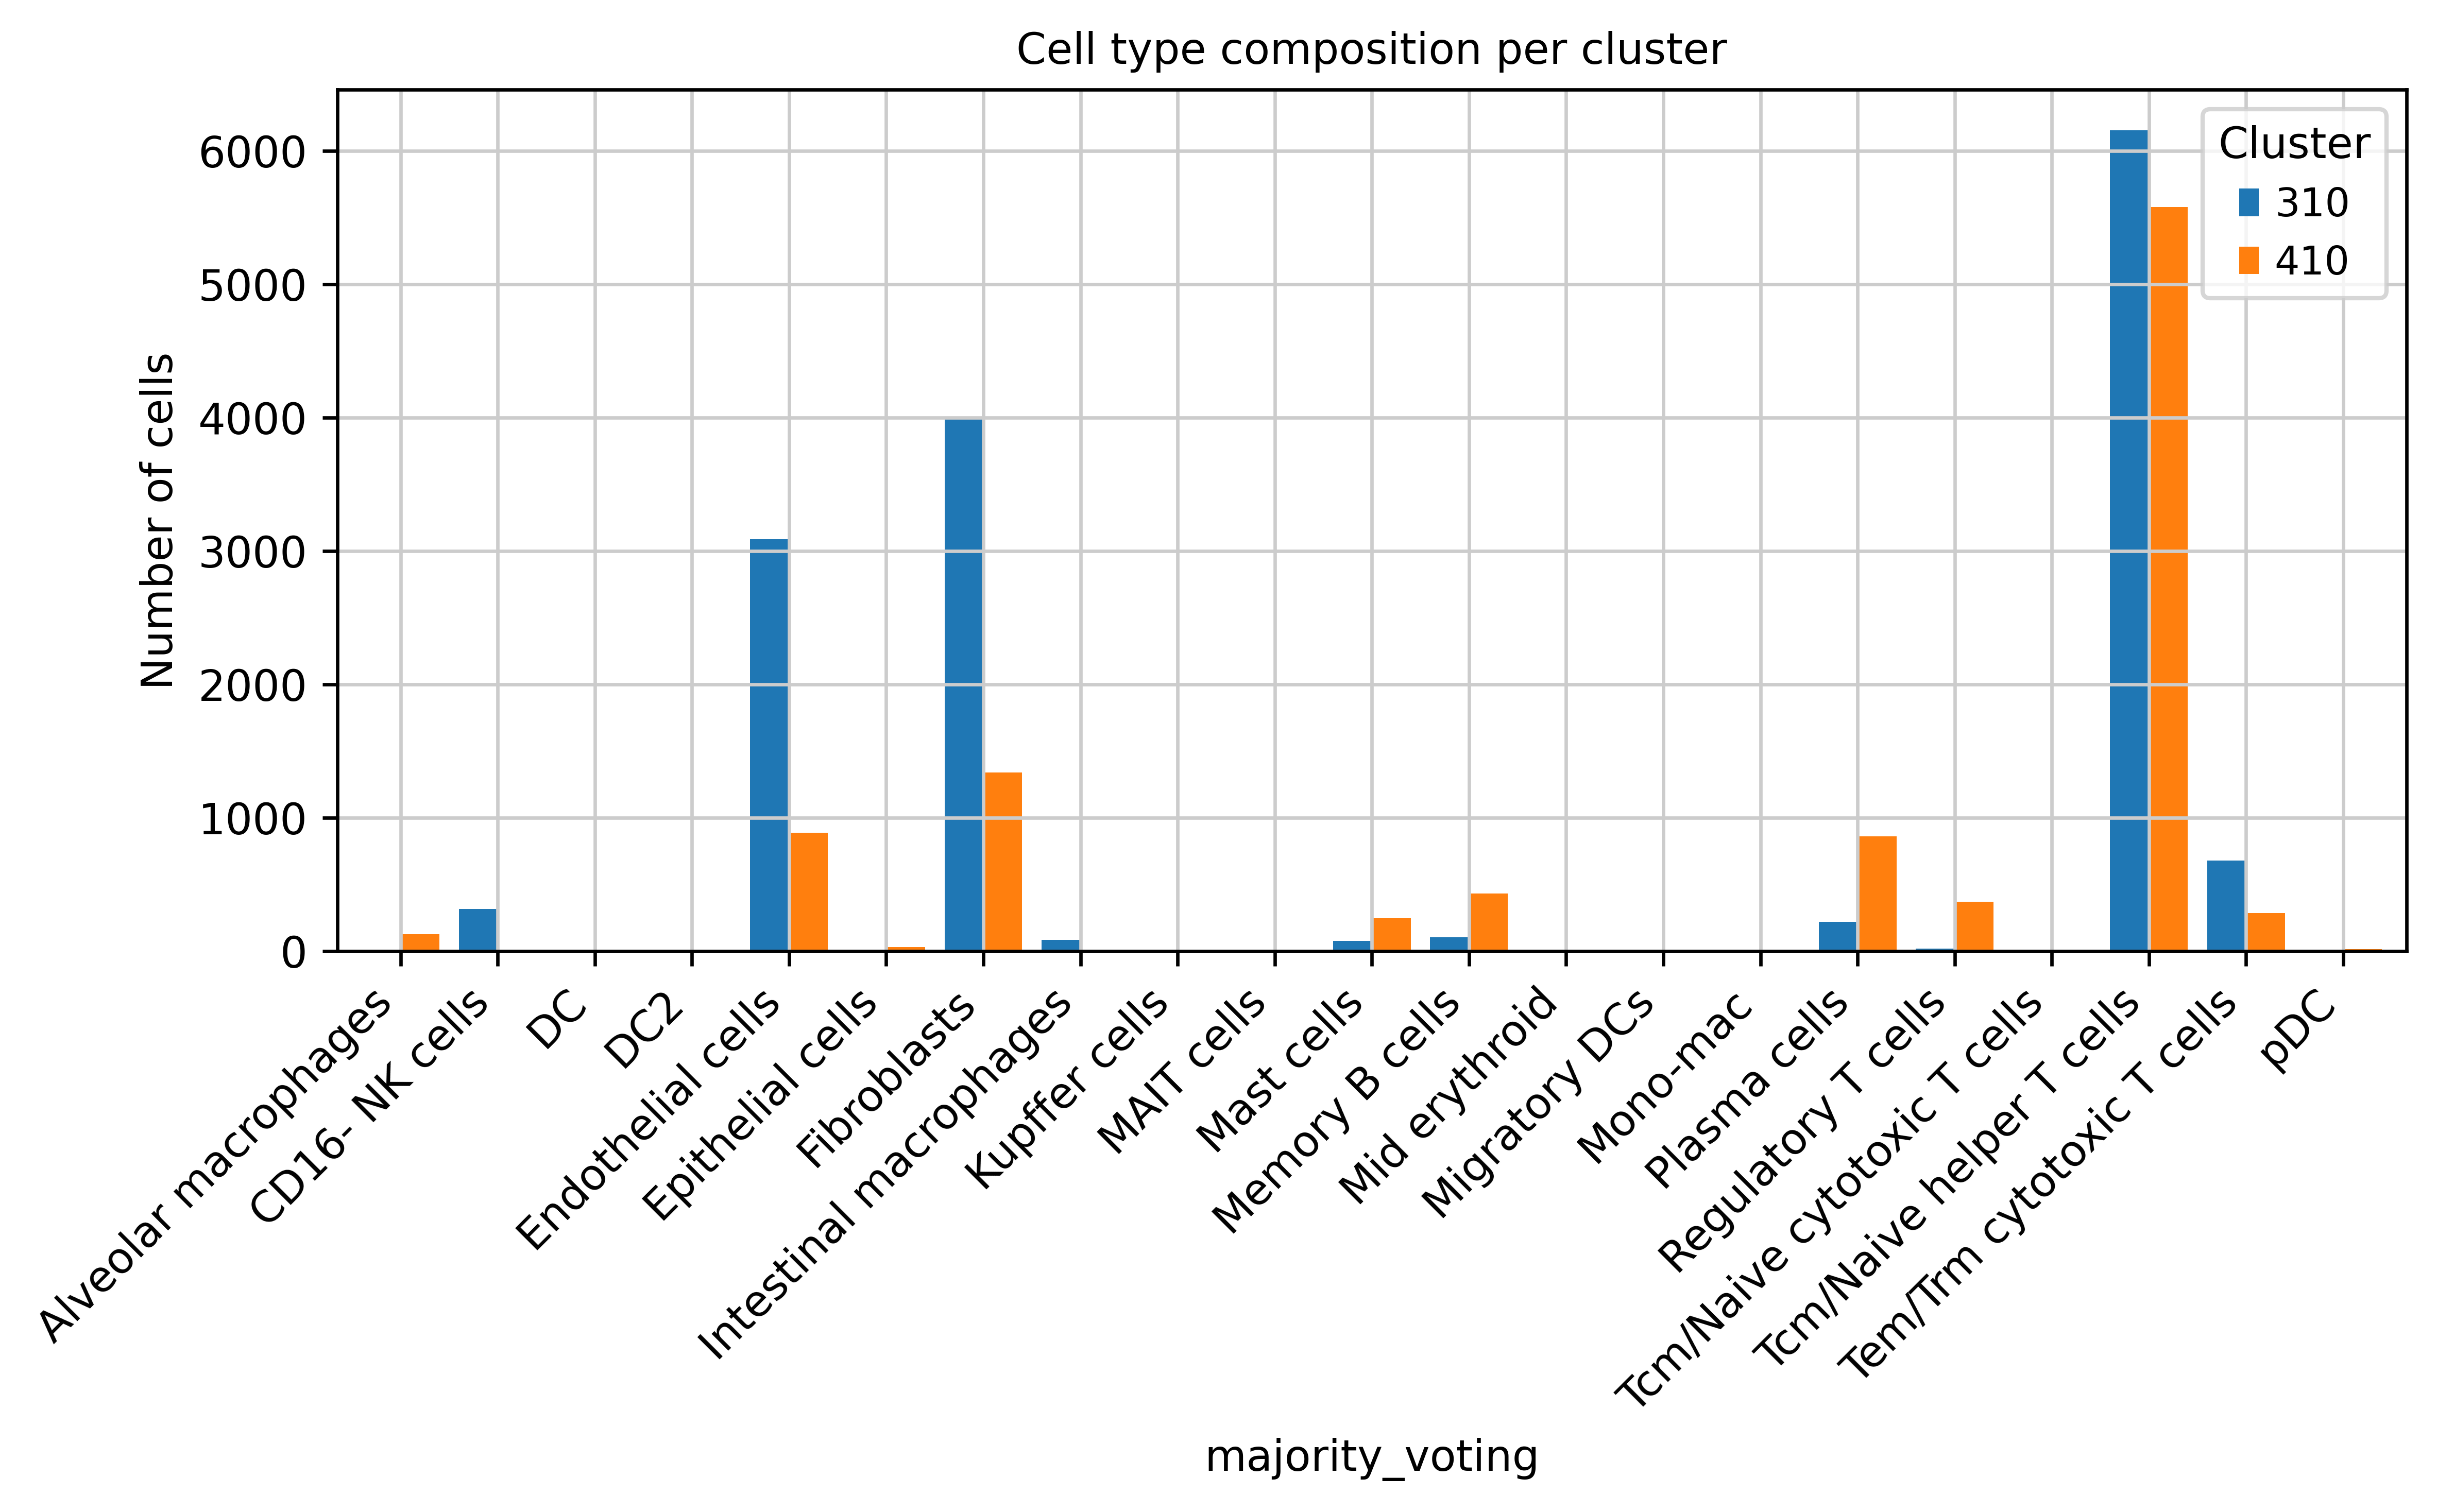

In [27]:
import matplotlib.pyplot as plt

ax = comp_pivot.plot(
    kind="bar",
    figsize=(8,5),
    width=0.8
)
plt.ylabel("Number of cells")
plt.title("Cell type composition per cluster")
plt.xticks(rotation=45, ha="right")
plt.legend(title="Cluster")
plt.tight_layout()
plt.show()


In [28]:
from app.infer import harmonize_adata, tokenize_adata

In [29]:
import scipy.sparse as sp
import anndata as ad

def ensure_csr_everywhere(adata):
    # main matrix
    if sp.issparse(adata.X) and not sp.isspmatrix_csr(adata.X):
        adata.X = adata.X.tocsr()

    # layers
    for k, v in list(adata.layers.items()):
        if sp.issparse(v) and not sp.isspmatrix_csr(v):
            adata.layers[k] = v.tocsr()

    # pairwise matrices
    for k, v in list(adata.obsp.items()):
        if sp.issparse(v) and not sp.isspmatrix_csr(v):
            adata.obsp[k] = v.tocsr()
    for k, v in list(adata.varp.items()):
        if sp.issparse(v) and not sp.isspmatrix_csr(v):
            adata.varp[k] = v.tocsr()

    # RAW is read-only → rebuild it safely
    if adata.raw is not None:
        raw = adata.raw.to_adata()        # materialize Raw as AnnData
        if sp.issparse(raw.X) and not sp.isspmatrix_csr(raw.X):
            raw.X = raw.X.tocsr()
        adata.raw = raw                   # assign back

# run once on your object
ensure_csr_everywhere(adata_cell_subset)

In [30]:
adata_cell_subset = harmonize_adata(adata_cell_subset)

STEP 1: ADDING ENSEMBL IDS...
Adding ensembl IDs from release 110...


Loaded sequence dictionary from /nfs/users/nfs_s/sb75/.cache/pyensembl/GRCh38/ensembl110/Homo_sapiens.GRCh38.cdna.all.fa.gz.pickle
Loaded sequence dictionary from /nfs/users/nfs_s/sb75/.cache/pyensembl/GRCh38/ensembl110/Homo_sapiens.GRCh38.ncrna.fa.gz.pickle
Loaded sequence dictionary from /nfs/users/nfs_s/sb75/.cache/pyensembl/GRCh38/ensembl110/Homo_sapiens.GRCh38.pep.all.fa.gz.pickle


Number of genes with matching ensembl IDs:           4949.
Number of genes skipped:           0.
STEP 2: ADDING SPECIAL VALUES...


In [31]:
adata_cell_subset

AnnData object with n_obs × n_vars = 24967 × 4949
    obs: 'annotation_new7', 'cell_type', 'assay', 'batch', 'tissue', 'gene_panel_size', 'leiden_log1pnorm_res-1', 'donor_id', 'level_1_cell_type', 'dataset', 'cell', 'dataset_batch', 'neighborhood_clusters_res_1.0', 'lung_clusters', 'skin_clusters', 'kidney_clusters', 'liver_clusters', 'tissue_specific_clusters', 'majority_voting', 'cell_id', 'n_genes'
    var: 'ensembl_id'
    uns: 'majority_voting_colors', 'neighborhood', 'neighborhood_clusters_res_1.0', 'neighborhood_umap', 'paga', 'tissue_colors', 'tissue_specific_clusters_colors', 'tissue_specific_clusters_sizes', 'umap', 'dataset_id', 'batch', 'assay', 'species', 'tissue'
    obsm: 'X_umap', 'cell_emb_layer_12', 'neighborhood_emb_layer_12', 'neighborhood_umap', 'spatial'
    layers: 'counts', 'log1pnorm'
    obsp: 'neighborhood_connectivities', 'neighborhood_distances'

In [32]:
dataset_cell_subset = tokenize_adata(
    adata_cell_subset,
    model_folder_path,
    nproc = 4,
    processing_mode = 'parallel')

Loading token dictionary from /nfs/team361/sb75/nichejepa-reproducibility/artifacts/models/29062025_202056_303/token_dictionary.pkl.


STEP 1: LOADING CONFIG...
STEP 2: TOKENIZING ANNDATA OBJECT...
Filtering cells...
No 'filter_pass' column in 'adata.obs'; returning full adata.
Computing spatial neighborhood...
Normalizing gene expression counts...
Retrieving gene tokens.
Ranking gene tokens based on normalized counts.
Retrieving tokens for neighborhood cells.


Creating Hugging Face dataset...
Using dictionary for dataset creation.
Formatting gene tokens...
Map (num_proc=4): 100%|█████████████████████████████████████████| 24967/24967 [03:01<00:00, 137.85 examples/s]


In [33]:
cell_gene_ensembl_id = []
neighborhood_gene_ensembl_id = adata_cell_subset.var['ensembl_id'].tolist()

output_gene_embed = get_gene_embed(
    dataset=dataset_cell_subset,
    model_folder_path=model_folder_path,
    emb_layer=emb_layer,
    batch_size=batch_size,
    pin_memory=pin_memory,
    num_workers=num_workers,
    cell_gene_ensembl_id=cell_gene_ensembl_id,
    neighborhood_gene_ensembl_id=neighborhood_gene_ensembl_id
)

STEP 1: LOADING CONFIG...
STEP 2: GETTING GENE EMBEDDINGS


EncoderMultiMaskWrapper(
  (backbone): GeneTransformerCombinedEncoder(
    (token_embed): Embedding(23407, 384, padding_idx=0)
    (blocks): ModuleList(
      (0-11): 12 x Block(
        (norm1): LayerNorm((384,), eps=1e-06, elementwise_affine=True)
        (attn): Attention(
          (qkv): Linear(in_features=384, out_features=1152, bias=True)
          (attn_drop): Dropout(p=0.0, inplace=False)
          (proj): Linear(in_features=384, out_features=384, bias=True)
          (proj_drop): Dropout(p=0.0, inplace=False)
        )
        (norm2): LayerNorm((384,), eps=1e-06, elementwise_affine=True)
        (mlp): MLP(
          (fc1): Linear(in_features=384, out_features=1536, bias=True)
          (act): GELU(approximate='none')
          (fc2): Linear(in_features=1536, out_features=384, bias=True)
          (drop): Dropout(p=0.0, inplace=False)
        )
      )
    )
    (norm): LayerNorm((384,), eps=1e-06, elementwise_affine=True)
    (pos_embed): Embedding(2817, 384, padding_idx=0)

['encoder', 'predictor', 'target_encoder', 'opt', 'scaler', 'epoch', 'zero_epoch_tracking', 'loss', 'batch_size', 'world_size', 'lr', 'iter_number']


196it [18:39:10, 342.60s/it]


In [34]:
nzavg_output_gene_embed = {}
for k, v in output_gene_embed.items():
    keep = ~(v == 0).all(axis=1) # rows that are not all-zero
    nzavg_output_gene_embed[f"mean_{k}"] = v[keep].mean(axis=0, dtype=np.float32) if keep.any() else np.zeros(v.shape[1], dtype=np.float32)

In [35]:
### Create AnnData from average non-zero gene embeddings ###
keys = list(nzavg_output_gene_embed.keys())
X = np.stack([nzavg_output_gene_embed[k] for k in keys]).astype(np.float32) # shape: (n_genes, n_dim)

# Get gene names to store in `obs_names`
gene_mapping_dict = {
    ensembl_id: gene_name for ensembl_id, gene_name in zip(adata_cell_subset.var['ensembl_id'].tolist(), adata_cell_subset.var.index.tolist())}
gene_names = [gene_mapping_dict[re.sub(r'^mean_neighborhood_emb_gene', '', k)] for k in keys]

adata_genes = ad.AnnData(
    X=X,
    obs=pd.DataFrame(index=gene_names),
    var=pd.DataFrame(index=[f"dim_{i}" for i in range(X.shape[1])])
)

In [36]:
adata_genes_path = f'{folder_path}/adata_{read_checkpoint.split("-")[1].split(".")[0]}_{selected_clusters}_adata_genes.h5ad'
adata_genes.write(adata_genes_path)

In [ ]:
sc.tl.leiden(
    adata_genes, resolution=2.0, key_added='leiden')

In [ ]:
# --- Neighbors graph + Leiden ---
# Using cosine distance on your embedding space (no PCA).
sc.pp.neighbors(
    adata_genes,
    n_neighbors=15,
    use_rep='X',
    #metric='cosine',
    method='umap')
sc.tl.leiden(
    adata_genes, resolution=2.0, key_added='leiden')

# Clusters are here:
print(adata_genes.obs['leiden'].value_counts())

# Optional: UMAP for visualization
sc.tl.umap(adata_genes)
sc.pl.umap(adata_genes, color='leiden')

# Optional: save
# adata.write_h5ad("neighborhood_means.h5ad")

In [ ]:
# Optional: UMAP for visualization
sc.tl.umap(adata_genes)
sc.pl.umap(adata_genes, color='leiden')

In [ ]:
from app.infer import embed_dataset

emb_layer = 0 # None
batch_size = 128
pin_memory = False
num_workers = 12
agg_excluded_tokens = None
top_k = None

output_embed = embed_dataset(
    dataset=dataset_cell_subset,
    model_folder_path=model_folder_path,
    emb_layer=emb_layer,
    agg_excluded_tokens=agg_excluded_tokens,
    top_k=top_k,
    batch_size=batch_size,
    pin_memory=pin_memory,
    num_workers=num_workers,
    return_token_embeddings=True)

In [ ]:
output_embed['token_emb'].shape

In [ ]:
selected_tissue = 'skin'
adata_tissue_expr = adata_tissue_subset_expr[adata_tissue_subset_expr.obs['tissue'] == selected_tissue]

In [ ]:
adata_tissue_expr

In [ ]:
if f'neighborhood_{selected_tissue}_connectivities' not in adata_tissue_expr.obsp.keys():
    # Compute UMAP representation for (aggregated) neighborhood gene embeddings
    sc.pp.neighbors(adata_tissue_expr,
                    n_neighbors=15,
                    use_rep=f'neighborhood_emb_layer_{layer}',
                    key_added=f'neighborhood_{selected_tissue}')
if f'neighborhood_{selected_tissue}_umap' not in adata_tissue_expr.obsm.keys():
    sc.tl.umap(adata_tissue_expr,
               neighbors_key=f'neighborhood_{selected_tissue}',
               key_added=f'neighborhood_{selected_tissue}_umap')

In [ ]:
latent_leiden_resolution = 0.5
latent_cluster_key = f'{selected_tissue}_clusters'

sc.tl.leiden(adata_tissue_expr,
             neighbors_key=f'neighborhood_{selected_tissue}',
             key_added=latent_cluster_key,
             resolution=latent_leiden_resolution)

In [ ]:
(adata_tissue_expr.obs[latent_cluster_key].value_counts() > 1000).sum()

In [ ]:
# Define your column name for easier reference
col = adata_tissue_expr.obs[latent_cluster_key]

# Count occurrences of each unique value
value_counts = col.value_counts()

# Get values that occur less than 1000 times
rare_values = value_counts[value_counts < 1000].index

# Set those values to NaN
adata_tissue_expr.obs[latent_cluster_key] = col.where(~col.isin(rare_values), np.nan)

# Drop unused categories if the column is categorical
adata_tissue_expr.obs[latent_cluster_key] = (
    adata_tissue_expr.obs[latent_cluster_key]
    .cat.remove_unused_categories()
)

In [ ]:
latent_cluster_key = f'{selected_tissue}_clusters'

In [ ]:
# Add tissue-specific increment to cluster number
tissue_increments = {
    'skin': 100,
    'kidney': 200,
    'liver': 300,
    'lung': 400}
adata_tissue_expr.obs[latent_cluster_key] = (
    adata_tissue_expr.obs[latent_cluster_key].astype('Int64') + tissue_increments[selected_tissue]).astype('category')

In [ ]:
adata_tissue_expr.obs[latent_cluster_key]

In [ ]:
# make all plots larger (applies globally)
sc.settings.set_figure_params(figsize=(6, 6), dpi=300)

adata_tissue_expr.obsm['X_umap'] = adata_tissue_expr.obsm[f'neighborhood_{selected_tissue}_umap']

sc.pl.umap(adata_tissue_expr,
           color=latent_cluster_key,
           show=False)
#plt.title(f'{emb_key}_{gene_category}_program by {label} (UMAP)', fontsize=14)
#plt.savefig(
#    f'{artifacts_folder_path}/hst_corpus_80m/{load_timestamp}/figures/{emb_key}_{gene_category}_program_umap_{label}.png',
#    dpi=300,
#    bbox_inches='tight')
plt.show()

In [ ]:
#del(adata_tissue_expr.uns['kidney_clusters_colors'])

In [ ]:
adata_tissue_expr_path = f'{folder_path}/adata_{read_checkpoint.split("-")[1].split(".")[0]}_5k_expr_{selected_tissue}.h5ad'
adata_tissue_expr.write(adata_tissue_expr_path)

In [ ]:
selected_tissue = 'lung'
adata_tissue_expr_path = f'{folder_path}/adata_{read_checkpoint.split("-")[1].split(".")[0]}_5k_expr_{selected_tissue}.h5ad'
adata_tissue_expr = sc.read_h5ad(adata_tissue_expr_path)

In [ ]:
latent_cluster_key = f'{selected_tissue}_clusters'

In [ ]:
latent_cluster_key = f'{selected_tissue}_clusters'

In [ ]:
adata_tissue_expr.obsm['X_umap'] = adata_tissue_expr.obsm[f'neighborhood_{selected_tissue}_umap']

sc.pl.umap(adata_tissue_expr,
           color=latent_cluster_key,
           show=False)
#plt.title(f'{emb_key}_{gene_category}_program by {label} (UMAP)', fontsize=14)
#plt.savefig(
#    f'{artifacts_folder_path}/hst_corpus_80m/{load_timestamp}/figures/{emb_key}_{gene_category}_program_umap_{label}.png',
#    dpi=300,
#    bbox_inches='tight')
plt.show()

In [ ]:
adata_tissue_expr_path = f'{folder_path}/adata_{read_checkpoint.split("-")[1].split(".")[0]}_5k_expr_{selected_tissue}.h5ad'
adata_tissue_expr.write(adata_tissue_expr_path)

In [ ]:
adata_tissue_subset_expr

### 2.3.3 Perform Cross Tissue Analysis (700k Cells Subsample)

In [ ]:
# Define config
dataset_name = 'hst_corpus_80m'
load_timestamp = '11062025_183320_055' # '11062025_183320_055', '18062025_082526_412', '03072025_001126_488'
read_checkpoint = 'nichejepa-ep10_0.pth.tar' # 'nichejepa-ep10_0.pth.tar', 'nichejepa-ep16_0.pth.tar', 'nichejepa-ep3_0.pth.tar'
folder_path = f'{artifacts_folder_path}/{dataset_name}/{load_timestamp}'
model_folder_path = f'/nfs/team361/sb75/nichejepa-reproducibility/artifacts/models/{load_timestamp}'
raw_data_folder_path = '/nfs/team361/sb75/DATASETS/silver/hst_corpus_80m'

emb_layer = None
n_layer = 12
top_k = None
batch_size = 128
pin_memory = False
num_workers = 12
n_pcs = 0

annotation_cols = [
    'level_1_cell_type',
    'cell_type',
    'annotation_new7']
obs_cols = [
    'leiden_log1pnorm_res-1',
    'level_1_cell_type',
    'annotation_new7',
    'cell_type']
uns_cols = [
    'assay',
    'batch',
    'donor_id',
    'tissue']

compute_gene_embeddings = False # only needs to be run once

In [ ]:
# Load token dict
with open(token_dict_path, 'rb') as f:
    token_dict = pickle.load(f)

token_dict_reverse =  {value: key for key, value in token_dict.items()}

spv_dict = {
    k: v for k, v in token_dict.items() if k.startswith('spv_')}
spv_start_idx = min(spv_dict.values())
max_cls_tokens = sum(1 for key in token_dict if "cls" in key)
spv_idx_subtract = spv_start_idx - 2 - max_cls_tokens

In [ ]:
# Load full corpus dataset
params['data']['precomputed_split'] = False
params['data']['test_batch_ids'] = False
params['data']['val_batch_ids'] = False
if 'precomputed_epoch_n_nonzero_tokens' in params['data'].keys():
    del(params['data']['precomputed_epoch_n_nonzero_tokens'])
if 'precomputed_epoch_splits' in params['data'].keys():
    del(params['data']['precomputed_epoch_splits'])

dataset, _, _ = prepare_dataset(params)
dataset # 80,172,337 cells

In [ ]:
##### Filter dataset to keep only 5k gene panel cells #####
# Get gene panel values for 5k gene panel
min_gene_panel_size = 4948
max_gene_panel_size = 4949

# Perform index subtraction as in tokenizer
max_cls_tokens = 100
spv_dict = {
    k: v for k, v in token_dict.items() if k.startswith('spv_')}
spv_start_idx = min(spv_dict.values())
spv_idx_subtract = spv_start_idx - 2 - max_cls_tokens

keep_gene_panel_values = torch.tensor([
    v - spv_idx_subtract for k,v in token_dict.items() if ('spv_gene_panel' in k) and (int(k.split('panel')[1]) >= min_gene_panel_size) and (int(k.split('panel')[1]) <= max_gene_panel_size)])

# Filter dataset
dataset.set_format(type=None) # for extreme speed-up

def keep_row(x):
    return torch.isin(torch.tensor(x["gene_panel_value"]), keep_gene_panel_values)

filtered_dataset = dataset.filter(
    keep_row,
    batched=True,
    batch_size=10000, 
    num_proc=num_workers)

######################################################################

##### Subsample dataset and only keep 100k genes per tissue #####
n_per_tissue = 100_000
rng_seed = 42

# Step 1: Shuffle the full dataset once
shuffled_dataset = filtered_dataset.shuffle(seed=rng_seed)

# Step 2: Extract the tissue_value column (this is fast and avoids full row loading)
tissue_values = shuffled_dataset["tissue_value"]

# Step 3: Collect sample indices efficiently
tissue_counts = defaultdict(int)
tissue_indices = defaultdict(list)

for idx, tissue in enumerate(tissue_values):
    tissue = tissue[0]

    if tissue_counts[tissue] < n_per_tissue:
        tissue_indices[tissue].append(idx)
        tissue_counts[tissue] += 1

# Step 4: Build final dataset with select
final_samples = [
    shuffled_dataset.select(indices) for indices in tissue_indices.values()
]
final_dataset = concatenate_datasets(final_samples)
columns = list(final_dataset.features.keys())
columns.remove("cell_id")
final_dataset.set_format(
    type="torch",
    columns=columns,
    output_all_columns=True)
final_dataset # 700,000 cells

# Step 5: Write to disk
#final_dataset.save_to_disk(
#    "/lustre/scratch126/cellgen/lotfollahi/DATASETS/gold/cell-graph-tokenizer/hst_corpus_80m/hst_corpus_80m_32_None_None_None_None_None_shifted_log_knn_10_5k_subsample.dataset")
######################################################################

In [ ]:
# Sample random genes
adata_temp = sc.read_h5ad('/nfs/team361/sb75/DATASETS/silver/xhe1008-1-20b_1p/section020_SOB26.h5ad')
random.seed(42)
random_genes = random.sample(adata_temp.var.index.tolist(), 14)
random_genes

In [ ]:
# Define gene programs
fibrosis_genes = [
    'IL6',
    'LOX',
    'MMP9',
    'PDGFRB',
    'POSTN',
    'SNAI1',
    'TGFB1',
    'TIMP2',
    'TNF',
    'ZEB1' 
]

pan_tcells_genes =[
    'CD3D', # 'ENSG00000167286'
    'CD3E', # 'ENSG00000198851'
    'CD3G', # 'ENSG00000160654'
    'CD4', # 'ENSG00000010610'
    'CD8A', # 'ENSG00000153563'
    'CD2', # 'ENSG00000116824'
    'CD5', # 'ENSG00000110448'
    'CD7', # 'ENSG00000173762'
    'TRAC', # ''
    'TRBC1', # ''
    'TRBC2', # ''
    'IL7R', # 'ENSG00000168685'
    'TCF7', # 'ENSG00000081059'
    'SELL', # 'ENSG00000188404'
    'CCR7' # 'ENSG00000126353'
]
pan_tams_genes = [
    'CD68', # ENSG00000129226
    'C1QA', # ENSG00000173372
    'ITGA4', # ENSG00000115232
    'P2RY12', # ENSG00000169313
    'CD163', # ENSG00000177575
    'CD206', # ''
    'CSF1R', # ENSG00000182578
    'F13A1', # ENSG00000124491
    'APOE', # ENSG00000130203
    'LYZ', # ENSG00000090382
    'AIF1', # ENSG00000204472
    'TREM2', # ENSG00000095970
    'MS4A6A' # ENSG00000110077
]
pan_fibroblasts_genes = [
    ''
]
#random_genes = [
#    'COIL',
#    'ANO1',
#    'KAT2B',
#    'HSPD1',
#    'GRM5',
#    'DEK',
#    'CIP2A',
#    'TMEM126A',
#    'CDC34',
#    'XPR1',
#    'PROM1',
#    'ARF6',
#    'APOL1',
#    'CEACAM8'
#]   

In [ ]:
##### Retrieve gene embeddings #####
# Specify genes
if compute_gene_embeddings:
    for gene_category in ['pan_tcells', 'pan_tams', 'pan_fibroblasts', 'random']:

        if gene_category == 'pan_tcells':
            genes = pan_tcells_genes
        elif gene_category == 'pan_tams':
            genes = pan_tams_genes
        elif gene_category == 'random':
            genes = random_genes
        
        # Get ensembl IDs
        gene_name_to_ensembl_id_dict_path = '/nfs/team361/sb75/DATASETS/genes/homo_sapiens_gene_name_to_ensembl_id_dict.pkl'
        with open(gene_name_to_ensembl_id_dict_path, 'rb') as f:
            gene_name_to_ensembl_id_dict = pickle.load(f)
        
        ensembl_ids = [gene_name_to_ensembl_id_dict.get(gene, '') for gene in genes]
        cell_gene_ensembl_id = [gene for gene in ensembl_ids if gene != '']
        neighborhood_gene_ensembl_id = [gene for gene in ensembl_ids if gene != '']
        
        # Get gene embeddings
        output_gene_embed = get_gene_embed(
            dataset=final_dataset,
            model_folder_path=model_folder_path,
            emb_layer=emb_layer,
            batch_size=batch_size,
            pin_memory=pin_memory,
            num_workers=num_workers,
            cell_gene_ensembl_id=cell_gene_ensembl_id,
            neighborhood_gene_ensembl_id=neighborhood_gene_ensembl_id
        )
        
        # Save output_gene_embed dict
        with open(f'{folder_path}/output_gene_embed_{gene_category}_{read_checkpoint.split("-")[1].split(".")[0]}.pkl', 'wb') as f:
            pickle.dump(output_gene_embed, f)

In [ ]:
# Get gene expression for all cells
adata_expr_path = f'{folder_path}/adata_{read_checkpoint.split("-")[1].split(".")[0]}_5k_subsample_expr.h5ad'
if os.path.exists(adata_expr_path):
    print("Load existing AnnData.")
    adata_expr = sc.read_h5ad(adata_expr_path)
else:
    print("Gather new AnnData.")
    cell_ids = final_dataset['cell_id']
    dataset_ids = list(set([cell_id.split('_')[0] for cell_id in cell_ids]))
    
    adata_expr = collect_adata_from_folder(
        raw_data_folder_path,
        cell_ids,
        dataset_ids,
        obs_cols,
        uns_cols)
    
    # Write to disk
    adata_expr.write(adata_expr_path)

In [ ]:
adata_expr = sc.read_h5ad('/nfs/team361/sb75/nichejepa-reproducibility/artifacts/hst_corpus_80m/29062025_202056_303/adata_ep4_0_5k_expr_tissuesubset.h5ad')

In [ ]:
adata_expr.obs = adata_expr.obs.set_index('cell_id')

In [ ]:
adata_expr.obs = adata_expr.obs.drop(adata_expr.obs.columns, axis=1)

In [ ]:
adata_expr_cp.obs.head(5)

In [ ]:
adata_expr_cp = adata_expr[adata_processed.obs.index].copy()

In [ ]:
adata_expr_cp.obs = pd.merge(adata_expr_cp.obs, adata_processed.obs, left_index=True, right_index=True)

In [ ]:
adata_expr_cp.obsm = adata_processed.obsm
adata_expr_cp.obsp = adata_processed.obsp
adata_expr_cp.uns = adata_processed.uns

In [ ]:
adata_expr_cp

In [ ]:
adata_expr_cp.write('/nfs/team361/sb75/nichejepa-reproducibility/artifacts/hst_corpus_80m/29062025_202056_303/adata_ep4_0_5k_expr_tissuesubset_processed.h5ad')

In [ ]:
# Get cell and neighborhood embeddings for all cells
adata_emb_path = f'{folder_path}/adata_{read_checkpoint.split("-")[1].split(".")[0]}_5k_subsample.h5ad'
if os.path.exists(adata_emb_path):
    print("Load existing AnnData.")
    adata = sc.read_h5ad(adata_emb_path)
else:
    print("Infer and save new AnnData.")
    cell_ids = final_dataset['cell_id']
    dataset_ids = list(set([cell_id.split('_')[0] for cell_id in cell_ids]))
    
    # Run model inference
    adata = infer(params,
                  final_dataset,
                  load_folder_path=folder_path,
                  dataset_ids=dataset_ids,
                  obs_cols=obs_cols,
                  uns_cols=uns_cols,
                  agg_type=agg_type,
                  masked_tokens=None,
                  agg_excluded_tokens=None
                 )
    
    # Write to disk
    adata.write(adata_emb_path)

In [ ]:
# Reorder expression AnnData to match embedding AnnData
adata_expr.obs = adata_expr.obs.set_index('cell_id')
adata_expr_reordered = adata_expr[adata.obs.index].copy()

# Add obs and obsm to expression AnnData
adata_expr_reordered.obs = adata.obs
adata_expr_reordered.obsm = adata.obsm

In [ ]:
# Combine annotations
adata_expr_reordered.obs['combined_annotation'] = (
    adata_expr_reordered.obs[annotation_cols]
    .bfill(axis=1) # backfill across columns
    .iloc[:, 0] # take the first non-NaN value per row
)

adata_expr_reordered.obs['combined_annotation'] = adata_expr_reordered.obs['combined_annotation'].replace('', np.nan)

In [ ]:
# Write counts to csv file for cell type annotation with CellTypist
count_df = pd.DataFrame(
    adata_expr_reordered.X.toarray().astype(np.float32),
    index=adata_expr_reordered.obs_names,
    columns=adata_expr_reordered.var_names)

count_df.to_csv(adata_emb_path.replace('h5ad', 'csv'))

In [ ]:
count_df.to_csv(adata_emb_path.replace('h5ad', 'csv'))

In [ ]:
test = pd.read_csv(adata_emb_path.replace('h5ad', 'csv'))

In [ ]:
test = pd.read_csv('/nfs/users/nfs_s/sb75/.venvs/nichejepa/lib/python3.10/site-packages/celltypist/data/samples/sample_cell_by_gene.csv')

In [ ]:
# Run cell typing followed by majority voting.
predictions = celltypist.annotate(adata_emb_path.replace('h5ad', 'csv'), majority_voting = True)

# Examine the prediction results.
predictions.predicted_labels

# Join to AnnData
adata_expr_reordered.obs = adata_expr_reordered.obs.join(predictions.predicted_labels['majority_voting'])

In [ ]:
# Refine annotations
coarse_cell_type_map = {
    # NaNs and unspecific
    None: "Unassigned",
    'nan': "Unassigned",
    'Nonspecific': "Unassigned",

    # T cells
    'T': "TCell",
    'Treg': "TCell",
    'Treg_LRRC32+': "TCell",
    'T_GZMK+': "TCell",
    'Th': "TCell",
    'T_ITGAEhi_IL22': "TCell",
    'T_Prolif': "TCell",
    'Tc': "TCell",
    'Tc_ZNF683+': "TCell",
    'TRM_IL13+': "TCell",
    'TRM_IL17+': "TCell",
    'T_vascular': "TCell",
    'ILC1/NK': "TCell",
    'ILC2/Tnaive': "TCell",
    'ILC2/3': "TCell",
    'ILC_prolif': "TCell",
    'NK': "TCell",

    # B-lineage
    'Bcell': "BCell",
    'Plasma cell': "BCell",

    # Myeloid
    'Mac': "Macrophage",
    'Mac_CX3CR1+': "Macrophage",
    'cDC1': "DendriticCell",
    'cDC2': "DendriticCell",
    'MigDC': "DendriticCell",
    'LC': "DendriticCell",
    'LC/MigDC': "DendriticCell",
    'pDC': "DendriticCell",
    'Mast cell': "MastCell",
    'Myeloid': "Myeloid",

    # Epithelial cells (mostly keratinocytes)
    'KC1': "Keratinocyte",
    'KC1/2': "Keratinocyte",
    'KC1-2_cycling': "Keratinocyte",
    'KC2': "Keratinocyte",
    'KC3': "Keratinocyte",
    'KC4': "Keratinocyte",
    'KC4-5': "Keratinocyte",
    'KC5': "Keratinocyte",
    'KCinflamm': "Keratinocyte",
    'KC_HF: ORS0': "HairFollicle_KC",
    'KC_HF: ORS1': "HairFollicle_KC",
    'KC_HF: ORS2': "HairFollicle_KC",
    'KC_HF: ORS_cycling': "HairFollicle_KC",
    'KC_HF: IRS': "HairFollicle_KC",
    'KC_HF: IRS_cycling': "HairFollicle_KC",
    'KC_HF_inner': "HairFollicle_KC",
    'KC_HF_Basal': "HairFollicle_KC",
    'KC_HF_ORS': "HairFollicle_KC",
    'KC_HF: HS': "HairFollicle_KC",
    'KC_HF_medulla': "HairFollicle_KC",
    'KC_SebocyteDuct_Outer/HF_Junction': "HairFollicle_KC",

    # Sebocytes
    'KC_SebocyteGland_Outer': "Sebocyte",
    'KC_SebocyteGland_Inner': "Sebocyte",
    'KC_SebocyteDuct_Outer': "Sebocyte",
    'KC_SebocyteDuct_Inner': "Sebocyte",
    'Sebocyte_CCL19': "Sebocyte",
    'Sebocyte_PPARG': "Sebocyte",

    # Sweat gland
    'Sweat gland': "SweatGland",
    'Sweat gland channel outer': "SweatGland",
    'Sweat gland channel inner': "SweatGland",
    'Sweat gland Myoepithelial': "SweatGland",

    # Stromal/Fibroblasts
    'F1: Superficial': "Fibroblast",
    'F2: Universal': "Fibroblast",
    'F2/3: Bridge': "Fibroblast",
    'F2/3: Perivascular': "Fibroblast",
    'F3: FRC-like': "Fibroblast",
    'F3: TRC-like': "Fibroblast",
    'F4: TNN+COCH+': "Fibroblast",
    'F4: Mixed': "Fibroblast",
    'F4: DS_DPEP1+': "Fibroblast",
    'F4: DP_HHIP+': "Fibroblast",
    'F5: Schwann-like': "Fibroblast",
    'F5: NGFR+': "Fibroblast",
    'F5: RAMP1+': "Fibroblast",
    'F6: Inflammatory myofibroblast': "Fibroblast",

    # Vasculature
    'VE': "Endothelial",
    'VE1_Art': "Endothelial",
    'VE3_Ven': "Endothelial",
    'VE3_Ven_APLN+': "Endothelial",
    'VE4_Cap': "Endothelial",
    'LE': "Endothelial",
    'VE/Pericyte': "Perivascular",
    'Pericyte1': "Perivascular",
    'Pericyte2_VSMC': "Perivascular",

    # Glial
    'nmSchwann': "Schwann",
    'mSchwann': "Schwann",
    'Schwann': "Schwann",
    'Adipocyte/mSchwann': "Schwann",

    # Muscle
    'Smooth muscle': "Muscle",
    'Muscle': "Muscle",

    # Other epithelial
    'Melanocyte': "Melanocyte",
    'Merkel cell': "MerkelCell",
    'Epithelium': "Epithelium",

    # Adipocyte
    'Adipocyte': "Adipocyte",

    # High-level groups
    'Endothelium': "Endothelial",
    'Stroma': "Fibroblast",
    'Lymphoid': "Lymphoid"
}

adata_expr_reordered.obs['coarse_cell_type'] = adata_expr_reordered.obs[
    'combined_annotation'].apply(lambda x: coarse_cell_type_map.get(x, 'Unassigned')).astype(str)

In [ ]:
# Write to disk
adata_expr_processed_path = f'{folder_path}/adata_{read_checkpoint.split("-")[1].split(".")[0]}_5k_subsample_processed.h5ad'
if os.path.exists(adata_expr_processed_path):
    print("Load existing AnnData.")
    adata_expr_reordered = sc.read_h5ad(adata_expr_processed_path)
else:
    print("Process and save new AnnData.")
    # Compute neighbors
    sc.pp.neighbors(adata_expr_reordered,
                    n_neighbors=15,
                    use_rep=f'neighborhood_emb_layer_{n_layer}',
                    n_pcs=(n_pcs if n_pcs > 0 else None),
                    key_added='neighborhood')
    sc.pp.neighbors(adata_expr_reordered,
                    n_neighbors=15,
                    use_rep=f'cell_emb_layer_{n_layer}',
                    n_pcs=(n_pcs if n_pcs > 0 else None),
                    key_added='cell')
    
    # Compute UMAP 
    sc.tl.umap(adata_expr_reordered,
               neighbors_key='neighborhood',
               key_added='neighborhood_umap')
    sc.tl.umap(adata_expr_reordered,
               neighbors_key='cell',
               key_added='cell_umap')

    # Compute Leiden clustering
    latent_leiden_resolution = 1.0
    latent_cluster_key = f'cell_clusters_res_{latent_leiden_resolution}'
    
    sc.tl.leiden(adata_expr_reordered,
                 neighbors_key='cell',
                 key_added=latent_cluster_key,
                 resolution=latent_leiden_resolution)
    
    latent_leiden_resolution = 1.0
    latent_cluster_key = f'neighborhood_clusters_res_{latent_leiden_resolution}'
    
    sc.tl.leiden(adata_expr_reordered,
                 neighbors_key='neighborhood',
                 key_added=latent_cluster_key,
                 resolution=latent_leiden_resolution)
    
    adata_expr_reordered.write(adata_expr_processed_path)

In [ ]:
adata_expr_reordered.write(adata_expr_processed_path)

In [ ]:
# Plot cell and neighborhood embedding UMAP
labels = ['majority_voting', 'tissue', 'cell_clusters_res_1.0', 'neighborhood_clusters_res_1.0']

for label in labels:
    adata_expr_reordered.obsm['X_umap'] = adata_expr_reordered.obsm['cell_umap']
    sc.pl.umap(
        adata_expr_reordered,
        neighbors_key='cell',
        color=label,
        palette=None,
        show=False)
    plt.title(f'Cell embedding by {label} (UMAP)', fontsize=14)
    plt.savefig(
        f'{artifacts_folder_path}/hst_corpus_80m/{load_timestamp}/{f"{dataset_name}_" if dataset_name != "hst_corpus_80m" else ""}{label}_5k_subsample_cell_umap.png',
        dpi=300,
        bbox_inches='tight')
    plt.show()
    
    adata_expr_reordered.obsm['X_umap'] = adata_expr_reordered.obsm['neighborhood_umap']
    sc.pl.umap(
        adata_expr_reordered,
        neighbors_key='neighborhood',
        color=label,
        palette=None,
        show=False)
    plt.title(f'Neighborhood embedding by {label} (UMAP)', fontsize=14)
    plt.savefig(
        f'{artifacts_folder_path}/hst_corpus_80m/{load_timestamp}/{f"{dataset_name}_" if dataset_name != "hst_corpus_80m" else ""}{label}_5k_subsample_neighborhood_umap.png',
        dpi=300,
        bbox_inches='tight')
    plt.show()

In [ ]:
for label in [
    'TBX3',
    'EHD3',
    'EMCN',
    'SOX17',
    'GJA5']:
    if label in adata_expr_reordered.var_names.tolist():
        adata_expr_reordered.obsm['X_umap'] = adata_expr_reordered.obsm['cell_umap']
        sc.pl.umap(
            adata_expr_reordered,
            neighbors_key='cell',
            color=label,
            palette=None,
            show=False)
        plt.title(f'Cell embedding by {label} (UMAP)', fontsize=14)
        plt.savefig(
            f'{artifacts_folder_path}/hst_corpus_80m/{load_timestamp}/{f"{dataset_name}_" if dataset_name != "hst_corpus_80m" else ""}{label}_5k_subsample_cell_umap.png',
            dpi=300,
            bbox_inches='tight')
        plt.show()

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))
sns.countplot(data=adata_expr_reordered.obs, 
              x='neighborhood_clusters_res_1.0', 
              hue='tissue')
plt.title('Distribution of Tissues per Neighborhood Cluster')
plt.xlabel('Neighborhood Cluster')
plt.ylabel('Cell Count')
plt.legend(title='Tissue', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

In [ ]:
# Get the embeddings and the cluster labels
embeddings = adata_expr_reordered.obsm['neighborhood_emb_layer_12']
clusters = adata_expr_reordered.obs['neighborhood_clusters_res_1.0']

# Create a DataFrame combining both
embeddings_df = pd.DataFrame(embeddings, index=adata_expr_reordered.obs_names)
embeddings_df['cluster'] = clusters.values

# Group by cluster and average
cluster_averages = embeddings_df.groupby('cluster').mean()

In [ ]:
cos_sim_df

In [ ]:
top_sim_dict = {}

for cluster in cos_sim_df.index:
    # Drop self-similarity and get top 5
    top_similar = cos_sim_df.loc[cluster].drop(cluster).nlargest(5)
    top_sim_dict[cluster] = top_similar

In [ ]:
import numpy as np
from sklearn.metrics.pairwise import cosine_similarity
import seaborn as sns
import matplotlib.pyplot as plt

# Step 1: Compute cosine similarity matrix
cos_sim_matrix = cosine_similarity(cluster_averages.values)

# Step 2: Convert to DataFrame
cos_sim_df = pd.DataFrame(cos_sim_matrix, 
                          index=cluster_averages.index, 
                          columns=cluster_averages.index)

# Step 3: Mask everything except top-3 per row (excluding self-similarity)
masked_df = cos_sim_df.copy()

for i in masked_df.index:
    # Get the top 3 non-self values
    top_3 = masked_df.loc[i].drop(i).nlargest(3).index
    mask = ~masked_df.columns.isin(top_3) & (masked_df.columns != i)
    masked_df.loc[i, mask] = np.nan  # Mask all but top-3 and self

# Step 4: Plot heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(masked_df, cmap='viridis', annot=True, fmt=".2f", square=True, mask=masked_df.isna())
plt.title("Top-3 Cosine Similarities per Cluster")
plt.tight_layout()
plt.show()

In [ ]:
top_sim_dict

In [ ]:
adata_expr_reordered.obsm['X_umap'] = adata_expr_reordered.obsm['neighborhood_umap']
sc.pl.umap(
    adata_expr_reordered,
    neighbors_key='neighborhood',
    color=label,
    groups=['4', '6', '2', '28', '1', '35'],
    palette=None,
    show=False)
plt.show()

In [ ]:
adata_expr_reordered.obsm['X_umap'] = adata_expr_reordered.obsm['neighborhood_umap']
sc.pl.umap(
    adata_expr_reordered,
    neighbors_key='neighborhood',
    color=label,
    groups=['0', '41', '36', '31', '22', '23'],
    palette=None,
    show=False)
plt.show()

In [ ]:
adata_expr_reordered.obsm['X_umap'] = adata_expr_reordered.obsm['neighborhood_umap']
sc.pl.umap(
    adata_expr_reordered,
    neighbors_key='neighborhood',
    color=label,
    groups=['44', '28', '1', '17', '6', '34'],
    palette=None,
    show=False)
plt.show()

In [ ]:
endothelium_genes = ['PECAM1', 'CDH5', 'PLVAP', 'S100A10', 'PODXL']
fibroblasts_genes = ['PDGFRA', 'OBSCN', 'NEAT1', 'VIM']
pericytes_genes = ['SLC6A12', 'PDGFRB']

genes = pan_tcells_genes + pan_tams_genes + random_genes + endothelium_genes + fibroblasts_genes + pericytes_genes

In [ ]:
# Plot gene program embedding for one gene program at a time
for gene_category in ['fibrosis']: # ['pan_tams', 'pan_tcells', 'random']:
    
    #if gene_category == 'pan_tcells':
    #    genes = pan_tcells_genes
    #elif gene_category == 'pan_tams':
    #    genes = pan_tams_genes
    #elif gene_category == 'random':
    #    genes = random_genes
    
    # Load output_gene_embed dict
    with open(f'{folder_path}/output_gene_embed_{gene_category}_{read_checkpoint.split("-")[1].split(".")[0]}.pkl', 'rb') as f:
        output_gene_embed = pickle.load(f)
    
    for emb_key in ['neighborhood_emb']: # ['cell_emb', 'neighborhood_emb']:
    
        gene_emb = [v for k, v in output_gene_embed.items() if emb_key in k]
        
        # Stack them along a new axis: shape becomes (num_keys, N, D)
        #gene_emb_stacked = np.stack(gene_emb, axis=0)
        # Compute the mean across the keys (axis=0), keeping shape (N, D)
        #mean_gene_emb = gene_emb_stacked.mean(axis=0)
        # Stack into shape: (12, 700000, 384)
        stacked = np.stack(gene_emb, axis=0)
        # Mask of nonzero rows: shape (12, 700000)
        nonzero_mask = ~(stacked == 0).all(axis=2)
        # Count of valid arrays per row: shape (700000,)
        valid_counts = nonzero_mask.sum(axis=0)
        # To avoid divide-by-zero later
        valid_counts = np.where(valid_counts == 0, 1, valid_counts)
        # Zero out fully-zero rows before summing
        masked = stacked * nonzero_mask[:, :, np.newaxis]  # shape: (12, 700000, 384)
        # Sum across arrays and normalize
        sum_embeddings = masked.sum(axis=0)                 # shape: (700000, 384)
        mean_gene_emb = sum_embeddings / valid_counts[:, np.newaxis]  # shape: (700000, 384)
    
        nonzero_row_mask = ~(mean_gene_emb == 0).all(axis=1)
        filtered_mean_gene_emb = mean_gene_emb[nonzero_row_mask]
        
        # Create AnnData
        adata = ad.AnnData(filtered_mean_gene_emb)
        adata.obs['cell_id'] = list(np.array(final_dataset['cell_id'])[nonzero_row_mask])
        adata.obs['tissue'] = list(np.array([
            token_dict_reverse[tissue_value.item() + spv_idx_subtract].split('spv_')[1]
            for tissue_value in final_dataset['tissue_value']])[nonzero_row_mask])
        adata.obs = adata.obs.set_index('cell_id')
    
        sc.pp.neighbors(adata, use_rep='X')
        sc.tl.umap(adata)
        sc.tl.pca(adata, use_highly_variable=False, svd_solver='arpack')
        
        for label in ['tissue']:
            # Neighbors + UMAP
            sc.pl.umap(adata,
                       size=3,
                       color=label,
                       show=False)
            plt.title(f'{emb_key}_{gene_category}_program by {label} (UMAP)', fontsize=14)
            plt.savefig(
                f'{artifacts_folder_path}/hst_corpus_80m/{load_timestamp}/figures/{emb_key}_{gene_category}_program_umap_{label}.png',
                dpi=300,
                bbox_inches='tight')
            plt.show()
            
            # PCA
            sc.pl.pca(adata,
                      color=label,
                      size=3,
                      show=False)
            plt.title(f'{emb_key}_{gene_category}_program by {label} (PCA)', fontsize=14)
            plt.savefig(
                f'{artifacts_folder_path}/hst_corpus_80m/{load_timestamp}/figures/{emb_key}_{gene_category}_program_pca_{label}.png',
                dpi=300,
                bbox_inches='tight')
            plt.show()
    
        # Filter expression AnnData
        filtered_adata = adata_expr_reordered[adata.obs.index.intersection(adata_expr_reordered.obs.index)]
        filtered_adata = filtered_adata[adata.obs.index]
        filtered_adata.obsm = adata.obsm
        filtered_adata.obsp = adata.obsp
    
        sc.pp.normalize_total(filtered_adata, target_sum=1e4)
        sc.pp.log1p(filtered_adata)
    
        label = 'coarse_cell_type'
        
        categories = filtered_adata.obs[label].cat.categories
        
        # Create a default color palette (e.g., tab20) and override "Unassigned" with grey
        default_colors = plt.get_cmap('tab20').colors
        color_dict = {cat: default_colors[i % len(default_colors)] for i, cat in enumerate(categories)}
        color_dict['Unassigned'] = 'grey'
        
        # Neighbors + UMAP
        sc.pl.umap(filtered_adata,
                   size=3,
                   color=label,
                   palette=[color_dict[cat] for cat in categories],
                   show=False)
        plt.title(f'{emb_key}_{gene_category}_program by {label} (UMAP)', fontsize=14)
        plt.savefig(
            f'{artifacts_folder_path}/hst_corpus_80m/{load_timestamp}/figures/{emb_key}_{gene_category}_program_umap_{label}.png',
            dpi=300,
            bbox_inches='tight')
        plt.show()
        
        # PCA
        sc.pl.pca(filtered_adata,
                  color=label,
                  palette=[color_dict[cat] for cat in categories],
                  size=3,
                  show=False)
        plt.title(f'{emb_key}_{gene_category}_program by {label} (PCA)', fontsize=14)
        plt.savefig(
            f'{artifacts_folder_path}/hst_corpus_80m/{load_timestamp}/figures/{emb_key}_{gene_category}_program_pca_{label}.png',
            dpi=300,
            bbox_inches='tight')
        plt.show()
        
        for label in genes:
            if label not in filtered_adata.var_names.tolist():
                continue
            # Neighbors + UMAP
            sc.pl.umap(filtered_adata,
                       size=3,
                       color=label,
                       show=False)
            plt.title(f'{emb_key}_{gene_category}_program by {label} (UMAP)', fontsize=14)
            plt.savefig(
                f'{artifacts_folder_path}/hst_corpus_80m/{load_timestamp}/figures/{emb_key}_{gene_category}_program_umap_{label}.png',
                dpi=300,
                bbox_inches='tight')
            plt.show()
            
            # PCA
            sc.pl.pca(filtered_adata,
                      color=label,
                      size=3,
                      show=False)
            plt.title(f'{emb_key}_{gene_category}_program by {label} (PCA)', fontsize=14)
            plt.savefig(
                f'{artifacts_folder_path}/hst_corpus_80m/{load_timestamp}/figures/{emb_key}_{gene_category}_program_pca_{label}.png',
                dpi=300,
                bbox_inches='tight')
            plt.show()

In [ ]:
# Get all unique coarse cell types
all_types = adata_expr_reordered.obs['coarse_cell_type'].unique().tolist()

# Highlight TCell and Myeloid, gray the rest
highlighted = {
    'TCell': 'tab:red',
    'Myeloid': 'tab:blue',
}

# Build the palette: map all cell types to color
palette = {
    ct: highlighted.get(ct, 'lightgray') for ct in all_types
}

sc.pl.umap(
    adata_expr_reordered,
    neighbors_key='cell',
    color='coarse_cell_type',
    palette=palette,
    show=False
)

In [ ]:
gene_category = 'random'
f'{folder_path}/output_gene_embed_{gene_category}_{read_checkpoint.split("-")[1].split(".")[0]}.pkl'
# Load output_gene_embed dict
with open(f'{folder_path}/output_gene_embed_{gene_category}_{read_checkpoint.split("-")[1].split(".")[0]}.pkl', 'rb') as f:
    output_gene_embed = pickle.load(f)

In [ ]:
ensembl_id_to_gene_name_dict = {
    v: k for k, v in gene_name_to_ensembl_id_dict.items()}

label = 'tissue'

for key in output_gene_embed.keys():
    if output_gene_embed[key].sum() != 0:
        # 1. Filter nonzero rows
        nonzero_mask = ~(output_gene_embed[key] == 0).all(axis=1)
        filtered_gene_embed = output_gene_embed[key][nonzero_mask]

        # 2. Prepare labels
        filtered_tissues = np.array([
            token_dict_reverse[tissue_value.item() + spv_idx_subtract].split('spv_')[1]
            for tissue_value in final_dataset['tissue_value']
        ])[nonzero_mask]

        # 3. Create AnnData
        adata = ad.AnnData(filtered_gene_embed)
        adata.obs['tissue'] = filtered_tissues

        # 4. Neighbors + UMAP
        sc.pp.neighbors(adata, use_rep='X')
        sc.tl.umap(adata)
        sc.pl.umap(adata,
                   size=3,
                   color=label,
                   show=False)
        plt.title(f'{key.split("gene")[0] + ensembl_id_to_gene_name_dict.get(key.split("gene")[1])} by {label} (UMAP)', fontsize=14)
        plt.savefig(
            f'{artifacts_folder_path}/hst_corpus_80m/{load_timestamp}/figures/{key.split("gene")[0] + ensembl_id_to_gene_name_dict.get(key.split("gene")[1])}_umap_{label}.png',
            dpi=300,
            bbox_inches='tight')
        plt.clf()

        # 5. PCA
        sc.tl.pca(adata, use_highly_variable=False, svd_solver='arpack')
        sc.pl.pca(adata,
                  color=label,
                  size=3,
                  show=False)
        plt.title(f'{key.split("gene")[0] + ensembl_id_to_gene_name_dict.get(key.split("gene")[1])} by {label} (PCA)', fontsize=14)
        plt.savefig(
            f'{artifacts_folder_path}/hst_corpus_80m/{load_timestamp}/figures/{key.split("gene")[0] + ensembl_id_to_gene_name_dict.get(key.split("gene")[1])}_pca_{label}.png',
            dpi=300,
            bbox_inches='tight')
        plt.clf()

In [ ]:
# Combine all non-zero gene embeddings and collect corresponding labels
for emb_key in ['cell_emb', 'neighborhood_emb']:
    
    filtered_gene_embeds = {}
    tissues = []
    cell_ids = []
    
    for key in output_gene_embed.keys():
        if (output_gene_embed[key].sum() != 0) and (emb_key in key):
            # 1. Filter nonzero rows
            nonzero_mask = ~(output_gene_embed[key] == 0).all(axis=1)
            filtered_gene_embed = output_gene_embed[key][nonzero_mask]
            filtered_gene_embeds[key] = filtered_gene_embed
            
            # 2. Prepare labels
            filtered_tissues = list(np.array([
                token_dict_reverse[tissue_value.item() + spv_idx_subtract].split('spv_')[1]
                for tissue_value in final_dataset['tissue_value']])[nonzero_mask])
            filtered_cell_ids = list(np.array(final_dataset['cell_id'])[nonzero_mask])
            tissues.extend(filtered_tissues)
            cell_ids.extend(filtered_cell_ids)
    
            #print(len(filtered_tissues))
            #print(len(filtered_cell_ids))
            #print(filtered_gene_embed.shape)
    
    concatenated_gene_embed = np.concatenate(
        [v for k, v in filtered_gene_embeds.items() if emb_key in k],
        axis=0)
    
    # 3. Create AnnData
    adata = ad.AnnData(concatenated_gene_embed)
    adata.obs['cell_id'] = cell_ids
    adata.obs['tissue'] = tissues
    adata.obs['ensembl_id'] = list(
        chain.from_iterable([[k] * len(filtered_gene_embeds[k]) for k, v in filtered_gene_embeds.items() if emb_key in k]))
    adata.obs['ensembl_id'] = adata.obs['ensembl_id'].apply(lambda x: x.split('gene')[1])
    adata.obs['gene_name'] = adata.obs['ensembl_id'].apply(lambda x: ensembl_id_to_gene_name_dict.get(x))
    
    for label in ['tissue', 'gene_name']:
        # 4. Neighbors + UMAP
        sc.pp.neighbors(adata, use_rep='X')
        sc.tl.umap(adata)
        sc.pl.umap(adata,
                   size=3,
                   color=label,
                   show=False)
        plt.title(f'{emb_key}_{gene_category} by {label} (UMAP)', fontsize=14)
        plt.savefig(
            f'{artifacts_folder_path}/hst_corpus_80m/{load_timestamp}/figures/{emb_key}_{gene_category}_umap_{label}.png',
            dpi=300,
            bbox_inches='tight')
        plt.clf()
        
        # 5. PCA
        sc.tl.pca(adata, use_highly_variable=False, svd_solver='arpack')
        sc.pl.pca(adata,
                  color=label,
                  size=3,
                  show=False)
        plt.title(f'{emb_key}_{gene_category} by {label} (PCA)', fontsize=14)
        plt.savefig(
            f'{artifacts_folder_path}/hst_corpus_80m/{load_timestamp}/figures/{emb_key}_{gene_category}_pca_{label}.png',
            dpi=300,
            bbox_inches='tight')
        plt.clf()

In [ ]:
# Plot gene program embeddings in shared embedding space
for emb_key in ['cell_emb', 'neighborhood_emb']:
    
    filtered_mean_gene_embeds = {}
    tissues = []
    cell_ids = []
    programs = []
    
    for i, gene_category in enumerate(['pan_tcells', 'pan_tams', 'random']):
        
        # Load output_gene_embed dict for gene category
        with open(f'{folder_path}/output_gene_embed_{gene_category}_{read_checkpoint.split("-")[1].split(".")[0]}.pkl', 'rb') as f:
            output_gene_embed = pickle.load(f)
        
        gene_emb = [v for k, v in output_gene_embed.items() if emb_key in k]
        
        # Stack into shape: (12, 700000, 384)
        stacked = np.stack(gene_emb, axis=0)
        # Mask of nonzero rows: shape (12, 700000)
        nonzero_mask = ~(stacked == 0).all(axis=2)
        # Count of valid arrays per row: shape (700000,)
        valid_counts = nonzero_mask.sum(axis=0)
        # To avoid divide-by-zero later
        valid_counts = np.where(valid_counts == 0, 1, valid_counts)
        # Zero out fully-zero rows before summing
        masked = stacked * nonzero_mask[:, :, np.newaxis]  # shape: (12, 700000, 384)
        # Sum across arrays and normalize
        sum_embeddings = masked.sum(axis=0)                 # shape: (700000, 384)
        mean_gene_emb = sum_embeddings / valid_counts[:, np.newaxis]  # shape: (700000, 384)

        # Remove zero rows in mean_gene_emb
        nonzero_mask = ~(mean_gene_emb == 0).all(axis=1)
        filtered_mean_gene_emb = mean_gene_emb[nonzero_mask]
        filtered_mean_gene_embeds[gene_category] = filtered_mean_gene_emb

        # Prepare labels
        filtered_tissues = list(np.array([
            token_dict_reverse[tissue_value.item() + spv_idx_subtract].split('spv_')[1]
            for tissue_value in final_dataset['tissue_value']])[nonzero_mask])
        filtered_cell_ids = list(np.array(final_dataset['cell_id'])[nonzero_mask])
        tissues.extend(filtered_tissues)
        cell_ids.extend(filtered_cell_ids)
        programs.extend([gene_category] * len(filtered_cell_ids))

    concatenated_mean_gene_embed = np.concatenate(
        [v for k, v in filtered_mean_gene_embeds.items()],
        axis=0)
    
    # Create AnnData
    adata = ad.AnnData(concatenated_mean_gene_embed)
    adata.obs['cell_id'] = cell_ids
    adata.obs['tissue'] = tissues
    adata.obs['program'] = programs
    
    for label in ['tissue', 'program']:
        # 4. Neighbors + UMAP
        sc.pp.neighbors(adata, use_rep='X')
        sc.tl.umap(adata)
        sc.pl.umap(adata,
                   size=3,
                   color=label,
                   show=False)
        plt.title(f'{emb_key}_all_programs by {label} (UMAP)', fontsize=14)
        plt.savefig(
            f'{artifacts_folder_path}/hst_corpus_80m/{load_timestamp}/figures/{emb_key}_all_programs_umap_{label}.png',
            dpi=300,
            bbox_inches='tight')
        plt.clf()
        
        # 5. PCA
        sc.tl.pca(adata, use_highly_variable=False, svd_solver='arpack')
        sc.pl.pca(adata,
                  color=label,
                  size=3,
                  show=False)
        plt.title(f'{emb_key}_all_programs by {label} (PCA)', fontsize=14)
        plt.savefig(
            f'{artifacts_folder_path}/hst_corpus_80m/{load_timestamp}/figures/{emb_key}_all_programs_pca_{label}.png',
            dpi=300,
            bbox_inches='tight')
        plt.clf()

In [ ]:
# Plot gene embeddings in shared embedding space
for emb_key in ['cell_emb', 'neighborhood_emb']:
    
    filtered_gene_embeds = {}
    tissues = []
    cell_ids = []
    programs = []
    
    for i, gene_category in enumerate(['pan_tcells', 'pan_tams', 'random']):

        # Load output_gene_embed dict for gene category
        with open(f'{folder_path}/output_gene_embed_{gene_category}_{read_checkpoint.split("-")[1].split(".")[0]}.pkl', 'rb') as f:
            output_gene_embed = pickle.load(f)
    
        for key in output_gene_embed.keys():
            if (output_gene_embed[key].sum() != 0) and (emb_key in key):
                # 1. Filter nonzero rows
                nonzero_mask = ~(output_gene_embed[key] == 0).all(axis=1)
                filtered_gene_embed = output_gene_embed[key][nonzero_mask]
                filtered_gene_embeds[key] = filtered_gene_embed
                
                # 2. Prepare labels
                filtered_tissues = list(np.array([
                    token_dict_reverse[tissue_value.item() + spv_idx_subtract].split('spv_')[1]
                    for tissue_value in final_dataset['tissue_value']])[nonzero_mask])
                filtered_cell_ids = list(np.array(final_dataset['cell_id'])[nonzero_mask])
                tissues.extend(filtered_tissues)
                cell_ids.extend(filtered_cell_ids)
                programs.extend([gene_category] * len(filtered_cell_ids))
        
    concatenated_gene_embed = np.concatenate(
        [v for k, v in filtered_gene_embeds.items() if emb_key in k],
        axis=0)
    
    # 3. Create AnnData
    adata = ad.AnnData(concatenated_gene_embed)
    adata.obs['cell_id'] = cell_ids
    adata.obs['tissue'] = tissues
    adata.obs['program'] = programs
    adata.obs['ensembl_id'] = list(
        chain.from_iterable([[k] * len(filtered_gene_embeds[k]) for k, v in filtered_gene_embeds.items() if emb_key in k]))
    adata.obs['ensembl_id'] = adata.obs['ensembl_id'].apply(lambda x: x.split('gene')[1])
    adata.obs['gene_name'] = adata.obs['ensembl_id'].apply(lambda x: ensembl_id_to_gene_name_dict.get(x))
    
    for label in ['tissue', 'program', 'gene_name']:
        # 4. Neighbors + UMAP
        sc.pp.neighbors(adata, use_rep='X')
        sc.tl.umap(adata)
        sc.pl.umap(adata,
                   size=3,
                   color=label,
                   show=False)
        plt.title(f'{emb_key}_all_genes by {label} (UMAP)', fontsize=14)
        plt.savefig(
            f'{artifacts_folder_path}/hst_corpus_80m/{load_timestamp}/figures/{emb_key}_all_genes_umap_{label}.png',
            dpi=300,
            bbox_inches='tight')
        plt.clf()
        
        # 5. PCA
        sc.tl.pca(adata, use_highly_variable=False, svd_solver='arpack')
        sc.pl.pca(adata,
                  color=label,
                  size=3,
                  show=False)
        plt.title(f'{emb_key}_all_genes by {label} (PCA)', fontsize=14)
        plt.savefig(
            f'{artifacts_folder_path}/hst_corpus_80m/{load_timestamp}/figures/{emb_key}_all_genes_pca_{label}.png',
            dpi=300,
            bbox_inches='tight')
        plt.clf()

In [ ]:
# Set inference params
layer = params['meta']['enc_depth']
exclude_unshared_tokens = False # True, False
agg_type = 'avg' # 'avg', 'weighted_avg', 'cls'
#latent_leiden_resolution = 0.5 # 0.1, 0.5
#latent_cluster_key = f'leiden_res{str(latent_leiden_resolution).replace(".", "_")}'

In [ ]:
# Subset dataset
step_size = 500000
steps = int(np.ceil(len(dataset)/step_size))

dataset_subsets = []

for i in range(steps):
    if ((i+1)*step_size) > len(dataset):
        end_step = len(dataset)
    else:
        end_step = (i+1)*step_size
    dataset_subsets.append(dataset.select(np.arange(i*step_size, end_step)))

del dataset

In [ ]:
gene_name_to_ensembl_id_dict_path = '/nfs/team361/sb75/DATASETS/genes/homo_sapiens_gene_name_to_ensembl_id_dict.pkl'
with open(gene_name_to_ensembl_id_dict_path, 'rb') as f:
    gene_name_to_ensembl_id_dict = pickle.load(f)

In [ ]:
pan_tams_genes = ['CD68', 'C1QA', 'ITGA4', 'P2RY12', 'CD163', 'CD206', 'CSF1R', 'F13A1', 'APOE', 'LYZ', 'AIF1', 'TREM2', 'MS4A6A']

In [ ]:
5k_panel_pan_tams_genes = ['CD68', 'ITGA4', 'P2RY12', 'CD163', 'CSF1R', 'F13A1', 'TREM2']

In [ ]:
pan_tams_ensembl_ids = [gene_name_to_ensembl_id_dict.get(gene, '') for gene in pan_tams_genes]

In [ ]:
pan_tams_ensembl_ids

In [ ]:
agg_excluded_tokens = [
    v for k, v in token_dict.items() if ('ENSG' in k) and k not in pan_tams_ensembl_ids]

In [ ]:
# Get batches for current dataset subset
# Iteration 6 and 26 (with 2M step size) need 1TB RAM
for i, dataset_subset in enumerate(dataset_subsets):
    if i > 4:
        continue
    print(f'Iteration: {i}')
    
    # Get batches
    batches = list(set([token_dict_reverse[int(batch_value[0] + spv_idx_subtract)] for batch_value in dataset_subset['batch_value']]))
    print(f'Batches: {batches}')
    
    # Get dataset IDs
    dataset_ids = list(set([batch.split('_')[1] for batch in batches]))
    print(f'Dataset IDs: {dataset_ids}')

    # Run model inference
    adata = infer(params,
                  dataset_subset,
                  load_folder_path=folder_path,
                  dataset_ids=dataset_ids,
                  obs_cols=None,
                  uns_cols=['assay', 'batch', 'condition', 'tissue'],
                  agg_type=agg_type,
                  masked_tokens=None,
                  agg_excluded_tokens=agg_excluded_tokens
                 )
    
    # Save adata
    adata.write(f'{folder_path}/adata_{read_checkpoint.split("-")[1].split(".")[0]}_pan_tams_{step_size}_{i}.h5ad')
    del adata

In [ ]:
# Get batches for current dataset subset
# Iteration 6 and 26 (with 2M step size) need 1TB RAM
for i, dataset_subset in enumerate(dataset_subsets):
    if i < 5:
        continue
    if i > 9:
        continue
    print(f'Iteration: {i}')
    
    # Get batches
    batches = list(set([token_dict_reverse[int(batch_value[0] + spv_idx_subtract)] for batch_value in dataset_subset['batch_value']]))
    print(f'Batches: {batches}')
    
    # Get dataset IDs
    dataset_ids = list(set([batch.split('_')[1] for batch in batches]))
    print(f'Dataset IDs: {dataset_ids}')

    # Run model inference
    adata = infer(params,
                  dataset_subset,
                  load_folder_path=folder_path,
                  dataset_ids=dataset_ids,
                  obs_cols=None,
                  uns_cols=['assay', 'batch', 'donor_id', 'tissue'],
                  agg_type=agg_type,
                  masked_tokens=None,
                  agg_excluded_tokens=agg_excluded_tokens
                 )
    
    # Save adata
    adata.write(f'{folder_path}/adata_{read_checkpoint.split("-")[1].split(".")[0]}_pan_tams_{step_size}_{i}.h5ad')
    del adata

In [ ]:
# Get batches for current dataset subset
# Iteration 6 and 26 (with 2M step size) need 1TB RAM
for i, dataset_subset in enumerate(dataset_subsets):
    if i < 10:
        continue
    if i > 14:
        continue
    print(f'Iteration: {i}')
    
    # Get batches
    batches = list(set([token_dict_reverse[int(batch_value[0] + spv_idx_subtract)] for batch_value in dataset_subset['batch_value']]))
    print(f'Batches: {batches}')
    
    # Get dataset IDs
    dataset_ids = list(set([batch.split('_')[1] for batch in batches]))
    print(f'Dataset IDs: {dataset_ids}')

    # Run model inference
    adata = infer(params,
                  dataset_subset,
                  load_folder_path=folder_path,
                  dataset_ids=dataset_ids,
                  obs_cols=None,
                  uns_cols=['assay', 'batch', 'donor_id', 'tissue'],
                  agg_type=agg_type,
                  masked_tokens=None,
                  agg_excluded_tokens=agg_excluded_tokens
                 )
    
    # Save adata
    adata.write(f'{folder_path}/adata_{read_checkpoint.split("-")[1].split(".")[0]}_pan_tams_{step_size}_{i}.h5ad')
    del adata

In [ ]:
# Get batches for current dataset subset
# Iteration 6 and 26 (with 2M step size) need 1TB RAM
for i, dataset_subset in enumerate(dataset_subsets):
    if i < 15:
        continue
    if i > 19:
        continue
    print(f'Iteration: {i}')
    
    # Get batches
    batches = list(set([token_dict_reverse[int(batch_value[0] + spv_idx_subtract)] for batch_value in dataset_subset['batch_value']]))
    print(f'Batches: {batches}')
    
    # Get dataset IDs
    dataset_ids = list(set([batch.split('_')[1] for batch in batches]))
    print(f'Dataset IDs: {dataset_ids}')

    # Run model inference
    adata = infer(params,
                  dataset_subset,
                  load_folder_path=folder_path,
                  dataset_ids=dataset_ids,
                  obs_cols=None,
                  uns_cols=['assay', 'batch', 'donor_id', 'tissue'],
                  agg_type=agg_type,
                  masked_tokens=None,
                  agg_excluded_tokens=agg_excluded_tokens
                 )
    
    # Save adata
    adata.write(f'{folder_path}/adata_{read_checkpoint.split("-")[1].split(".")[0]}_pan_tams_{step_size}_{i}.h5ad')
    del adata

In [ ]:
# Get batches for current dataset subset
# Iteration 6 and 26 (with 2M step size) need 1TB RAM
for i, dataset_subset in enumerate(dataset_subsets):
    if i < 20:
        continue
    if i > 24:
        continue
    print(f'Iteration: {i}')
    
    # Get batches
    batches = list(set([token_dict_reverse[int(batch_value[0] + spv_idx_subtract)] for batch_value in dataset_subset['batch_value']]))
    print(f'Batches: {batches}')
    
    # Get dataset IDs
    dataset_ids = list(set([batch.split('_')[1] for batch in batches]))
    print(f'Dataset IDs: {dataset_ids}')

    # Run model inference
    adata = infer(params,
                  dataset_subset,
                  load_folder_path=folder_path,
                  dataset_ids=dataset_ids,
                  obs_cols=None,
                  uns_cols=['assay', 'batch', 'donor_id', 'tissue'],
                  agg_type=agg_type,
                  masked_tokens=None,
                  agg_excluded_tokens=agg_excluded_tokens
                 )
    
    # Save adata
    adata.write(f'{folder_path}/adata_{read_checkpoint.split("-")[1].split(".")[0]}_pan_tams_{step_size}_{i}.h5ad')
    del adata

In [ ]:
# Get batches for current dataset subset
# Iteration 6 and 26 (with 2M step size) need 1TB RAM
for i, dataset_subset in enumerate(dataset_subsets):
    if i < 25:
        continue
    if i > 29:
        continue
    print(f'Iteration: {i}')
    
    # Get batches
    batches = list(set([token_dict_reverse[int(batch_value[0] + spv_idx_subtract)] for batch_value in dataset_subset['batch_value']]))
    print(f'Batches: {batches}')
    
    # Get dataset IDs
    dataset_ids = list(set([batch.split('_')[1] for batch in batches]))
    print(f'Dataset IDs: {dataset_ids}')

    # Run model inference
    adata = infer(params,
                  dataset_subset,
                  load_folder_path=folder_path,
                  dataset_ids=dataset_ids,
                  obs_cols=None,
                  uns_cols=['assay', 'batch', 'donor_id', 'tissue'],
                  agg_type=agg_type,
                  masked_tokens=None,
                  agg_excluded_tokens=agg_excluded_tokens
                 )
    
    # Save adata
    adata.write(f'{folder_path}/adata_{read_checkpoint.split("-")[1].split(".")[0]}_pan_tams_{step_size}_{i}.h5ad')
    del adata

In [ ]:
# Get batches for current dataset subset
# Iteration 6 and 26 (with 2M step size) need 1TB RAM
for i, dataset_subset in enumerate(dataset_subsets):
    if i < 30:
        continue
    if i > 34:
        continue
    print(f'Iteration: {i}')
    
    # Get batches
    batches = list(set([token_dict_reverse[int(batch_value[0] + spv_idx_subtract)] for batch_value in dataset_subset['batch_value']]))
    print(f'Batches: {batches}')
    
    # Get dataset IDs
    dataset_ids = list(set([batch.split('_')[1] for batch in batches]))
    print(f'Dataset IDs: {dataset_ids}')

    # Run model inference
    adata = infer(params,
                  dataset_subset,
                  load_folder_path=folder_path,
                  dataset_ids=dataset_ids,
                  obs_cols=None,
                  uns_cols=['assay', 'batch', 'donor_id', 'tissue'],
                  agg_type=agg_type,
                  masked_tokens=None,
                  agg_excluded_tokens=agg_excluded_tokens
                 )
    
    # Save adata
    adata.write(f'{folder_path}/adata_{read_checkpoint.split("-")[1].split(".")[0]}_pan_tams_{step_size}_{i}.h5ad')
    del adata

In [ ]:
# Get batches for current dataset subset
# Iteration 6 and 26 (with 2M step size) need 1TB RAM
for i, dataset_subset in enumerate(dataset_subsets):
    if i < 35:
        continue
    if i > 39:
        continue
    print(f'Iteration: {i}')
    
    # Get batches
    batches = list(set([token_dict_reverse[int(batch_value[0] + spv_idx_subtract)] for batch_value in dataset_subset['batch_value']]))
    print(f'Batches: {batches}')
    
    # Get dataset IDs
    dataset_ids = list(set([batch.split('_')[1] for batch in batches]))
    print(f'Dataset IDs: {dataset_ids}')

    # Run model inference
    adata = infer(params,
                  dataset_subset,
                  load_folder_path=folder_path,
                  dataset_ids=dataset_ids,
                  obs_cols=None,
                  uns_cols=['assay', 'batch', 'donor_id', 'tissue'],
                  agg_type=agg_type,
                  masked_tokens=None,
                  agg_excluded_tokens=agg_excluded_tokens
                 )
    
    # Save adata
    adata.write(f'{folder_path}/adata_{read_checkpoint.split("-")[1].split(".")[0]}_pan_tams_{step_size}_{i}.h5ad')
    del adata

In [ ]:
# Get batches for current dataset subset
# Iteration 6 and 26 (with 2M step size) need 1TB RAM
for i, dataset_subset in enumerate(dataset_subsets):
    if i < 40:
        continue
    if i > 44:
        continue
    print(f'Iteration: {i}')
    
    # Get batches
    batches = list(set([token_dict_reverse[int(batch_value[0] + spv_idx_subtract)] for batch_value in dataset_subset['batch_value']]))
    print(f'Batches: {batches}')
    
    # Get dataset IDs
    dataset_ids = list(set([batch.split('_')[1] for batch in batches]))
    print(f'Dataset IDs: {dataset_ids}')

    # Run model inference
    adata = infer(params,
                  dataset_subset,
                  load_folder_path=folder_path,
                  dataset_ids=dataset_ids,
                  obs_cols=None,
                  uns_cols=['assay', 'batch', 'donor_id', 'tissue'],
                  agg_type=agg_type,
                  masked_tokens=None,
                  agg_excluded_tokens=agg_excluded_tokens
                 )
    
    # Save adata
    adata.write(f'{folder_path}/adata_{read_checkpoint.split("-")[1].split(".")[0]}_pan_tams_{step_size}_{i}.h5ad')
    del adata

In [ ]:
# Get batches for current dataset subset
# Iteration 6 and 26 (with 2M step size) need 1TB RAM
for i, dataset_subset in enumerate(dataset_subsets):
    if i < 45:
        continue
    if i > 49:
        continue
    print(f'Iteration: {i}')
    
    # Get batches
    batches = list(set([token_dict_reverse[int(batch_value[0] + spv_idx_subtract)] for batch_value in dataset_subset['batch_value']]))
    print(f'Batches: {batches}')
    
    # Get dataset IDs
    dataset_ids = list(set([batch.split('_')[1] for batch in batches]))
    print(f'Dataset IDs: {dataset_ids}')

    # Run model inference
    adata = infer(params,
                  dataset_subset,
                  load_folder_path=folder_path,
                  dataset_ids=dataset_ids,
                  obs_cols=None,
                  uns_cols=['assay', 'batch', 'donor_id', 'tissue'],
                  agg_type=agg_type,
                  masked_tokens=None,
                  agg_excluded_tokens=agg_excluded_tokens
                 )
    
    # Save adata
    adata.write(f'{folder_path}/adata_{read_checkpoint.split("-")[1].split(".")[0]}_pan_tams_{step_size}_{i}.h5ad')
    del adata

In [ ]:
# Get batches for current dataset subset
# Iteration 6 and 26 (with 2M step size) need 1TB RAM
for i, dataset_subset in enumerate(dataset_subsets):
    if i < 50:
        continue
    if i > 54:
        continue
    print(f'Iteration: {i}')
    
    # Get batches
    batches = list(set([token_dict_reverse[int(batch_value[0] + spv_idx_subtract)] for batch_value in dataset_subset['batch_value']]))
    print(f'Batches: {batches}')
    
    # Get dataset IDs
    dataset_ids = list(set([batch.split('_')[1] for batch in batches]))
    print(f'Dataset IDs: {dataset_ids}')

    # Run model inference
    adata = infer(params,
                  dataset_subset,
                  load_folder_path=folder_path,
                  dataset_ids=dataset_ids,
                  obs_cols=None,
                  uns_cols=['assay', 'batch', 'donor_id', 'tissue'],
                  agg_type=agg_type,
                  masked_tokens=None,
                  agg_excluded_tokens=agg_excluded_tokens
                 )
    
    # Save adata
    adata.write(f'{folder_path}/adata_{read_checkpoint.split("-")[1].split(".")[0]}_pan_tams_{step_size}_{i}.h5ad')
    del adata

In [ ]:
# Get batches for current dataset subset
# Iteration 6 and 26 (with 2M step size) need 1TB RAM
for i, dataset_subset in enumerate(dataset_subsets):
    if i < 55:
        continue
    if i > 59:
        continue
    print(f'Iteration: {i}')
    
    # Get batches
    batches = list(set([token_dict_reverse[int(batch_value[0] + spv_idx_subtract)] for batch_value in dataset_subset['batch_value']]))
    print(f'Batches: {batches}')
    
    # Get dataset IDs
    dataset_ids = list(set([batch.split('_')[1] for batch in batches]))
    print(f'Dataset IDs: {dataset_ids}')

    # Run model inference
    adata = infer(params,
                  dataset_subset,
                  load_folder_path=folder_path,
                  dataset_ids=dataset_ids,
                  obs_cols=None,
                  uns_cols=['assay', 'batch', 'donor_id', 'tissue'],
                  agg_type=agg_type,
                  masked_tokens=None,
                  agg_excluded_tokens=agg_excluded_tokens
                 )
    
    # Save adata
    adata.write(f'{folder_path}/adata_{read_checkpoint.split("-")[1].split(".")[0]}_pan_tams_{step_size}_{i}.h5ad')
    del adata

In [ ]:
# Get batches for current dataset subset
# Iteration 6 and 26 (with 2M step size) need 1TB RAM
for i, dataset_subset in enumerate(dataset_subsets):
    if i < 60:
        continue
    if i > 64:
        continue
    print(f'Iteration: {i}')
    
    # Get batches
    batches = list(set([token_dict_reverse[int(batch_value[0] + spv_idx_subtract)] for batch_value in dataset_subset['batch_value']]))
    print(f'Batches: {batches}')
    
    # Get dataset IDs
    dataset_ids = list(set([batch.split('_')[1] for batch in batches]))
    print(f'Dataset IDs: {dataset_ids}')

    # Run model inference
    adata = infer(params,
                  dataset_subset,
                  load_folder_path=folder_path,
                  dataset_ids=dataset_ids,
                  obs_cols=None,
                  uns_cols=['assay', 'batch', 'donor_id', 'tissue'],
                  agg_type=agg_type,
                  masked_tokens=None,
                  agg_excluded_tokens=agg_excluded_tokens
                 )
    
    # Save adata
    adata.write(f'{folder_path}/adata_{read_checkpoint.split("-")[1].split(".")[0]}_pan_tams_{step_size}_{i}.h5ad')
    del adata

In [ ]:
# Get batches for current dataset subset
# Iteration 6 and 26 (with 2M step size) need 1TB RAM
for i, dataset_subset in enumerate(dataset_subsets):
    if i < 65:
        continue
    if i > 69:
        continue
    print(f'Iteration: {i}')
    
    # Get batches
    batches = list(set([token_dict_reverse[int(batch_value[0] + spv_idx_subtract)] for batch_value in dataset_subset['batch_value']]))
    print(f'Batches: {batches}')
    
    # Get dataset IDs
    dataset_ids = list(set([batch.split('_')[1] for batch in batches]))
    print(f'Dataset IDs: {dataset_ids}')

    # Run model inference
    adata = infer(params,
                  dataset_subset,
                  load_folder_path=folder_path,
                  dataset_ids=dataset_ids,
                  obs_cols=None,
                  uns_cols=['assay', 'batch', 'donor_id', 'tissue'],
                  agg_type=agg_type,
                  masked_tokens=None,
                  agg_excluded_tokens=agg_excluded_tokens
                 )
    
    # Save adata
    adata.write(f'{folder_path}/adata_{read_checkpoint.split("-")[1].split(".")[0]}_pan_tams_{step_size}_{i}.h5ad')
    del adata

In [ ]:
# Get batches for current dataset subset
# Iteration 6 and 26 (with 2M step size) need 1TB RAM
for i, dataset_subset in enumerate(dataset_subsets):
    if i < 70:
        continue
    if i > 74:
        continue
    print(f'Iteration: {i}')
    
    # Get batches
    batches = list(set([token_dict_reverse[int(batch_value[0] + spv_idx_subtract)] for batch_value in dataset_subset['batch_value']]))
    print(f'Batches: {batches}')
    
    # Get dataset IDs
    dataset_ids = list(set([batch.split('_')[1] for batch in batches]))
    print(f'Dataset IDs: {dataset_ids}')

    # Run model inference
    adata = infer(params,
                  dataset_subset,
                  load_folder_path=folder_path,
                  dataset_ids=dataset_ids,
                  obs_cols=None,
                  uns_cols=['assay', 'batch', 'donor_id', 'tissue'],
                  agg_type=agg_type,
                  masked_tokens=None,
                  agg_excluded_tokens=agg_excluded_tokens
                 )
    
    # Save adata
    adata.write(f'{folder_path}/adata_{read_checkpoint.split("-")[1].split(".")[0]}_pan_tams_{step_size}_{i}.h5ad')
    del adata

In [ ]:
# Get batches for current dataset subset
# Iteration 6 and 26 (with 2M step size) need 1TB RAM
for i, dataset_subset in enumerate(dataset_subsets):
    if i < 75:
        continue
    if i > 79:
        continue
    print(f'Iteration: {i}')
    
    # Get batches
    batches = list(set([token_dict_reverse[int(batch_value[0] + spv_idx_subtract)] for batch_value in dataset_subset['batch_value']]))
    print(f'Batches: {batches}')
    
    # Get dataset IDs
    dataset_ids = list(set([batch.split('_')[1] for batch in batches]))
    print(f'Dataset IDs: {dataset_ids}')

    # Run model inference
    adata = infer(params,
                  dataset_subset,
                  load_folder_path=folder_path,
                  dataset_ids=dataset_ids,
                  obs_cols=None,
                  uns_cols=['assay', 'batch', 'donor_id', 'tissue'],
                  agg_type=agg_type,
                  masked_tokens=None,
                  agg_excluded_tokens=agg_excluded_tokens
                 )
    
    # Save adata
    adata.write(f'{folder_path}/adata_{read_checkpoint.split("-")[1].split(".")[0]}_pan_tams_{step_size}_{i}.h5ad')
    del adata

In [ ]:
# Get batches for current dataset subset
# Iteration 6 and 26 (with 2M step size) need 1TB RAM
for i, dataset_subset in enumerate(dataset_subsets):
    if i < 80:
        continue
    if i > 84:
        continue
    print(f'Iteration: {i}')
    
    # Get batches
    batches = list(set([token_dict_reverse[int(batch_value[0] + spv_idx_subtract)] for batch_value in dataset_subset['batch_value']]))
    print(f'Batches: {batches}')
    
    # Get dataset IDs
    dataset_ids = list(set([batch.split('_')[1] for batch in batches]))
    print(f'Dataset IDs: {dataset_ids}')

    # Run model inference
    adata = infer(params,
                  dataset_subset,
                  load_folder_path=folder_path,
                  dataset_ids=dataset_ids,
                  obs_cols=None,
                  uns_cols=['assay', 'batch', 'donor_id', 'tissue'],
                  agg_type=agg_type,
                  masked_tokens=None,
                  agg_excluded_tokens=agg_excluded_tokens
                 )
    
    # Save adata
    adata.write(f'{folder_path}/adata_{read_checkpoint.split("-")[1].split(".")[0]}_pan_tams_{step_size}_{i}.h5ad')
    del adata

In [ ]:
# Get batches for current dataset subset
# Iteration 6 and 26 (with 2M step size) need 1TB RAM
for i, dataset_subset in enumerate(dataset_subsets):
    if i < 85:
        continue
    if i > 89:
        continue
    print(f'Iteration: {i}')
    
    # Get batches
    batches = list(set([token_dict_reverse[int(batch_value[0] + spv_idx_subtract)] for batch_value in dataset_subset['batch_value']]))
    print(f'Batches: {batches}')
    
    # Get dataset IDs
    dataset_ids = list(set([batch.split('_')[1] for batch in batches]))
    print(f'Dataset IDs: {dataset_ids}')

    # Run model inference
    adata = infer(params,
                  dataset_subset,
                  load_folder_path=folder_path,
                  dataset_ids=dataset_ids,
                  obs_cols=None,
                  uns_cols=['assay', 'batch', 'donor_id', 'tissue'],
                  agg_type=agg_type,
                  masked_tokens=None,
                  agg_excluded_tokens=agg_excluded_tokens
                 )
    
    # Save adata
    adata.write(f'{folder_path}/adata_{read_checkpoint.split("-")[1].split(".")[0]}_pan_tams_{step_size}_{i}.h5ad')
    del adata

In [ ]:
# Get batches for current dataset subset
# Iteration 6 and 26 (with 2M step size) need 1TB RAM
for i, dataset_subset in enumerate(dataset_subsets):
    if i < 90:
        continue
    if i > 94:
        continue
    print(f'Iteration: {i}')
    
    # Get batches
    batches = list(set([token_dict_reverse[int(batch_value[0] + spv_idx_subtract)] for batch_value in dataset_subset['batch_value']]))
    print(f'Batches: {batches}')
    
    # Get dataset IDs
    dataset_ids = list(set([batch.split('_')[1] for batch in batches]))
    print(f'Dataset IDs: {dataset_ids}')

    # Run model inference
    adata = infer(params,
                  dataset_subset,
                  load_folder_path=folder_path,
                  dataset_ids=dataset_ids,
                  obs_cols=None,
                  uns_cols=['assay', 'batch', 'donor_id', 'tissue'],
                  agg_type=agg_type,
                  masked_tokens=None,
                  agg_excluded_tokens=agg_excluded_tokens
                 )
    
    # Save adata
    adata.write(f'{folder_path}/adata_{read_checkpoint.split("-")[1].split(".")[0]}_pan_tams_{step_size}_{i}.h5ad')
    del adata

In [ ]:
# Get batches for current dataset subset
# Iteration 6 and 26 (with 2M step size) need 1TB RAM
for i, dataset_subset in enumerate(dataset_subsets):
    if i < 95:
        continue
    if i > 99:
        continue
    print(f'Iteration: {i}')
    
    # Get batches
    batches = list(set([token_dict_reverse[int(batch_value[0] + spv_idx_subtract)] for batch_value in dataset_subset['batch_value']]))
    print(f'Batches: {batches}')
    
    # Get dataset IDs
    dataset_ids = list(set([batch.split('_')[1] for batch in batches]))
    print(f'Dataset IDs: {dataset_ids}')

    # Run model inference
    adata = infer(params,
                  dataset_subset,
                  load_folder_path=folder_path,
                  dataset_ids=dataset_ids,
                  obs_cols=None,
                  uns_cols=['assay', 'batch', 'donor_id', 'tissue'],
                  agg_type=agg_type,
                  masked_tokens=None,
                  agg_excluded_tokens=agg_excluded_tokens
                 )
    
    # Save adata
    adata.write(f'{folder_path}/adata_{read_checkpoint.split("-")[1].split(".")[0]}_pan_tams_{step_size}_{i}.h5ad')
    del adata

In [ ]:
# Get batches for current dataset subset
# Iteration 6 and 26 (with 2M step size) need 1TB RAM
for i, dataset_subset in enumerate(dataset_subsets):
    if i < 100:
        continue
    if i > 104:
        continue
    print(f'Iteration: {i}')
    
    # Get batches
    batches = list(set([token_dict_reverse[int(batch_value[0] + spv_idx_subtract)] for batch_value in dataset_subset['batch_value']]))
    print(f'Batches: {batches}')
    
    # Get dataset IDs
    dataset_ids = list(set([batch.split('_')[1] for batch in batches]))
    print(f'Dataset IDs: {dataset_ids}')

    # Run model inference
    adata = infer(params,
                  dataset_subset,
                  load_folder_path=folder_path,
                  dataset_ids=dataset_ids,
                  obs_cols=None,
                  uns_cols=['assay', 'batch', 'donor_id', 'tissue'],
                  agg_type=agg_type,
                  masked_tokens=None,
                  agg_excluded_tokens=agg_excluded_tokens
                 )
    
    # Save adata
    adata.write(f'{folder_path}/adata_{read_checkpoint.split("-")[1].split(".")[0]}_pan_tams_{step_size}_{i}.h5ad')
    del adata

In [ ]:
# Get batches for current dataset subset
# Iteration 6 and 26 (with 2M step size) need 1TB RAM
for i, dataset_subset in enumerate(dataset_subsets):
    if i < 155:
        continue
    if i > 159:
        continue
    print(f'Iteration: {i}')
    
    # Get batches
    batches = list(set([token_dict_reverse[int(batch_value[0] + spv_idx_subtract)] for batch_value in dataset_subset['batch_value']]))
    print(f'Batches: {batches}')
    
    # Get dataset IDs
    dataset_ids = list(set([batch.split('_')[1] for batch in batches]))
    print(f'Dataset IDs: {dataset_ids}')

    # Run model inference
    adata = infer(params,
                  dataset_subset,
                  load_folder_path=folder_path,
                  dataset_ids=dataset_ids,
                  obs_cols=None,
                  uns_cols=['assay', 'batch', 'donor_id', 'tissue'],
                  agg_type=agg_type,
                  masked_tokens=None,
                  agg_excluded_tokens=agg_excluded_tokens
                 )
    
    # Save adata
    adata.write(f'{folder_path}/adata_{read_checkpoint.split("-")[1].split(".")[0]}_pan_tams_{step_size}_{i}.h5ad')
    del adata

In [ ]:
# Get batches for current dataset subset
# Iteration 6 and 26 (with 2M step size) need 1TB RAM
for i, dataset_subset in enumerate(dataset_subsets):
    if i < 160:
        continue
    print(f'Iteration: {i}')
    
    # Get batches
    batches = list(set([token_dict_reverse[int(batch_value[0] + spv_idx_subtract)] for batch_value in dataset_subset['batch_value']]))
    print(f'Batches: {batches}')
    
    # Get dataset IDs
    dataset_ids = list(set([batch.split('_')[1] for batch in batches]))
    print(f'Dataset IDs: {dataset_ids}')

    # Run model inference
    adata = infer(params,
                  dataset_subset,
                  load_folder_path=folder_path,
                  dataset_ids=dataset_ids,
                  obs_cols=None,
                  uns_cols=['assay', 'batch', 'donor_id', 'tissue'],
                  agg_type=agg_type,
                  masked_tokens=None,
                  agg_excluded_tokens=agg_excluded_tokens
                 )
    
    # Save adata
    adata.write(f'{folder_path}/adata_{read_checkpoint.split("-")[1].split(".")[0]}_pan_tams_{step_size}_{i}.h5ad')
    del adata

## 2.3 Analysis Data

### 2.3.1 Kidney Only

#### 2.3.1 Run Model Inference

In [ ]:
# Load token dict
with open(token_dict_path, 'rb') as f:
    token_dict = pickle.load(f)

token_dict_reverse =  {value: key for key, value in token_dict.items()}

In [ ]:
# Set test batch IDs
params['data']['precomputed_split'] = False
params['data']['test_batch_ids'] = [
                 '1007_batch0',
                 '1007_batch1',
                 '1007_batch2',
                 '1007_batch3',
                 '1007_batch4',
                 '1007_batch5',
                 '1007_batch6',
                 '1007_batch7',
                 '1007_batch8',
                 '1007_batch9',
                 '1007_batch10',
                 '1007_batch11',
                 '1007_batch12',
                 '1007_batch13',
                 '1007_batch14',
                 '1007_batch15',
                 '1007_batch16',
                 '1007_batch17',
                 '1007_batch18',
                 '1007_batch19',
                 '1007_batch20',
                 '1007_batch21',
                 '1007_batch22',
                 '1007_batch23',
                 '1007_batch24',
                 '1007_batch25',
                 '1007_batch26',
                 '1007_batch27',
                 '1007_batch28',
                 '1007_batch29',
                 '1007_batch30',
                 '1007_batch31',
                 '1007_batch32',
                 '1007_batch33',
                 '1007_batch34',
                 '1007_batch35',
                 '1007_batch36',
                 '1007_batch37',
                 '1007_batch38',
                 '1007_batch39',
                 '1007_batch40',]
params['data']['val_batch_ids'] = None
if 'precomputed_epoch_n_nonzero_tokens' in params['data'].keys():
    del(params['data']['precomputed_epoch_n_nonzero_tokens'])
if 'precomputed_epoch_splits' in params['data'].keys():
    del(params['data']['precomputed_epoch_splits'])

In [ ]:
# Load data
_, _, dataset = prepare_dataset(params)
dataset

In [ ]:
# Subset dataset
step_size = 350000
steps = int(np.ceil(len(dataset)/step_size))

dataset_subsets = []

for i in range(steps):
    if ((i+1)*step_size) > len(dataset):
        end_step = len(dataset)
    else:
        end_step = (i+1)*step_size
    dataset_subsets.append(dataset.select(np.arange(i*step_size, end_step)))

del dataset

In [ ]:
# Get batches for current dataset subset
for i, dataset_subset in enumerate(dataset_subsets):
    print(f'Iteration: {i}')
    #if i != 1:
    #    continue
    
    # Get dataset IDs
    dataset_ids = ['1007']
    print(f'Dataset IDs: {dataset_ids}')

    # Run model inference
    adata = infer(params,
                  dataset_subset,
                  load_folder_path=folder_path,
                  dataset_ids=dataset_ids,
                  obs_cols=None,
                  uns_cols=['tissue'],
                  agg_type=agg_type,
                  masked_tokens=None,
                  agg_excluded_tokens=agg_excluded_tokens
                 )
    
    # Save adata
    adata.write(f'{folder_path}/adata_{read_checkpoint.split("-")[1].split(".")[0]}_1007_{step_size}_{i}.h5ad')
    del adata

#### 2.3.2 Combine Data

In [ ]:
load_timestamp = '11062025_183320_055'
step_size = '350000'
read_checkpoint = 'ep10_0'
emb_key = 'neighborhood_emb_layer_6'

In [ ]:
adata_list = []

for i in range(8):
    adata = sc.read_h5ad(f'{artifacts_folder_path}/hst_corpus_80m/{load_timestamp}/adata_{read_checkpoint}_1007_{step_size}_{i}.h5ad')
    adata_list.append(adata)
    del adata

adata_full = sc.concat(adata_list, join='outer', index_unique=None)

In [ ]:
adata_full.write('adata_ep10_0_1007_complete.h5ad')

In [ ]:
!free -h

### 2.3.2 Joint Skin, Kidney, Embryo

In [ ]:
# Load token dict
with open(token_dict_path, 'rb') as f:
    token_dict = pickle.load(f)

token_dict_reverse =  {value: key for key, value in token_dict.items()}

In [ ]:
# Set test batch IDs
params['data']['precomputed_split'] = False
params['data']['test_batch_ids'] = [
                 '1007_batch0',
                 '1007_batch1',
                 '1007_batch2',
                 '1007_batch3',
                 '1007_batch4',
                 '1007_batch5',
                 '1007_batch6',
                 '1007_batch7',
                 '1007_batch8',
                 '1007_batch9',
                 '1007_batch10',
                 '1007_batch11',
                 '1007_batch12',
                 '1007_batch13',
                 '1007_batch14',
                 '1007_batch15',
                 '1007_batch16',
                 '1007_batch17',
                 '1007_batch18',
                 '1007_batch19',
                 '1007_batch20',
                 '1007_batch21',
                 '1007_batch22',
                 '1007_batch23',
                 '1007_batch24',
                 '1007_batch25',
                 '1007_batch26',
                 '1007_batch27',
                 '1007_batch28',
                 '1007_batch29',
                 '1007_batch30',
                 '1007_batch31',
                 '1007_batch32',
                 '1007_batch33',
                 '1007_batch34',
                 '1007_batch35',
                 '1007_batch36',
                 '1007_batch37',
                 '1007_batch38',
                 '1007_batch39',
                 '1007_batch40',]
params['data']['val_batch_ids'] = None
if 'precomputed_epoch_n_nonzero_tokens' in params['data'].keys():
    del(params['data']['precomputed_epoch_n_nonzero_tokens'])
if 'precomputed_epoch_splits' in params['data'].keys():
    del(params['data']['precomputed_epoch_splits'])

In [ ]:
# Load data
_, _, dataset = prepare_dataset(params)
dataset

In [ ]:
dataset

In [ ]:
# Subset dataset
step_size = 350000
steps = int(np.ceil(len(dataset)/step_size))

dataset_subsets = []

for i in range(steps):
    if ((i+1)*step_size) > len(dataset):
        end_step = len(dataset)
    else:
        end_step = (i+1)*step_size
    dataset_subsets.append(dataset.select(np.arange(i*step_size, end_step)))

del dataset

In [ ]:
# Get batches for current dataset subset
for i, dataset_subset in enumerate(dataset_subsets):
    print(f'Iteration: {i}')
    if i != 0:
        continue
    
    # Get dataset IDs
    dataset_ids = ['1007']
    print(f'Dataset IDs: {dataset_ids}')

    # Run model inference
    adata = infer(params,
                  dataset_subset,
                  load_folder_path=folder_path,
                  dataset_ids=dataset_ids,
                  obs_cols=None,
                  uns_cols=['tissue'],
                  agg_type=agg_type,
                  masked_tokens=None,
                  agg_excluded_tokens=None
                 )
    
    # Save adata
    adata.write(f'{folder_path}/adata_{read_checkpoint.split("-")[1].split(".")[0]}_1007.h5ad')
    del adata

### 2.3.2 GBM

In [ ]:
# Load token dict
with open(token_dict_path, 'rb') as f:
    token_dict = pickle.load(f)

token_dict_reverse =  {value: key for key, value in token_dict.items()}

In [ ]:
# Set test batch IDs
params['data']['precomputed_split'] = False
params['data']['test_batch_ids'] = [f'1002_batch{i}' for i in range(75)]
params['data']['val_batch_ids'] = None

In [ ]:
# Load data
_, _, dataset = prepare_dataset(params)
dataset

In [ ]:
# Subset dataset
step_size = 2000000
steps = int(np.ceil(len(dataset)/step_size))

dataset_subsets = []

for i in range(steps):
    if ((i+1)*step_size) > len(dataset):
        end_step = len(dataset)
    else:
        end_step = (i+1)*step_size
    dataset_subsets.append(dataset.select(np.arange(i*step_size, end_step)))

del dataset

In [ ]:
len(dataset_subsets)

In [ ]:
from pathlib import Path
folder_path = Path(f'/lustre/scratch126/cellgen/team361/DATASETS/silver/xhb1002-AT9-6b_1p')
adata_path_list = [p for p in folder_path.rglob("*")]

for adata_path in adata_path_list:
    adata = sc.read_h5ad(adata_path)
    print(f'{adata_path}: {adata.uns["batch"]}')

In [ ]:
# Get batches for current dataset subset
for i, dataset_subset in enumerate(dataset_subsets):
    if i < 8:
        continue
    print(f'Iteration: {i}')
    
    # Get batches
    batches = list(set([token_dict_reverse[batch_value[0]] for batch_value in dataset_subset['batch_value_token']]))
    print(f'Batches: {batches}')
    
    # Get dataset IDs
    dataset_ids = list(set([batch.split('_')[1] for batch in batches]))
    print(f'Dataset IDs: {dataset_ids}')

    # Run model inference
    adata = infer(params,
                  dataset_subset,
                  load_folder_path=folder_path,
                  dataset_ids=dataset_ids,
                  obs_cols=None,
                  uns_cols=['tissue'],
                  agg_type=agg_type,
                  masked_tokens=None,
                  agg_excluded_tokens=None
                 )
    
    # Save adata
    adata.write(f'{folder_path}/adata_{read_checkpoint.split("-")[1].split(".")[0]}_1002_{step_size}_{i}.h5ad')
    del adata

In [ ]:
# Run model inference
adata = infer(params,
              test_dataset,
              load_folder_path=folder_path,
              dataset_ids=list(set([batch_id.split('_')[0] for batch_id in params['data']['test_batch_ids']])),
              agg_type=agg_type,
              masked_tokens=None,
              agg_excluded_tokens=None,
              cell_gene_ids=[],
              neighborhood_gene_ids=[])

# Save adata
# adata.write(f'{folder_path}/adata_{read_checkpoint.split("-")[1].split(".")[0]}_{dataset_name}.h5ad')

In [ ]:
# Set inference params
layer = params['meta']['enc_depth']
exclude_unshared_tokens = False # True, False
agg_type = 'avg' # 'avg', 'weighted_avg', 'cls'
latent_leiden_resolution = 0.5 # 0.1, 0.5
latent_cluster_key = f'leiden_res{str(latent_leiden_resolution).replace(".", "_")}'

In [ ]:
item = dataset[0]

In [ ]:
item['cell_id']

In [ ]:
dataset_subset = dataset.filter(lambda x: x['cell_id'].split('_')[0] in batch_ids)

In [ ]:
dataset_subset

In [ ]:
params['data']['tokenized_data_folder_path']

In [ ]:
test_subset = test_dataset.select(range(10))
test_subset
gene_ids = list(np.unique(test_subset['gene_tokens']))

# Run model inference
adata = infer(params,
              test_subset,
              load_folder_path=folder_path,
              dataset_ids=list(set([batch_id.split('_')[0] for batch_id in params['data']['test_batch_ids']])),
              obs_cols=[niche_key],
              agg_type='avg',
              masked_tokens=None,
              agg_excluded_tokens=None,
              cell_gene_ids=[],
              neighborhood_gene_ids=gene_ids)

# Save adata
#adata.write(f'{folder_path}/adata_{read_checkpoint.split("-")[1].split(".")[0]}_{dataset_name}.h5ad')

norms = []

for i in range(10):
    for key in adata.obsm.keys():
        if 'neighborhood_emb_gene' in key:
            gene_emb = adata.obsm[key][i]
            norm = np.linalg.norm(gene_emb)
            norms.append(norm)

filtered_data = [x for x in norms if x != 0]

# Plot histogram of filtered data
plt.hist(filtered_data, bins=5, edgecolor='black')

## 2.4 Miscellaneous

### 2.4.1 Within Cell Cosine Similarity

In [ ]:
# Set test batch IDs
params['data']['precomputed_split'] = False
params['data']['test_batch_ids'] = [
    '49_batch0']
params['data']['val_batch_ids'] = None
if 'precomputed_epoch_n_nonzero_tokens' in params['data'].keys():
    del(params['data']['precomputed_epoch_n_nonzero_tokens'])
if 'precomputed_epoch_splits' in params['data'].keys():
    del(params['data']['precomputed_epoch_splits'])

In [ ]:
# Set dataset params
dataset_name = 'xhs49-1b_1p'
niche_key = 'niche_name'
latent_leiden_resolution_cell = 1.0
latent_leiden_resolution_neighborhood = 0.4
spot_sizes = [20] * len(params['data']['test_batch_ids'])

In [ ]:
_, _, test_dataset = prepare_dataset(params)

In [ ]:
n = 100
dataset_small = test_dataset.select(range(n))

In [ ]:
from app.infer import embed_dataset

emb_layer = 0 # None
batch_size = 128
pin_memory = False
num_workers = 12
agg_excluded_tokens = None
top_k = None

output_embed = embed_dataset(
    dataset=dataset_small,
    model_folder_path=model_folder_path,
    emb_layer=emb_layer,
    agg_excluded_tokens=agg_excluded_tokens,
    top_k=top_k,
    batch_size=batch_size,
    pin_memory=pin_memory,
    num_workers=num_workers,
    return_token_embeddings=True)

In [ ]:
dot_product_neb_spatial_cell = np.sum(output_embed['neighborhood_emb'] * output_embed['spatial_cell_emb'], axis=1)
norm_neb = np.linalg.norm(output_embed['neighborhood_emb'], axis=1)
norm_spatial_cell = np.linalg.norm(output_embed['spatial_cell_emb'], axis=1)

cosine_sim_neb_spatial_cell = dot_product_neb_spatial_cell / (norm_neb * norm_spatial_cell)
print(cosine_sim_neb_spatial_cell)

In [ ]:
n = 256

gene_tokens = dataset_small['gene_tokens'][:]
mask = gene_tokens != 0
mask = mask.unsqueeze(2).repeat(1, 1, output_embed['token_emb'].shape[2]).numpy()
masked_output = output_embed['token_emb'] * mask
sum_masked = masked_output.sum(axis=1)
count = mask.sum(axis=1)
count = np.maximum(count, 1)
masked_mean = sum_masked / count

mask_cell = mask[:, :n, :]
masked_output = output_embed['token_emb'][:, :n, :] * mask_cell
sum_masked = masked_output.sum(axis=1)
count = mask_cell.sum(axis=1)
count = np.maximum(count, 1)
masked_mean_cell = sum_masked / count

dot_product_manual = np.sum(masked_mean * masked_mean_cell, axis=1)
norm = np.linalg.norm(masked_mean, axis=1)
norm_cell = np.linalg.norm(masked_mean_cell, axis=1)

cosine_sim = dot_product_manual / (norm * norm_cell)
print(cosine_sim)

In [ ]:
gene_tokens = dataset_small['gene_tokens'][:]
mask = gene_tokens != 0
mask = mask.unsqueeze(2).repeat(1, 1, output_embed['token_emb'].shape[2]).numpy()
masked_output = output_embed['token_emb'] * mask

i = 0
from sklearn.metrics.pairwise import cosine_similarity
masked_output[i, :, :].shape
cos_sim = cosine_similarity(masked_output[i, :, :], masked_output[i, :, :])
print(cos_sim.shape)
#print(cos_sim[i, 0:256])
#print(cos_sim[256, 256:512])
#print(cos_sim[i, 256:512])
print(cos_sim[i, 0:264])

In [ ]:
gene_tokens = dataset_small['gene_tokens'][:]
mask = gene_tokens != 0
mask = mask.unsqueeze(2).repeat(1, 1, output_embed['token_emb'].shape[2]).numpy()
masked_output = output_embed['token_emb'] * mask

i = 0
from sklearn.metrics.pairwise import cosine_similarity
masked_output[i, :, :].shape
cos_sim = cosine_similarity(masked_output[i, :, :], masked_output[i, :, :])
print(cos_sim.shape)
#print(cos_sim[i, 0:256])
#print(cos_sim[256, 256:512])
#print(cos_sim[i, 256:512])
print(cos_sim[i, 0:258])

In [ ]:
item = dataset_small[i]
print(item['gene_tokens'][i])
print(item['gene_tokens'][:256])
print(item['gene_expr'][i])
print(item['gene_expr'][:256])

In [ ]:
# Check batches
from pathlib import Path
folder_path = Path(f'/lustre/scratch126/cellgen/team361/DATASETS/silver/xhb1002-AT9-6b_1p')
adata_path_list = [p for p in folder_path.rglob("*")]

for adata_path in adata_path_list:
    adata = sc.read_h5ad(adata_path)
    print(f'{adata_path}: {adata.uns["batch"]}')

In [ ]:
adata_batch = adata[adata.obs['slide_id'] == 'B2']

sc.pl.spatial(adata_batch,
              color='subregion',
              spot_size=30)

In [ ]:
sc.pp.calculate_qc_metrics(
    adata,
    inplace=True
)

import seaborn as sns
import matplotlib.pyplot as plt
sns.histplot(data=adata.obs, x='n_genes_by_counts', bins=100)
plt.xlabel('Number of expressed genes per cell')
plt.ylabel('Number of cells')
plt.show()

In [ ]:
# Pickle the list
with open("human_cohort2_60m_32_gene_corrected_read_depth_nonzero_mean_None_gene_corrected_read_depth_None_shifted_log_knn_10_train.pkl", "rb") as f:
    train = pickle.load(f)

with open("human_cohort2_60m_32_gene_corrected_read_depth_nonzero_mean_None_gene_corrected_read_depth_None_shifted_log_knn_10_test.pkl", "rb") as f:
    test = pickle.load(f)

with open("human_cohort2_60m_32_None_None_None_gene_corrected_read_depth_None_shifted_log_knn_10_train.pkl", "rb") as f:
    new_train = pickle.load(f)

with open("human_cohort2_60m_32_None_None_None_gene_corrected_read_depth_None_shifted_log_knn_10_test.pkl", "rb") as f:
    new_test = pickle.load(f)

print(len(train))
print(len(test))
print(len(new_train))
print(len(new_test))

train_matches = set(train).intersection(new_train)
print(len(train_matches))
test_matches = set(test).intersection(new_test)
print(len(test_matches))

train_differences = []
for i in range(len(train)):
    if train[i] != new_train[i]:
        train_differences.append((i, train[i], new_train[i]))
print(train_differences)
print(len(differences))

test_differences = []
for i in range(len(test)):
    if test[i] != new_test[i]:
        test_differences.append((i, test[i], new_test[i]))
print(test_differences[-10:])